# Bitcoin Transaction Fraud Detection

**Task.** Rank Bitcoin transactions by how likely they are to be illicit, using 165 anonymised features and the transaction graph. The competition metric is **ROC-AUC** (public leaderboard scores range from about 0.92 to 0.97, so small differences matter). Precision, recall and F1 are not used for any decision.

**Data** (put the four files in a `data/` folder; `DATA_DIR` is found automatically in section 1): `train.csv` (time steps 1-35, label 1 = illicit, 0 = licit, empty = unknown), `test.csv` (steps 36-49, no label), `txs_edgelist.csv` (directed edges, always inside one time step) and `sample_submission.csv`.

## Final result

The final model is **LightGBM on 158 base features** (the six time-index features removed), with **SMOTE x4 applied inside each time step**, default settings and 10 seeds. It uses no graph feature, no tuning change and no blend: every other idea was tested and failed the decision rule.

| Evaluation | ROC-AUC |
|---|---|
| Development folds D1-D5 (mean of five, seeds 0-2) | 0.9800 (honest level about 0.979 after fresh-seed checks) |
| Frozen holdout, steps 32-35 (scored once) | 0.9985 (PR-AUC 0.9932) |
| **Public leaderboard**, `sub2_A_smote4` (final pipeline) | **0.95299** |

**Public leaderboard scores**

| File | Model | Public ROC-AUC | Final entry |
|---|---|---|---|
| `sub1_AF_lgbm10` | LightGBM, features A+F (neighbour-score stacking), no sampling | 0.95193 | yes |
| `sub2_A_smote4` | LightGBM, features A only, SMOTE x4 per step | 0.95299 | yes |
| earlier submission, raw features | LightGBM, 164 raw features | 0.94894 | no |

## Conventions (apply to every section)
* Defaults (trees, learning rate, seeds, random state) are fixed once in section 1.
* The one selection metric is the **ROC-AUC of the seed-averaged predictions** (average the scores of the 3 seeds per row, then compute one AUC). PR-AUC is shown for information only.
* Anything learned from data (rankings, scalers, samplers, stage-1 models) is learned **inside each fold, on that fold's training rows only**.
* **Decision rule** (fixed in section 4): a change is adopted only if the mean gain exceeds the seed noise level (0.0020), it wins at least 4 of 5 folds, and the best fold supplies at most 50% of the gain.

## Contents

| Section | Content | Outcome |
|---|---|---|
| 1 | Setup and data | |
| 2 | Diagnosis of the graph and features | test graph sparse (25% isolated rows); node dropout q = 0.42 chosen; six time-index features drift |
| 3 | Duplicate features | 1 feature dropped (164 remain) |
| 4 | Validation and evaluation design | five rolling folds with 4-step gap, frozen holdout, seed noise 0.0020 |
| 5 | Model family | LightGBM best; XGB, HGB, RF, LR, GCN, GraphSAGE all lower |
| 6 | Feature engineering by groups | six time-index features dropped (A); graph features not kept in the end |
| 7 | Class imbalance | per-step SMOTE x4 helps; class weights, under- and oversampling lose |
| 8 | Tuning | 21 tests, none adopted; defaults stay |
| 9 | Ensembling | 7 blends tested, none adopted |
| 10 | Holdout | scored once with the final pipeline |
| 11 | Final fit and submission | all labelled rows, 10 seeds, file checked against `sample_submission.csv` |

**Outputs** are written to `outputs/`: numbered submission files `sub<k>_<name>.csv`, `submission_log.csv`, `feature_log.csv`, `sampling_log.csv`, `tuning_log.csv`, `ensemble_log.csv` and `holdout_result.csv`. Run the notebook top to bottom; the holdout can be scored only once per session.

*Disclaimer: Generative AI tools were used during this project to assist with code debugging, organization, documentation and improving workflow efficiency. However, all modelling decisions were independently made and validated by the student. The student retains full responsibility for the methodology, implementation, and final submissions.*

## 1. Setup and data

In [16]:
import os, time, warnings, hashlib
import numpy as np, pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp, spearmanr, binom
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold
import lightgbm as lgb

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.max_columns", None); pd.set_option("display.width", 200)   # do not truncate wide tables

# Fixed defaults used by EVERY section. Change them here only.
RANDOM_STATE  = 42                 # any one-off random draw (samples, permutations)
SEEDS         = (0, 1, 2)          # model seeds; every model is run with all of them and the scores are averaged
N_TREES       = 200
LEARNING_RATE = 0.05
LGBM_PARAMS = dict(n_estimators=N_TREES, learning_rate=LEARNING_RATE, num_leaves=31, min_child_samples=20,
                   reg_lambda=0.0, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                   n_jobs=-1, verbose=-1)

def make_lgbm(seed):
    return lgb.LGBMClassifier(**LGBM_PARAMS, random_state=seed)

def predict_seed_avg(Xtr, ytr, Xte, seeds=SEEDS):
    # Fit one model per seed and return the row-wise average of the predicted scores.
    return np.mean([make_lgbm(s).fit(Xtr, ytr).predict_proba(Xte)[:, 1] for s in seeds], axis=0)

def auc(y, score):
    # The only selection metric: ROC-AUC of (seed-averaged) scores.
    return roc_auc_score(y, score)

def auc_or_nan(y, score, min_each=10):
    # AUC, or NaN when a group has too few illicit or licit rows for a meaningful value.
    y = np.asarray(y)
    return roc_auc_score(y, score) if (y.sum() >= min_each and (1 - y).sum() >= min_each) else np.nan

print(f"RANDOM_STATE={RANDOM_STATE} SEEDS={SEEDS} N_TREES={N_TREES} LEARNING_RATE={LEARNING_RATE}")

RANDOM_STATE=42 SEEDS=(0, 1, 2) N_TREES=200 LEARNING_RATE=0.05


In [2]:
# Locate and load the data
DATA_DIR = None                    # set by hand if the automatic search below fails
if DATA_DIR is None:
    for _c in ["../data", "./data", "data", "../../data", "."]:
        if os.path.exists(os.path.join(_c, "train.csv")):
            DATA_DIR = _c
            break
if DATA_DIR is None:
    raise FileNotFoundError(f"train.csv not found from {os.getcwd()}. Set DATA_DIR.")
OUT_DIR = "outputs"
os.makedirs(OUT_DIR, exist_ok=True)

train      = pd.read_csv(f"{DATA_DIR}/train.csv")
test       = pd.read_csv(f"{DATA_DIR}/test.csv")
edges      = pd.read_csv(f"{DATA_DIR}/txs_edgelist.csv")
sample_sub = pd.read_csv(f"{DATA_DIR}/sample_submission.csv")
print("DATA_DIR =", os.path.abspath(DATA_DIR))

DATA_DIR = c:\Users\erina\Downloads\bt4012_kaggle competition\data


In [3]:
# One table for train + test (graph features need both). Test labels are never used.
feat_all = [c for c in train.columns if c.startswith("feat_")]
assert all(c in test.columns for c in feat_all), "train and test must have the same feature columns"
test = test.copy()
test["label"] = np.nan

ALL = pd.concat([train.assign(is_test=0), test.assign(is_test=1)], ignore_index=True)
assert ALL["txId"].is_unique, "txId must be unique"
N       = len(ALL)
T       = ALL["time_step"].to_numpy()
Y       = ALL["label"].to_numpy(dtype=float)               # NaN = unknown (and every test row)
IS_TEST = ALL["is_test"].to_numpy() == 1
assert set(np.unique(Y[~np.isnan(Y)])) <= {0.0, 1.0}, "labels must be 0/1/NaN"

LAB        = np.where(~np.isnan(Y) & ~IS_TEST)[0]          # labelled training rows
UNK        = np.where(np.isnan(Y) & ~IS_TEST)[0]           # unlabelled training rows
TRAIN_ROWS = np.where(~IS_TEST)[0]                         # LAB + UNK
TEST_POS   = np.where(IS_TEST)[0]
assert T[TRAIN_ROWS].max() < T[TEST_POS].min(), "test steps must come after train steps"

print(f"rows={N:,}  labelled={len(LAB):,}  unknown(train)={len(UNK):,}  test={len(TEST_POS):,}")
print(f"train steps {T[TRAIN_ROWS].min()}-{T[TRAIN_ROWS].max()} | test steps {T[TEST_POS].min()}-{T[TEST_POS].max()}")
print(f"features={len(feat_all)} | NaNs in features: {int(ALL[feat_all].isna().sum().sum())}")
print(f"illicit rate among labelled: {Y[LAB].mean():.4f}")

rows=157,101  labelled=31,235  unknown(train)=110,537  test=15,329
train steps 1-35 | test steps 36-49
features=165 | NaNs in features: 0
illicit rate among labelled: 0.1167


In [4]:
# Graph objects (observed graph = edges whose two endpoints are both in train/test files)
id2pos = pd.Series(np.arange(N), index=ALL["txId"].to_numpy())
e1 = edges["txId1"].map(id2pos); e2 = edges["txId2"].map(id2pos)
known = (e1.notna() & e2.notna()).to_numpy()
src = e1[known].astype(int).to_numpy(); dst = e2[known].astype(int).to_numpy()
print(f"edges: {len(edges):,} in the edge list, {known.sum():,} between rows that exist in the files")

A_dir = sp.csr_matrix((np.ones(len(src), dtype=np.float32), (src, dst)), shape=(N, N))
A_dir.sum_duplicates(); A_dir.data[:] = 1; A_dir.setdiag(0); A_dir.eliminate_zeros()
A_und = ((A_dir + A_dir.T) > 0).astype(np.float32).tocsr()

in_deg  = np.asarray(A_dir.sum(0)).ravel()
out_deg = np.asarray(A_dir.sum(1)).ravel()
und_deg = np.asarray(A_und.sum(1)).ravel()                 # observed undirected degree

same_step = float((T[src] == T[dst]).mean())
print(f"share of observed edges that stay inside one time step: {same_step:.4f}")
assert same_step == 1.0, "edges cross time steps: the per-step reasoning below needs revisiting"

edges: 234,355 in the edge list, 175,918 between rows that exist in the files
share of observed edges that stay inside one time step: 1.0000


## 2. Diagnosis of the graph and the features

Find out what the data looks like before designing validation and features. Nothing here selects a model. Label-free checks (2.1-2.4, 2.6 feature part) use train and test; checks that need labels (2.5, 2.7) use labelled **training** rows only. Key numbers are kept in the dictionary `DIAG` and used later to set the sparsity simulation.

In [5]:
DIAG = {}      # key diagnostic numbers carried into later sections
rng = np.random.default_rng(RANDOM_STATE)

### 2.1 Rows and label rate per time step

step,1,2,3,4,5,6,7,8,9,10,...,40,41,42,43,44,45,46,47,48,49
rows,7880.000,4544.000,6621.000,5693.000,6803.000,4328.00,6048.000,4457.000,4996.000,6727.000,...,1211.0,1132.0,2154.0,1370.0,1591.0,1221.0,712.0,846.0,471.0,476.0
labelled,2147.000,1117.000,1279.000,1440.000,1882.000,485.00,1203.000,1165.000,778.000,972.000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
illicit,17.000,18.000,11.000,30.000,8.000,5.00,102.000,67.000,248.000,18.000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
is_test,0.000,0.000,0.000,0.000,0.000,0.00,0.000,0.000,0.000,0.000,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
unlabelled_train,5733.000,3427.000,5342.000,4253.000,4921.000,3843.00,4845.000,3292.000,4218.000,5755.000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
illicit_rate,0.008,0.016,0.009,0.021,0.004,0.01,0.085,0.058,0.319,0.019,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


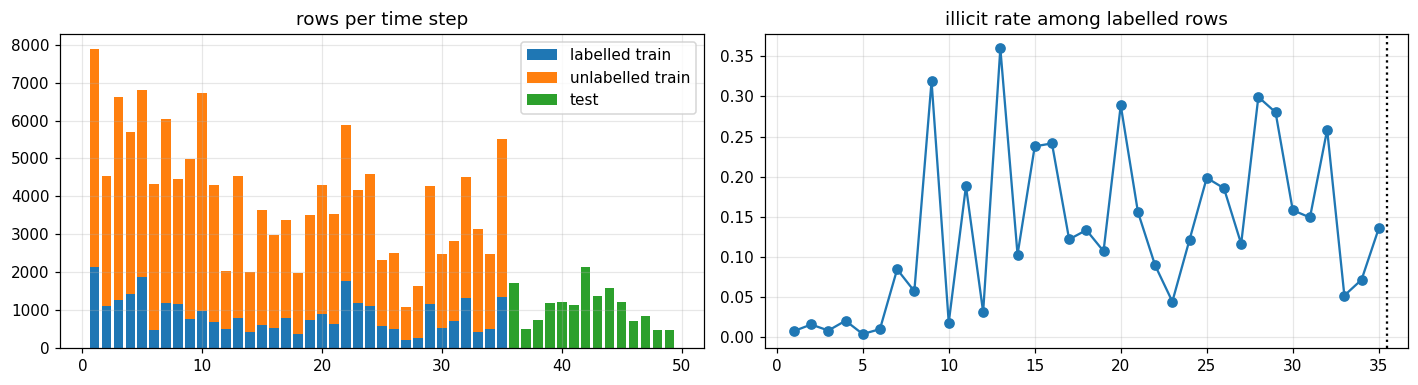

mean rows per step | train 4051 | test 1095


In [6]:
prof = (pd.DataFrame({"step": T, "labelled": ~np.isnan(Y), "illicit": np.nan_to_num(Y),
                      "is_test": IS_TEST.astype(int)})
        .groupby("step").agg(rows=("labelled", "size"), labelled=("labelled", "sum"),
                             illicit=("illicit", "sum"), is_test=("is_test", "max")))
prof["unlabelled_train"] = prof["rows"] - prof["labelled"] - prof["is_test"] * prof["rows"]
prof["illicit_rate"] = prof["illicit"] / prof["labelled"].replace(0, np.nan)
display(prof.round(3).T)

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
first_test = T[TEST_POS].min()
ax[0].bar(prof.index, prof["labelled"], label="labelled train")
ax[0].bar(prof.index, prof["unlabelled_train"], bottom=prof["labelled"], label="unlabelled train")
ax[0].bar(prof.index, prof["is_test"] * prof["rows"], label="test")
ax[0].set_title("rows per time step"); ax[0].legend()
ax[1].plot(prof.index, prof["illicit_rate"], marker="o"); ax[1].axvline(first_test - 0.5, color="k", ls=":")
ax[1].set_title("illicit rate among labelled rows"); plt.tight_layout(); plt.show()

DIAG["rows_per_step_train_mean"] = float(prof.loc[prof.is_test == 0, "rows"].mean())
DIAG["rows_per_step_test_mean"]  = float(prof.loc[prof.is_test == 1, "rows"].mean())
print("mean rows per step | train %.0f | test %.0f" % (DIAG["rows_per_step_train_mean"], DIAG["rows_per_step_test_mean"]))

### 2.2 Why is the test graph sparser? Missing nodes, missing edges, or a really sparser network?

The edge list contains transactions that are **not** in either file ("absent" nodes). For every row, `deg_full` counts every neighbour in the edge list and `deg_obs` counts only neighbours present in the files (what any graph feature can use). Per group, `mean deg_obs = mean deg_full x retention`, where retention is the share of edge ends going to a present node. So a drop in observed degree is either a drop in `deg_full` (sparser network) or a drop in retention (neighbours missing from the files). Absent nodes are assigned to a time step through their present neighbours (edges never cross steps).

In [ ]:
# Edge list over ALL ids (present or absent): unique undirected pairs, no self loops
a_ = edges["txId1"].to_numpy(); b_ = edges["txId2"].to_numpy()
pr = pd.DataFrame({"lo": np.minimum(a_, b_), "hi": np.maximum(a_, b_)})
pr = pr[pr["lo"] != pr["hi"]].drop_duplicates().reset_index(drop=True)
pr["lo_in"] = pr["lo"].isin(ALL["txId"]); pr["hi_in"] = pr["hi"].isin(ALL["txId"])

deg_full_s = pd.concat([pr["lo"], pr["hi"]]).value_counts()          # full degree of every id in the edge list
deg_full = ALL["txId"].map(deg_full_s).fillna(0).to_numpy()
assert (und_deg <= deg_full).all()

# Absent nodes and the time step they belong to (through a present neighbour)
half = pr[pr["lo_in"] ^ pr["hi_in"]]                                # edges with exactly one present end
pres_id = np.where(half["lo_in"], half["lo"], half["hi"])
abs_id  = np.where(half["lo_in"], half["hi"], half["lo"])
step_of = pd.Series(T, index=ALL["txId"].to_numpy())
ab = (pd.DataFrame({"absent": abs_id, "step": step_of.reindex(pres_id).to_numpy()})
      .groupby("absent")["step"].agg(n_steps="nunique", step="first"))
ab["deg_full"] = deg_full_s.reindex(ab.index).to_numpy()
absent_all = pd.unique(np.concatenate([pr.loc[~pr["lo_in"], "lo"], pr.loc[~pr["hi_in"], "hi"]]))
print(f"present rows: {N:,} | absent ids in the edge list: {len(absent_all):,}")
print(f"absent ids placed in a step through a present neighbour: {len(ab):,} | "
      f"unplaced (only linked to other absent ids): {len(absent_all) - len(ab):,} | "
      f"linked to more than one step: {int((ab['n_steps'] > 1).sum())}")

present rows: 157,101 | absent ids in the edge list: 46,668
absent ids placed in a step through a present neighbour: 17,897 | unplaced (only linked to other absent ids): 28,771 | linked to more than one step: 0


,rows,mean_full,mean_obs,iso_obs,iso_true,iso_missing,retention,coverage_placed_only
step,,,,,,,,
1,7880,2.326,2.326,0.000,0.0,0.000,1.000,1.000
2,4544,2.307,2.307,0.000,0.0,0.000,1.000,1.000
3,6621,2.512,2.512,0.000,0.0,0.000,1.000,1.000
4,5693,2.874,2.874,0.000,0.0,0.000,1.000,1.000
5,6803,2.535,2.535,0.000,0.0,0.000,1.000,1.000
6,4328,2.422,2.422,0.000,0.0,0.000,1.000,1.000
7,6048,2.398,2.398,0.000,0.0,0.000,1.000,1.000
8,4457,2.327,2.327,0.000,0.0,0.000,1.000,1.000
9,4996,2.378,2.378,0.000,0.0,0.000,1.000,1.000


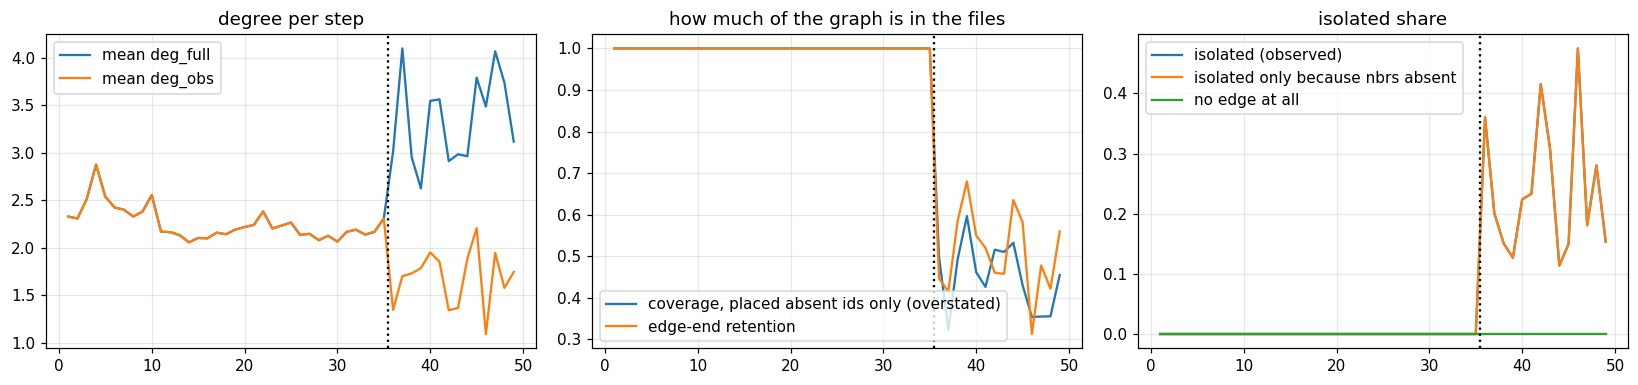

In [17]:
# Per-step table
df = pd.DataFrame({"step": T, "full": deg_full, "obs": und_deg})
df["iso_obs"]     = df["obs"] == 0                                  # isolated in the observed graph
df["iso_true"]    = df["full"] == 0                                 # no edge at all in the edge list
df["iso_missing"] = (df["obs"] == 0) & (df["full"] > 0)             # isolated only because its neighbours are absent
step_tab = df.groupby("step").agg(rows=("obs", "size"), mean_full=("full", "mean"), mean_obs=("obs", "mean"),
                                  iso_obs=("iso_obs", "mean"), iso_true=("iso_true", "mean"),
                                  iso_missing=("iso_missing", "mean"), sum_full=("full", "sum"), sum_obs=("obs", "sum"))
step_tab["retention"] = step_tab["sum_obs"] / step_tab["sum_full"].replace(0, np.nan)
present_in_edges = pd.Series((deg_full > 0).astype(int)).groupby(T).sum()      # present rows that appear in the edge list
absent_per_step = ab.groupby("step").size()
step_tab["coverage_placed_only"] = present_in_edges / (present_in_edges + absent_per_step.reindex(step_tab.index).fillna(0))
step_tab = step_tab.drop(columns=["sum_full", "sum_obs"])
display(step_tab.round(3))

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].plot(step_tab.index, step_tab["mean_full"], label="mean deg_full"); ax[0].plot(step_tab.index, step_tab["mean_obs"], label="mean deg_obs")
ax[0].set_title("degree per step"); ax[0].legend()
ax[1].plot(step_tab.index, step_tab["coverage_placed_only"], label="coverage, placed absent ids only (overstated)")
ax[1].plot(step_tab.index, step_tab["retention"], label="edge-end retention"); ax[1].set_title("how much of the graph is in the files"); ax[1].legend()
ax[2].plot(step_tab.index, step_tab["iso_obs"], label="isolated (observed)"); ax[2].plot(step_tab.index, step_tab["iso_missing"], label="isolated only because nbrs absent")
ax[2].plot(step_tab.index, step_tab["iso_true"], label="no edge at all"); ax[2].set_title("isolated share"); ax[2].legend()
for x in ax: x.axvline(first_test - 0.5, color="k", ls=":")
plt.tight_layout(); plt.show()

In [18]:
# Group summary: train labelled / train unlabelled / train all / test
GROUPS = {"train labelled": LAB, "train unlabelled": UNK, "train all": TRAIN_ROWS, "test": TEST_POS}
rows_ = []
for g, idx in GROUPS.items():
    rows_.append(dict(group=g, rows=len(idx), mean_deg_full=deg_full[idx].mean(), mean_deg_obs=und_deg[idx].mean(),
                      retention=und_deg[idx].sum() / deg_full[idx].sum(),
                      iso_obs=(und_deg[idx] == 0).mean(), iso_true=(deg_full[idx] == 0).mean(),
                      iso_only_missing_nbrs=((und_deg[idx] == 0) & (deg_full[idx] > 0)).mean()))
grp = pd.DataFrame(rows_).set_index("group")
display(grp.round(3))

tr, te = grp.loc["train all"], grp.loc["test"]
# exact log decomposition of the observed-degree drop: ln(obs) = ln(full) + ln(retention)
d_obs  = np.log(te.mean_deg_obs / tr.mean_deg_obs)
d_full = np.log(te.mean_deg_full / tr.mean_deg_full)
d_ret  = np.log(te.retention / tr.retention)
print(f"observed degree test/train = {te.mean_deg_obs / tr.mean_deg_obs:.3f}  (labelled train: {te.mean_deg_obs / grp.loc['train labelled'].mean_deg_obs:.3f})")
print(f"  of the log drop {d_obs:+.3f}: change in full degree {d_full:+.3f} | change in retention {d_ret:+.3f}")
print("  share explained by missing neighbours (retention): %.0f%%  (above 100%% means the test rows kept in the files have a higher full degree than train rows, which offsets part of the drop)" % (100 * d_ret / d_obs if d_obs != 0 else np.nan))
print(f"isolated rows in test: {te.iso_obs:.3f} observed = {te.iso_only_missing_nbrs:.3f} because neighbours are absent + {te.iso_true:.3f} with no edge at all")

DIAG.update(mean_deg_obs_train_all=float(tr.mean_deg_obs), mean_deg_obs_train_lab=float(grp.loc["train labelled"].mean_deg_obs),
            mean_deg_obs_test=float(te.mean_deg_obs), iso_obs_test=float(te.iso_obs),
            mean_deg_full_train=float(tr.mean_deg_full), mean_deg_full_test=float(te.mean_deg_full),
            retention_train=float(tr.retention), retention_test=float(te.retention),
            share_drop_from_retention=float(d_ret / d_obs) if d_obs != 0 else np.nan)

,rows,mean_deg_full,mean_deg_obs,retention,iso_obs,iso_true,iso_only_missing_nbrs
group,,,,,,,
train labelled,31235,2.866,2.866,1.000,0.000,0.0,0.000
train unlabelled,110537,2.143,2.143,1.000,0.000,0.0,0.000
train all,141772,2.302,2.302,1.000,0.000,0.0,0.000
test,15329,3.242,1.660,0.512,0.254,0.0,0.254


observed degree test/train = 0.721  (labelled train: 0.579)
  of the log drop -0.327: change in full degree +0.342 | change in retention -0.669
  share explained by missing neighbours (retention): 205%  (above 100% means the test rows kept in the files have a higher full degree than train rows, which offsets part of the drop)
isolated rows in test: 0.254 observed = 0.254 because neighbours are absent + 0.000 with no edge at all


In [19]:
# total coverage and test-period population mean degree
n_pres_te = int(IS_TEST.sum()); n_abs_all = len(absent_all)
placed_te = ab[ab["step"] >= first_test]
n_abs_te_placed = len(placed_te); n_unplaced = n_abs_all - len(ab)
cov_total_lo = n_pres_te / (n_pres_te + n_abs_te_placed + n_unplaced)      # all unplaced ids counted as test-period
cov_total_hi = n_pres_te / (n_pres_te + n_abs_te_placed)                   # unplaced ids counted as train-period
print(f"test rows present: {n_pres_te:,} | absent ids placed in test steps: {n_abs_te_placed:,} | absent ids that cannot be placed: {n_unplaced:,}")
print(f"test-period node coverage: between {cov_total_lo:.3f} and {cov_total_hi:.3f}")

# mean full degree of the test-period population
ends_present_te = deg_full_s.reindex(ALL.loc[IS_TEST, "txId"]).fillna(0).sum()
ends_abs_te = placed_te["deg_full"].sum()
pop_mean_placed = (ends_present_te + ends_abs_te) / (n_pres_te + n_abs_te_placed)      # unplaced ids left out (upper bound)
pop_mean_all = (2 * len(pr) - deg_full[TRAIN_ROWS].sum()) / (n_pres_te + n_abs_all)    # everything that is not a present train row
pop_mean_train = deg_full[TRAIN_ROWS].mean()
print(f"mean degree, test-period population: {pop_mean_placed:.2f} (placed ids only) to {pop_mean_all:.2f} (all non-train-present ids)")
print(f"mean degree, present train rows: {pop_mean_train:.2f} | present test rows (full degree): {deg_full[TEST_POS].mean():.2f} | present test rows (observed): {und_deg[TEST_POS].mean():.2f}")
print("If the population mean is close to the train value, the real network did not get sparser: the files simply contain a degree-biased sample of test-period nodes.")
DIAG.update(test_coverage_lo=float(cov_total_lo), test_coverage_hi=float(cov_total_hi),
            pop_mean_deg_test_placed=float(pop_mean_placed), pop_mean_deg_test_all=float(pop_mean_all))

test rows present: 15,329 | absent ids placed in test steps: 17,897 | absent ids that cannot be placed: 28,771
test-period node coverage: between 0.247 and 0.461
mean degree, test-period population: 2.73 (placed ids only) to 2.30 (all non-train-present ids)
mean degree, present train rows: 2.30 | present test rows (full degree): 3.24 | present test rows (observed): 1.66
If the population mean is close to the train value, the real network did not get sparser: the files simply contain a degree-biased sample of test-period nodes.


### 2.3 Is the missing part a random sample of nodes?

If absent nodes look like present ones (same degree distribution) and the loss is similar in every test step, the files look like a random node sample. If not, the loss is selective and independent node dropout is only an approximation.

full degree (edge-list degree) of nodes that appear in at least one edge:


,n,mean,median,share_deg1,share_deg_ge5
"present, train",141772.0,2.302,2.0,0.325,0.043
"absent, train steps",0.0,NaN,NaN,NaN,NaN
"present, test",15329.0,3.242,2.0,0.417,0.091
"absent, test steps",17897.0,2.296,2.0,0.404,0.046


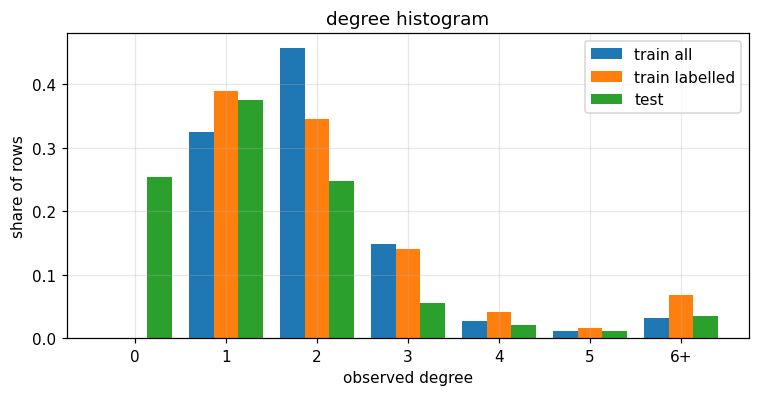

In [10]:
def deg_stats(x):
    x = np.asarray(x, dtype=float)
    return dict(n=len(x), mean=x.mean(), median=np.median(x), share_deg1=(x == 1).mean(), share_deg_ge5=(x >= 5).mean())

pres_conn = deg_full > 0
tr_mask, te_mask = ~IS_TEST, IS_TEST
ab_tr = ab.loc[ab["step"] <= T[TRAIN_ROWS].max(), "deg_full"]; ab_te = ab.loc[ab["step"] >= first_test, "deg_full"]
sel_tab = pd.DataFrame({"present, train": deg_stats(deg_full[tr_mask & pres_conn]), "absent, train steps": deg_stats(ab_tr),
                        "present, test": deg_stats(deg_full[te_mask & pres_conn]), "absent, test steps": deg_stats(ab_te)}).T
print("full degree (edge-list degree) of nodes that appear in at least one edge:")
display(sel_tab.round(3))

# observed degree histogram: train all vs test
def hist_share(d, kmax=6):
    d = np.minimum(d, kmax).astype(int)
    return np.bincount(d, minlength=kmax + 1) / len(d)
h_tr, h_lab, h_te = hist_share(und_deg[TRAIN_ROWS]), hist_share(und_deg[LAB]), hist_share(und_deg[TEST_POS])
labels_ = [str(k) for k in range(6)] + ["6+"]
x = np.arange(len(labels_)); w = 0.27
plt.figure(figsize=(8, 3.6))
plt.bar(x - w, h_tr, w, label="train all"); plt.bar(x, h_lab, w, label="train labelled"); plt.bar(x + w, h_te, w, label="test")
plt.xticks(x, labels_); plt.xlabel("observed degree"); plt.ylabel("share of rows"); plt.legend(); plt.title("degree histogram"); plt.show()

### 2.4 Does independent node dropout reproduce the test graph?

If each neighbour of a training row is kept with probability `keep`, its degree is Binomial(d, keep): mean degree = `keep` x mean(d) and isolated share = mean((1 - keep)^d). Two populations are checked: **all training rows** and **labelled rows** (the rows a model trains on, which are denser). For each, the `keep` that matches the test mean degree is compared on isolated share, and the `keep` that matches the test isolated share is compared on mean degree. One `keep` matching both would make node dropout a good simulation.

population,train all,train labelled
mean_deg,2.302,2.866
keep_matching_mean,0.721,0.579
drop_q_matching_mean,0.279,0.421
pred_iso_at_that_keep,0.130,0.237
real_test_iso,0.254,0.254
keep_matching_iso,0.550,0.557
pred_mean_at_that_keep,1.266,1.597
real_test_mean,1.660,1.660


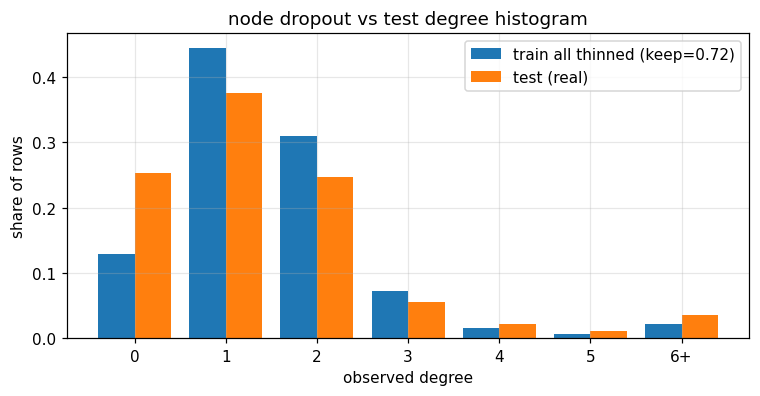

thinning ALL training rows to the test mean degree predicts 0.130 isolated rows against 0.254 in the real test -> it does NOT reproduce the test graph (not adopted).


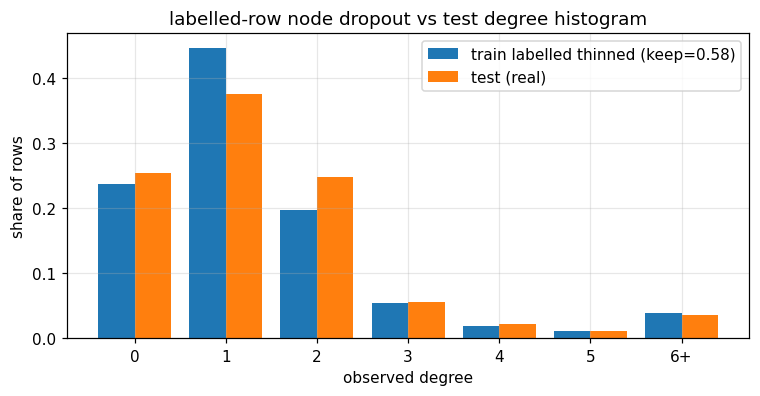

histogram gap (thinned labelled minus test), degree 0..6+: [-0.017  0.071 -0.05  -0.003 -0.003 -0.001  0.003]


In [21]:
def pred_iso(d, keep):  return float(np.mean((1.0 - keep) ** d))
def pred_mean(d, keep): return float(keep * d.mean())

def keep_for_iso(d, target_iso):
    lo, hi = 0.0, 1.0                                         # isolated share falls as keep rises
    for _ in range(60):
        mid = (lo + hi) / 2
        if pred_iso(d, mid) > target_iso: lo = mid
        else: hi = mid
    return (lo + hi) / 2

tgt_mean, tgt_iso = und_deg[TEST_POS].mean(), (und_deg[TEST_POS] == 0).mean()
fit_rows = []
for name, idx in {"train all": TRAIN_ROWS, "train labelled": LAB}.items():
    d = und_deg[idx]
    k_mean = min(1.0, tgt_mean / d.mean())
    k_iso = keep_for_iso(d, tgt_iso)
    fit_rows.append(dict(population=name, mean_deg=d.mean(), keep_matching_mean=k_mean, drop_q_matching_mean=1 - k_mean,
                         pred_iso_at_that_keep=pred_iso(d, k_mean), real_test_iso=tgt_iso,
                         keep_matching_iso=k_iso, pred_mean_at_that_keep=pred_mean(d, k_iso), real_test_mean=tgt_mean))
fit = pd.DataFrame(fit_rows).set_index("population")
display(fit.round(3).T)

# predicted degree histogram after thinning (mean-matched keep) vs the real test histogram
d = und_deg[TRAIN_ROWS]; k_mean = fit.loc["train all", "keep_matching_mean"]
x = np.arange(7)
pred_hist = np.array([np.mean(binom.pmf(k, d, k_mean)) for k in range(6)] + [np.mean(binom.sf(5, d, k_mean))])
plt.figure(figsize=(8, 3.6))
plt.bar(x - 0.2, pred_hist, 0.4, label=f"train all thinned (keep={k_mean:.2f})"); plt.bar(x + 0.2, h_te, 0.4, label="test (real)")
plt.xticks(x, labels_); plt.xlabel("observed degree"); plt.ylabel("share of rows"); plt.legend(); plt.title("node dropout vs test degree histogram"); plt.show()
_p = fit.loc['train all','pred_iso_at_that_keep']
print(f"thinning ALL training rows to the test mean degree predicts {_p:.3f} isolated rows against {tgt_iso:.3f} in the real test -> " + ("it does NOT reproduce the test graph (not adopted)." if abs(_p - tgt_iso) > 0.03 else "it reproduces the isolated share."))

# NEW (patch): same histogram for labelled rows (the rows the model actually trains on)
dl = und_deg[LAB]; k_lab = fit.loc["train labelled", "keep_matching_mean"]
pred_hist_lab = np.array([np.mean(binom.pmf(k, dl, k_lab)) for k in range(6)] + [np.mean(binom.sf(5, dl, k_lab))])
plt.figure(figsize=(8, 3.6))
plt.bar(x - 0.2, pred_hist_lab, 0.4, label=f"train labelled thinned (keep={k_lab:.2f})"); plt.bar(x + 0.2, h_te, 0.4, label="test (real)")
plt.xticks(x, labels_); plt.xlabel("observed degree"); plt.ylabel("share of rows"); plt.legend(); plt.title("labelled-row node dropout vs test degree histogram"); plt.show()
print("histogram gap (thinned labelled minus test), degree 0..6+:", np.round(pred_hist_lab - h_te, 3))

DIAG.update(drop_q_mean_match_all=float(fit.loc["train all", "drop_q_matching_mean"]),
            drop_q_mean_match_lab=float(fit.loc["train labelled", "drop_q_matching_mean"]),
            pred_iso_mean_match_all=float(fit.loc["train all", "pred_iso_at_that_keep"]),
            pred_iso_mean_match_lab=float(fit.loc["train labelled", "pred_iso_at_that_keep"]),
            real_iso_test=float(tgt_iso))

### 2.5 Homophily (labelled training rows only)

Among edges whose two ends are both labelled, how often do the labels differ (`cross share`)?

In [12]:
U = sp.triu(A_und, k=1).tocoo()
m = ~np.isnan(Y[U.row]) & ~np.isnan(Y[U.col])
ia, ib = U.row[m], U.col[m]
ya, yb = Y[ia].astype(int), Y[ib].astype(int)
cross_obs = float((ya != yb).mean())
p_end = float(np.concatenate([ya, yb]).mean())
cross_random = 2 * p_end * (1 - p_end)

# within-step permutation null
pos2lab = -np.ones(N, dtype=int); pos2lab[LAB] = np.arange(len(LAB))
la, lb = pos2lab[ia], pos2lab[ib]
y_lab = Y[LAB].astype(int); step_groups = [np.where(T[LAB] == t)[0] for t in np.unique(T[LAB])]
perm_cross = np.empty(500)
for r in range(len(perm_cross)):
    yp = y_lab.copy()
    for g in step_groups: yp[g] = rng.permutation(yp[g])
    perm_cross[r] = (yp[la] != yp[lb]).mean()
z = (cross_obs - perm_cross.mean()) / perm_cross.std()

# neighbour label rates, both directions of every edge
src_y = np.concatenate([ya, yb]); nb_y = np.concatenate([yb, ya])
p_ill_given_ill  = float(nb_y[src_y == 1].mean()); p_ill_given_lic = float(nb_y[src_y == 0].mean())
has_lab_nb = np.zeros(N, bool); has_lab_nb[ia] = True; has_lab_nb[ib] = True

print(f"labelled-labelled edges: {len(ia):,}")
print(f"cross-label share: observed {cross_obs:.3f} | expected if unrelated 2p(1-p) {cross_random:.3f} | within-step permutation {perm_cross.mean():.3f} +- {perm_cross.std():.3f} (z = {z:.1f})")
print(f"P(neighbour illicit | node illicit) = {p_ill_given_ill:.3f} | P(neighbour illicit | node licit) = {p_ill_given_lic:.3f} | base rate {p_end:.3f}")
print(f"labelled rows with at least one labelled neighbour: {has_lab_nb[LAB].mean():.3f}")
DIAG.update(cross_share_obs=cross_obs, cross_share_random=cross_random, homophily_z=float(z),
            p_ill_given_ill=p_ill_given_ill, p_ill_given_lic=p_ill_given_lic)

labelled-labelled edges: 23,900
cross-label share: observed 0.053 | expected if unrelated 2p(1-p) 0.117 | within-step permutation 0.181 +- 0.005 (z = -23.4)
P(neighbour illicit | node illicit) = 0.574 | P(neighbour illicit | node licit) = 0.028 | base rate 0.062
labelled rows with at least one labelled neighbour: 0.782


### 2.6 Feature drift (label-free)

Early versus late training steps, per feature, with the KS statistic and the PSI (bins from the early rows; below 0.1 small, 0.1-0.25 moderate, above 0.25 large). Train-vs-test KS is descriptive only (separate time ranges can always be told apart). The adversarial check uses **early vs late inside training with whole steps held out**, so it scores high only for a systematic trend.

early = steps 1-17 (80,989 rows) | late = steps 18-35 (60,783 rows)


,ks_early_late,psi_early_late,ks_train_test
feature,,,
feat_101,0.998,7.775,0.995
feat_136,0.996,7.909,0.996
feat_103,0.996,7.596,0.994
feat_100,0.994,7.147,0.992
feat_139,0.954,8.003,0.966
feat_137,0.922,7.994,0.929
feat_142,0.480,1.176,0.520
feat_106,0.468,0.783,0.550
feat_2,0.464,1.163,0.664


features with PSI > 0.25: 20 | PSI 0.1-0.25: 17 | KS > 0.2: 20
adversarial AUC, early vs late, grouped by step: 0.999   (0.5 = no systematic shift)
time-index features (KS early/late > 0.8 and |Spearman(step, per-step median)| > 0.9): ['feat_101', 'feat_136', 'feat_103', 'feat_100', 'feat_139', 'feat_137']
KS ranking without them:


,ks_early_late,psi_early_late,ks_train_test
feature,,,
feat_142,0.480,1.176,0.520
feat_106,0.468,0.783,0.550
feat_2,0.464,1.163,0.664
feat_109,0.405,0.710,0.648
feat_107,0.400,0.771,0.632
feat_3,0.386,0.616,0.463
feat_112,0.372,0.599,0.417
feat_148,0.369,0.570,0.435
feat_115,0.364,0.598,0.517


adversarial AUC without time-index features: 0.933  (with them: 0.999)


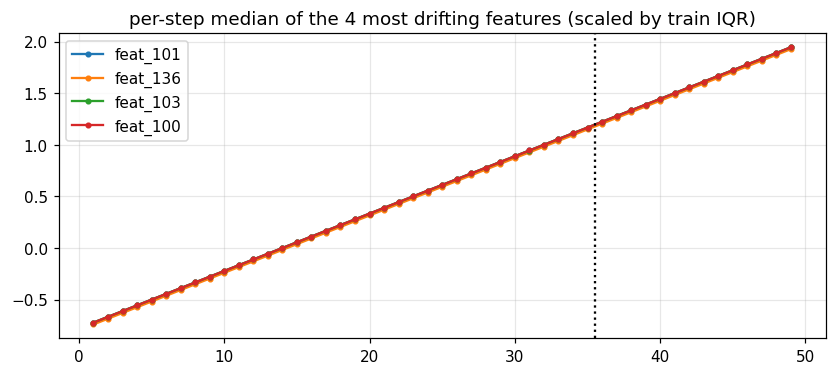

In [ ]:
mid = int(T[TRAIN_ROWS].max()) // 2
EARLY = TRAIN_ROWS[T[TRAIN_ROWS] <= mid]; LATE = TRAIN_ROWS[T[TRAIN_ROWS] > mid]
Xf = ALL[feat_all].to_numpy(np.float64)

def psi(e, l, bins=10):
    inner = np.unique(np.quantile(e, np.linspace(0, 1, bins + 1)[1:-1]))
    if len(inner) < 2: return np.nan                              # (near-)constant feature
    pe = np.bincount(np.searchsorted(inner, e, side="right"), minlength=len(inner) + 1) / len(e)
    pl = np.bincount(np.searchsorted(inner, l, side="right"), minlength=len(inner) + 1) / len(l)
    pe, pl = np.clip(pe, 1e-4, None), np.clip(pl, 1e-4, None)
    return float(np.sum((pl - pe) * np.log(pl / pe)))

rows_ = []
for j, cn in enumerate(feat_all):
    e, l = Xf[EARLY, j], Xf[LATE, j]
    rows_.append(dict(feature=cn, ks_early_late=ks_2samp(e, l).statistic, psi_early_late=psi(e, l),
                      ks_train_test=ks_2samp(Xf[TRAIN_ROWS, j], Xf[TEST_POS, j]).statistic))
drift = pd.DataFrame(rows_).set_index("feature").sort_values("ks_early_late", ascending=False)
print(f"early = steps 1-{mid} ({len(EARLY):,} rows) | late = steps {mid + 1}-{T[TRAIN_ROWS].max()} ({len(LATE):,} rows)")
display(drift.head(15).round(3))
print(f"features with PSI > 0.25: {(drift.psi_early_late > 0.25).sum()} | PSI 0.1-0.25: {drift.psi_early_late.between(0.1, 0.25).sum()} | "
      f"KS > 0.2: {(drift.ks_early_late > 0.2).sum()}")

# adversarial: early vs late, grouped by step so held-out steps are unseen
sel = rng.choice(TRAIN_ROWS, size=min(40000, len(TRAIN_ROWS)), replace=False)
Xs, y_adv, g_adv = Xf[sel], (T[sel] > mid).astype(int), T[sel]
oof = np.zeros(len(sel))
for a_idx, b_idx in GroupKFold(5).split(Xs, y_adv, groups=g_adv):
    oof[b_idx] = make_lgbm(RANDOM_STATE).fit(Xs[a_idx], y_adv[a_idx]).predict_proba(Xs[b_idx])[:, 1]
adv_auc = roc_auc_score(y_adv, oof)
print(f"adversarial AUC, early vs late, grouped by step: {adv_auc:.3f}   (0.5 = no systematic shift)")
DIAG.update(n_feat_psi_gt_025=int((drift.psi_early_late > 0.25).sum()), adversarial_auc_early_late=float(adv_auc))

# detect time-index features (monotone per-step median AND near-total early/late separation), then repeat without them
med_all = pd.DataFrame(Xf[TRAIN_ROWS], columns=feat_all).groupby(T[TRAIN_ROWS]).median()
step_rho = med_all.apply(lambda s: abs(spearmanr(med_all.index, s)[0]) if s.nunique() > 1 else 0.0)
TIME_IDX = [c for c in drift.index if drift.loc[c, "ks_early_late"] > 0.8 and step_rho[c] > 0.9]
print(f"time-index features (KS early/late > 0.8 and |Spearman(step, per-step median)| > 0.9): {TIME_IDX}")
rest = drift.drop(index=TIME_IDX)
print("KS ranking without them:"); display(rest.head(10).round(3))
keep_j = [j for j, c in enumerate(feat_all) if c not in TIME_IDX]
oof2 = np.zeros(len(sel))
for a_idx, b_idx in GroupKFold(5).split(Xs, y_adv, groups=g_adv):
    oof2[b_idx] = make_lgbm(RANDOM_STATE).fit(Xs[a_idx][:, keep_j], y_adv[a_idx]).predict_proba(Xs[b_idx][:, keep_j])[:, 1]
adv_auc_wo = roc_auc_score(y_adv, oof2)
print(f"adversarial AUC without time-index features: {adv_auc_wo:.3f}  (with them: {adv_auc:.3f})")
DIAG.update(time_index_features=",".join(TIME_IDX), adversarial_auc_without_time_idx=float(adv_auc_wo))

# do the most drifting features keep moving into the test period? median per step, scaled by the train spread
top4 = list(drift.index[:4]); j4 = [feat_all.index(c) for c in top4]
med = pd.DataFrame(Xf[:, j4], columns=top4).groupby(T).median()
ref = Xf[TRAIN_ROWS][:, j4]
zmed = (med - np.median(ref, axis=0)) / (np.subtract(*np.percentile(ref, [75, 25], axis=0)) + 1e-9)
ax = zmed.plot(figsize=(9, 3.6), marker=".", title="per-step median of the 4 most drifting features (scaled by train IQR)")
ax.axvline(first_test - 0.5, color="k", ls=":"); plt.show()

### 2.7 Concept drift (labelled training rows only)

Does a model trained on early steps lose accuracy on later steps? Fit on all labelled rows up to an origin step, score each later step separately (3 seeds averaged), at two origins. A per-step AUC is reported only for steps with at least 10 illicit and 10 licit rows. Descriptive only.

step,13,14,15,16,17,18,19,20,21,22,...,26,27,28,29,30,31,32,33,34,35
origin,,,,,,,,,,,,,,,,,,,,,
12,0.998,0.997,1.0,0.99,0.997,0.999,0.993,0.988,0.988,0.992,...,0.904,1.0,1.0,0.684,0.987,0.703,0.755,0.952,0.994,0.994
20,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.995,0.999,...,0.924,1.0,1.0,0.690,0.990,0.709,0.759,0.993,0.999,0.997


distance,1-4,13-16,17-25,5-8,9-12
origin,,,,,
12,0.997,0.977,0.797,0.993,0.915
20,0.926,0.997,NaN,0.983,0.747


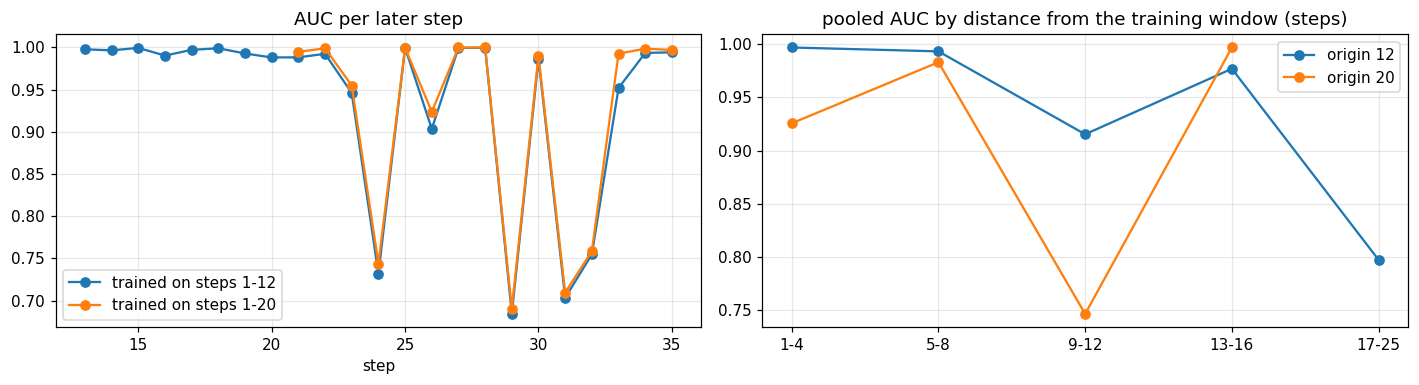

origin 12: Spearman(distance, per-step AUC) = -0.37 (p=0.08, 23 steps)
origin 20: Spearman(distance, per-step AUC) = -0.10 (p=0.73, 15 steps)


In [14]:
X_diag = ALL[feat_all].to_numpy(np.float32)
res, store = [], {}
for origin in (12, 20):
    trn = LAB[T[LAB] <= origin]; evl = LAB[T[LAB] > origin]
    p = predict_seed_avg(X_diag[trn], Y[trn].astype(int), X_diag[evl])
    store[origin] = (evl, p)
    for t in np.unique(T[evl]):
        mk = T[evl] == t
        res.append(dict(origin=origin, step=t, distance=t - origin, illicit=int(Y[evl][mk].sum()),
                        auc=auc_or_nan(Y[evl][mk].astype(int), p[mk])))
cd = pd.DataFrame(res)
display(cd.pivot(index="step", columns="origin", values="auc").round(3).T)

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
for origin in (12, 20):
    s = cd[cd.origin == origin]; ax[0].plot(s.step, s.auc, marker="o", label=f"trained on steps 1-{origin}")
ax[0].set_title("AUC per later step"); ax[0].set_xlabel("step"); ax[0].legend()

bins_ = [(1, 4), (5, 8), (9, 12), (13, 16), (17, 25)]
bucket_rows = []
for origin in (12, 20):
    evl, p = store[origin]; dist = T[evl] - origin; yv = Y[evl].astype(int)
    for lo_, hi_ in bins_:
        mk = (dist >= lo_) & (dist <= hi_)
        if mk.sum() and yv[mk].sum() >= 10 and (1 - yv[mk]).sum() >= 10:
            bucket_rows.append(dict(origin=origin, distance=f"{lo_}-{hi_}", auc=auc(yv[mk], p[mk]), illicit=int(yv[mk].sum())))
bucket = pd.DataFrame(bucket_rows)
display(bucket.pivot(index="origin", columns="distance", values="auc").round(3))
for origin in (12, 20):
    s = bucket[bucket.origin == origin]; ax[1].plot(s.distance, s.auc, marker="o", label=f"origin {origin}")
ax[1].set_title("pooled AUC by distance from the training window (steps)"); ax[1].legend(); plt.tight_layout(); plt.show()

for origin in (12, 20):
    s = cd[cd.origin == origin].dropna(subset=["auc"])
    rho, pval = spearmanr(s.distance, s.auc)
    print(f"origin {origin}: Spearman(distance, per-step AUC) = {rho:+.2f} (p={pval:.2f}, {len(s)} steps)")
    DIAG[f"concept_drift_spearman_origin{origin}"] = float(rho)

In [15]:
print("DIAG summary:")
display(pd.Series(DIAG).to_frame("value"))

DIAG summary:


,value
rows_per_step_train_mean,4050.628571
rows_per_step_test_mean,1094.928571
mean_deg_obs_train_all,2.302204
mean_deg_obs_train_lab,2.865632
mean_deg_obs_test,1.660121
iso_obs_test,0.253833
mean_deg_full_train,2.302204
mean_deg_full_test,3.241764
retention_train,1.000000
retention_test,0.512104


### Section 2 summary

| Question | Result | Meaning |
|---|---|---|
| Is train fully observed? | Retention 1.000, 0% isolated, mean degree 2.30 | Every neighbour of a train row is in the files. |
| Why is test sparser? | Retention 0.512. All 25.4% isolated rows are isolated only because their neighbours are absent. | The files are sparse, not the network. |
| Is the real network sparser? | Test-period population mean degree 2.30 to 2.73, against 2.30 in train. | About the same density. |
| What do the files contain? | Test coverage 25% to 46%. The 15,329 present test rows have full degree 3.24 against about 2.3 for the population. | A degree-biased, clustered sample; independent dropout is only an approximation. |
| Does the loss vary by step? | Isolated share 11% to 47%, retention 0.31 to 0.68. Steps 36, 42 and 46 are worst. | Test scores will be noisy across steps. |
| Does node dropout reproduce test? | Thinning all train rows predicts 13% isolated against 25.4%: fails. Thinning labelled rows at q = 0.42 predicts 23.7% and matches the tails, but gives too many degree-1 rows (+0.071) and too few degree-2 rows (-0.050). | Dropout on labelled rows is a decent, imperfect simulation. |
| Homophily | Cross-label share 0.053, against 0.117 (analytic null) and 0.181 (within-step permutation), z = -23. P(neighbour illicit given illicit) = 0.574, against 0.028 for a licit node. | Strong homophily, so neighbour information is worth testing. |
| Feature drift | 20 features have PSI above 0.25. Six (feat_100, 101, 103, 136, 137, 139) move in a straight line with the step and continue into test. Adversarial AUC 0.999, and 0.933 without those six. | Dropping the six does not remove the drift. |
| Concept drift | Spearman of distance against AUC is -0.37 (origin 12) and -0.10 (origin 20). Both origins dip at the same steps: 29, 31, 32 (AUC about 0.68 to 0.76) and 26 (about 0.90). | No smooth decay; the hard steps are specific. |

(The "205% explained by retention" figure is expected: the present test rows have higher full degree, which offsets part of the drop from lost neighbours.)

**Decisions**
1. **Simulate test sparsity with node dropout on labelled rows only**, q = 0.42 (sensitivity q = 0.35 and 0.50). Thinning all train rows is not adopted.
2. **Treat the six time-index features as one pre-defined drop test** in section 6, not one at a time.
3. **No recency weights or sliding window**: the dips are step-specific and the correlation with distance is weak.
4. **Test graph features** in section 6, since homophily is strong. Isolated rows (25% of test) must be handled.
5. Expect fold scores to swing by step (hard steps 29, 31, 32), and expect the test score to be lower and noisier than validation.

## 3. Duplicate and near-duplicate features

Redundant columns add nothing for tree models and split importance between copies. Everything is computed on all training rows (no labels) and the full data. A column is dropped only if it is redundant with a column that is kept: constant, an exact copy, or `|Pearson|` **and** `|Spearman|` both at least 0.99999 (the lower index is kept). Pairs flagged by only one correlation are listed for review and **not** dropped. This is data cleaning, so it needs no baseline comparison.

In [24]:
THR = 0.99999
Xd = ALL.loc[TRAIN_ROWS, feat_all].to_numpy(np.float64)
p_ = len(feat_all)

# constants and near-constants
nuniq = pd.DataFrame(Xd).nunique().to_numpy()
constant_idx = np.where(nuniq <= 1)[0]
top_share = np.array([pd.Series(Xd[:, j]).value_counts(normalize=True).iloc[0] for j in range(p_)])
print(f"constant columns: {len(constant_idx)} | columns with one value in >= 99.9% of rows (kept, info only): {int((top_share >= 0.999).sum() - len(constant_idx))}")

# exact copies (hash of the full column, then verified)
def col_hash(v): return hashlib.md5(np.ascontiguousarray(v).tobytes()).hexdigest()
by_hash = {}
for j in range(p_): by_hash.setdefault(col_hash(Xd[:, j]), []).append(j)
exact_pair = set()
for js in by_hash.values():
    for k in range(1, len(js)):
        if np.array_equal(Xd[:, js[0]], Xd[:, js[k]]): exact_pair.add((js[0], js[k]))
print(f"exact-copy pairs (vs first occurrence): {len(exact_pair)}")

# correlation matrices on the full training rows (constants excluded)
ok = np.where(nuniq > 1)[0]
P = np.zeros((p_, p_)); S = np.zeros((p_, p_))
P[np.ix_(ok, ok)] = np.corrcoef(Xd[:, ok], rowvar=False)
S[np.ix_(ok, ok)] = np.corrcoef(pd.DataFrame(Xd[:, ok]).rank(axis=0).to_numpy(), rowvar=False)
iu, ju = np.triu_indices(p_, 1)
flag = (np.abs(P[iu, ju]) >= THR) | (np.abs(S[iu, ju]) >= THR)
cand = [(i, j) for i, j in zip(iu[flag], ju[flag])]
print(f"pairs flagged by Pearson or Spearman >= {THR}: {len(cand)}")

pair_rows = []
for i, j in cand:
    xi, xj = Xd[:, i], Xd[:, j]
    exact = (i, j) in exact_pair or np.array_equal(xi, xj)
    slope, icpt = np.polyfit(xi, xj, 1)
    rel_resid = float(np.abs(xj - (slope * xi + icpt)).max() / (xj.std() + 1e-12))     # worst-row deviation from a straight-line copy
    redundant = exact or (abs(P[i, j]) >= THR and abs(S[i, j]) >= THR)
    pair_rows.append(dict(keep_candidate=feat_all[i], other=feat_all[j], i=i, j=j, pearson=P[i, j], spearman=S[i, j],
                          exact=exact, max_rel_resid=rel_resid, redundant=redundant))
pairs_df = pd.DataFrame(pair_rows)

constant columns: 0 | columns with one value in >= 99.9% of rows (kept, info only): 1
exact-copy pairs (vs first occurrence): 0
pairs flagged by Pearson or Spearman >= 0.99999: 8


In [25]:
# Decide what to drop: walk the columns in order, drop one if it is redundant with a column already kept
drop_reason = {j: "constant" for j in constant_idx}
kept = [j for j in range(p_) if j not in drop_reason]
red = {} if pairs_df.empty else {(r.i, r.j) for r in pairs_df.itertuples() if r.redundant}
kept_final = []
for j in kept:
    partner = next((i for i in kept_final if (i, j) in red), None)
    if partner is None: kept_final.append(j)
    else: drop_reason[j] = f"redundant with {feat_all[partner]}"

DROPPED = [feat_all[j] for j in sorted(drop_reason)]
FEAT = [feat_all[j] for j in kept_final]
print(f"features: {p_} -> {len(FEAT)} (dropped {len(DROPPED)})")

drop_log = pd.DataFrame([dict(dropped=feat_all[j], reason=drop_reason[j]) for j in sorted(drop_reason)])
if not drop_log.empty and not pairs_df.empty:
    partner_names = drop_log["reason"].str.replace("redundant with ", "", regex=False)
    detail = pairs_df.set_index(["keep_candidate", "other"])[["pearson", "spearman", "exact", "max_rel_resid"]]
    drop_log = drop_log.join(pd.Series([detail.loc[(pn, d)].to_dict() if (pn, d) in detail.index else {} for pn, d in zip(partner_names, drop_log["dropped"])],
                                       name="detail").apply(pd.Series))
display(drop_log.round(7))

review = pairs_df[~pairs_df["redundant"]] if not pairs_df.empty else pairs_df
print(f"pairs flagged by only one correlation (kept, for review): {len(review)}")
if len(review): display(review[["keep_candidate", "other", "pearson", "spearman", "max_rel_resid"]].round(7))
drop_log.to_csv(f"{OUT_DIR}/dropped_features.csv", index=False)

features: 165 -> 164 (dropped 1)


,dropped,reason,pearson,spearman,exact,max_rel_resid
0,feat_30,redundant with feat_24,1.0,1.0,False,0.031329


pairs flagged by only one correlation (kept, for review): 7


,keep_candidate,other,pearson,spearman,max_rel_resid
0,feat_22,feat_28,1.000000,0.999983,0.195730
1,feat_23,feat_29,1.000000,0.999987,0.118105
3,feat_25,feat_31,1.000000,0.999986,0.160985
4,feat_58,feat_64,0.999992,0.994466,1.033166
5,feat_59,feat_65,1.000000,0.999203,0.108945
6,feat_60,feat_66,1.000000,0.999862,0.111899
7,feat_61,feat_67,1.000000,0.999151,0.111776


In [ ]:
# Sanity check (report only): do the dropped pairs still match in the test rows?
Xt = ALL.loc[TEST_POS, feat_all].to_numpy(np.float64)
bad = []
for r in drop_log.itertuples():
    if r.reason.startswith("redundant with"):
        a_name = r.reason.replace("redundant with ", ""); ja, jb = feat_all.index(a_name), feat_all.index(r.dropped)
        if Xt[:, ja].std() > 0 and Xt[:, jb].std() > 0:
            c_t = np.corrcoef(Xt[:, ja], Xt[:, jb])[0, 1]
            if abs(c_t) < THR: bad.append((a_name, r.dropped, round(float(c_t), 6)))
print("dropped pairs whose relationship does NOT hold in the test rows:", bad if bad else "none")

# Final base feature matrix used by every later section
X_BASE = ALL[FEAT].to_numpy(np.float32)
print("X_BASE shape:", X_BASE.shape)

dropped pairs whose relationship does NOT hold in the test rows: none
X_BASE shape: (157101, 164)


### Section 3 summary

| Check | Result |
|---|---|
| Starting features | 165 |
| Constant columns / exact-copy pairs | 0 / 0 |
| Near-constant columns (one value in at least 99.9% of rows) | 1 (kept, information only) |
| Pairs flagged by Pearson or Spearman at least 0.99999 | 8 |
| Features dropped | 1 (feat_30) |
| Final features | 164 (`X_BASE`: 157,101 rows by 164 columns) |

**Dropped:** feat_30, a linear copy of feat_24 (Pearson 1.0, Spearman 1.0, worst-row deviation 0.031 std); the relationship also holds in the test rows.

**Kept for review (one correlation only):**

| Kept | Other | Pearson | Spearman | Worst-row deviation (std) |
|---|---|---|---|---|
| feat_22 | feat_28 | 1.000000 | 0.999983 | 0.196 |
| feat_23 | feat_29 | 1.000000 | 0.999987 | 0.118 |
| feat_25 | feat_31 | 1.000000 | 0.999986 | 0.161 |
| feat_58 | feat_64 | 0.999992 | 0.994466 | 1.033 |
| feat_59 | feat_65 | 1.000000 | 0.999203 | 0.109 |
| feat_60 | feat_66 | 1.000000 | 0.999862 | 0.112 |
| feat_61 | feat_67 | 1.000000 | 0.999151 | 0.112 |

**Decisions.** Drop feat_30; keep the seven Pearson-only pairs (their rank orders differ and trees use ranks) and the near-constant column; make no other drop here.

**Observation.** Every flagged pair, including feat_24/feat_30, is offset by 6 columns, which looks like the same measure computed two ways (a local value and an aggregate). It was tested once in section 6 as group C. Dropping one feature of 165 is not expected to change scores.

## 4. Validation and evaluation design

Everything after this section is scored with the functions defined here, in the same way every time. The design: **ROC-AUC on seed-averaged predictions** as the only decision metric; five non-overlapping **rolling-origin folds** (D1-D5) with a gap of dropped steps between training and validation, plus a **frozen holdout**; enough illicit rows per window for a stable AUC; the **seed noise level** of the reference; one **decision rule** and one `evaluate` function for every experiment; and **test sparsity** simulated by node dropout (q = 0.42, sensitivity 0.35 and 0.50). Whole time steps only (edges never cross steps).

### 4.1 Folds and illicit counts

Training rows are the labelled rows of the training steps. Validation rows are the labelled rows of the validation steps. Gap steps are dropped from both.

,train_steps,gap_steps,val_steps,train_rows,train_illicit,val_rows,val_illicit,val_illicit_share,auc_se_if_0p9,enough
fold,,,,,,,,,,
D1,1-11,12-15,16-18,13164,655,1730,279,0.1613,0.0126,False
D2,1-14,15-18,19-21,14896,1005,2286,440,0.1925,0.0101,True
D3,1-17,18-21,22-24,16855,1379,4076,348,0.0854,0.0112,True
D4,1-20,21-24,25-27,18889,1771,1317,238,0.1807,0.0137,False
D5,1-23,24-27,28-31,22480,2082,2692,603,0.2240,0.0086,True
Holdout,1-27,28-31,32-35,24923,2457,3620,584,0.1613,0.0087,True


step,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35
labelled,2147,1117,1279,1440,1882,485,1203,1165,778,972,696,506,809,417,618,530,811,389,745,900,641,1763,1187,1126,594,517,206,284,1174,524,710,1323,441,515,1341
illicit,17,18,11,30,8,5,102,67,248,18,131,16,291,43,147,128,99,52,80,260,100,158,53,137,118,96,24,85,329,83,106,342,23,37,182


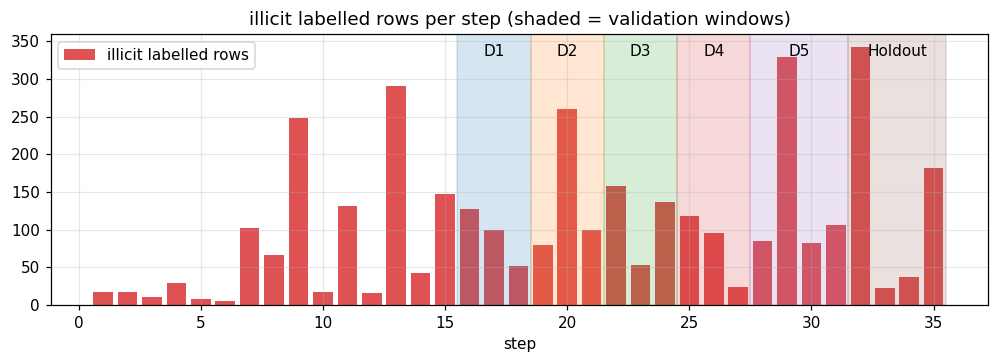

In [27]:
# Folds: name -> (train steps, gap steps, validation steps), all inclusive
FOLDS = {
    "D1": ((1, 11), (12, 15), (16, 18)),
    "D2": ((1, 14), (15, 18), (19, 21)),
    "D3": ((1, 17), (18, 21), (22, 24)),
    "D4": ((1, 20), (21, 24), (25, 27)),
    "D5": ((1, 23), (24, 27), (28, 31)),
}
HOLDOUT = ((1, 27), (28, 31), (32, 35))          # frozen: used once, at the very end
MIN_ILLICIT = 300                                # rule of thumb: illicit rows wanted in each validation window

def rows_in(a, b): return LAB[(T[LAB] >= a) & (T[LAB] <= b)]

# structure checks: gap sits exactly between train and validation, windows do not overlap, holdout comes last
prev_end = 0
for name, (trs, gp, vas) in {**FOLDS, "Holdout": HOLDOUT}.items():
    assert gp == (trs[1] + 1, vas[0] - 1), f"{name}: gap must fill the steps between train and validation"
    assert vas[0] > prev_end, f"{name}: validation window overlaps the previous one"
    prev_end = vas[1]
assert HOLDOUT[2][1] <= T[TRAIN_ROWS].max(), "holdout must lie inside the labelled training steps"

FOLD_IDX = {n: dict(tr=rows_in(*trs), va=rows_in(*vas)) for n, (trs, gp, vas) in FOLDS.items()}
HOLD_IDX = dict(tr=rows_in(*HOLDOUT[0]), va=rows_in(*HOLDOUT[2]))

def hanley_mcneil_se(a, n1, n0):
    # standard error of an AUC of value a with n1 illicit and n0 licit rows
    q1, q2 = a / (2 - a), 2 * a * a / (1 + a)
    return float(np.sqrt((a * (1 - a) + (n1 - 1) * (q1 - a * a) + (n0 - 1) * (q2 - a * a)) / (n1 * n0)))

rows_ = []
for name, (trs, gp, vas) in {**FOLDS, "Holdout": HOLDOUT}.items():
    tr, va = (FOLD_IDX[name] if name in FOLD_IDX else HOLD_IDX)["tr"], (FOLD_IDX[name] if name in FOLD_IDX else HOLD_IDX)["va"]
    n1, n0 = int(Y[va].sum()), int((1 - Y[va]).sum())
    rows_.append(dict(fold=name, train_steps=f"{trs[0]}-{trs[1]}", gap_steps=f"{gp[0]}-{gp[1]}", val_steps=f"{vas[0]}-{vas[1]}",
                      train_rows=len(tr), train_illicit=int(Y[tr].sum()), val_rows=len(va), val_illicit=n1,
                      val_illicit_share=n1 / len(va), auc_se_if_0p9=hanley_mcneil_se(0.9, n1, n0),
                      enough=n1 >= MIN_ILLICIT))
fold_tab = pd.DataFrame(rows_).set_index("fold")
display(fold_tab.round(4))
low = fold_tab[~fold_tab["enough"]]
if len(low): print(f"WARNING: windows with fewer than {MIN_ILLICIT} illicit rows: {list(low.index)}. Their AUC is noisy; consider widening the window.")
else:        print(f"every validation window has at least {MIN_ILLICIT} illicit rows")
fold_tab.to_csv(f"{OUT_DIR}/folds.csv")

# labelled rows and illicit rows per step (counts only: nothing is scored on the holdout here)
step_lab = pd.DataFrame({"step": T[LAB], "y": Y[LAB]}).groupby("step")["y"].agg(labelled="size", illicit="sum")
display(step_lab.astype(int).T)
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.bar(step_lab.index, step_lab["illicit"], color="tab:red", alpha=0.8, label="illicit labelled rows")
for k, (name, (trs, gp, vas)) in enumerate({**FOLDS, "Holdout": HOLDOUT}.items()):
    ax.axvspan(vas[0] - 0.5, vas[1] + 0.5, color=f"C{k}", alpha=0.18); ax.text((vas[0] + vas[1]) / 2, ax.get_ylim()[1] * 0.92, name, ha="center")
ax.set_xlabel("step"); ax.set_title("illicit labelled rows per step (shaded = validation windows)"); ax.legend(loc="upper left"); plt.show()

**4.1b Rebalanced folds (used from here on).** D1 (279) and D4 (238) had fewer than 300 illicit rows, and D3/D4 were the noisiest folds across seed sets. The windows were re-cut by illicit count with the same rules (4-step gap, non-overlapping, holdout unchanged). The first table is kept to show the check that triggered this.

,train_steps,gap_steps,val_steps,train_rows,train_illicit,val_rows,val_illicit,val_illicit_share,auc_se_if_0p9,enough
fold,,,,,,,,,,
D1,1-11,12-15,16-19,13164,655,2475,359,0.1451,0.0111,True
D2,1-15,16-19,20-21,15514,1152,1541,360,0.2336,0.0112,True
D3,1-17,18-21,22-24,16855,1379,4076,348,0.0854,0.0112,True
D4,1-20,21-24,25-28,18889,1771,1601,323,0.2017,0.0118,True
D5,1-24,25-28,29-31,23606,2219,2408,518,0.2151,0.0093,True
Holdout,1-27,28-31,32-35,24923,2457,3620,584,0.1613,0.0087,True


rebalanced: every validation window has at least 300 illicit rows
validation illicit rows, before: {'D1': 279, 'D2': 440, 'D3': 348, 'D4': 238, 'D5': 603, 'Holdout': 584} | after: {'D1': 359, 'D2': 360, 'D3': 348, 'D4': 323, 'D5': 518, 'Holdout': 584}


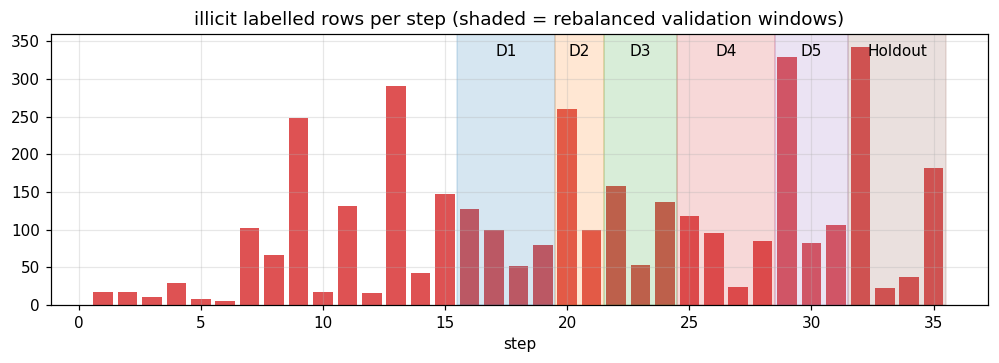

In [31]:
FOLD_TAB_ORIG = fold_tab.copy()                  # the first design, kept for comparison
FOLDS = {                                        # rebalanced by illicit count: every validation window has >= MIN_ILLICIT
    "D1": ((1, 11), (12, 15), (16, 19)),
    "D2": ((1, 15), (16, 19), (20, 21)),
    "D3": ((1, 17), (18, 21), (22, 24)),
    "D4": ((1, 20), (21, 24), (25, 28)),
    "D5": ((1, 24), (25, 28), (29, 31)),
}                                                # HOLDOUT is unchanged: ((1, 27), (28, 31), (32, 35))

prev_end = 0
for name, (trs, gp, vas) in {**FOLDS, "Holdout": HOLDOUT}.items():
    assert gp == (trs[1] + 1, vas[0] - 1) and gp[1] - gp[0] + 1 == 4, f"{name}: gap must be the 4 steps between train and validation"
    assert vas[0] > prev_end, f"{name}: validation window overlaps the previous one"
    prev_end = vas[1]

FOLD_IDX = {n: dict(tr=rows_in(*trs), va=rows_in(*vas)) for n, (trs, gp, vas) in FOLDS.items()}   # used by every later cell

rows_ = []
for name, (trs, gp, vas) in {**FOLDS, "Holdout": HOLDOUT}.items():
    v = FOLD_IDX[name] if name in FOLD_IDX else HOLD_IDX
    n1, n0 = int(Y[v["va"]].sum()), int((1 - Y[v["va"]]).sum())
    rows_.append(dict(fold=name, train_steps=f"{trs[0]}-{trs[1]}", gap_steps=f"{gp[0]}-{gp[1]}", val_steps=f"{vas[0]}-{vas[1]}",
                      train_rows=len(v["tr"]), train_illicit=int(Y[v["tr"]].sum()), val_rows=len(v["va"]), val_illicit=n1,
                      val_illicit_share=n1 / len(v["va"]), auc_se_if_0p9=hanley_mcneil_se(0.9, n1, n0), enough=n1 >= MIN_ILLICIT))
fold_tab = pd.DataFrame(rows_).set_index("fold")
display(fold_tab.round(4))
low = fold_tab[~fold_tab["enough"]]
print(f"WARNING: still below {MIN_ILLICIT} illicit rows: {list(low.index)}" if len(low) else f"rebalanced: every validation window has at least {MIN_ILLICIT} illicit rows")
print("validation illicit rows, before:", FOLD_TAB_ORIG["val_illicit"].to_dict(), "| after:", fold_tab["val_illicit"].to_dict())
fold_tab.to_csv(f"{OUT_DIR}/folds.csv")

fig, ax = plt.subplots(figsize=(11, 3.2))
ax.bar(step_lab.index, step_lab["illicit"], color="tab:red", alpha=0.8)
for k, (name, (trs, gp, vas)) in enumerate({**FOLDS, "Holdout": HOLDOUT}.items()):
    ax.axvspan(vas[0] - 0.5, vas[1] + 0.5, color=f"C{k}", alpha=0.18); ax.text((vas[0] + vas[1]) / 2, ax.get_ylim()[1] * 0.92, name, ha="center")
ax.set_xlabel("step"); ax.set_title("illicit labelled rows per step (shaded = rebalanced validation windows)"); plt.show()

### 4.2 Test-like sparsity inside the folds (node dropout)

Test rows keep about half of their neighbours (retention 0.51, 25% isolated), while the training graph is complete. To make validation look like test, every neighbour is hidden with probability `q`, as an absent node would be. The main setting is `q = 0.42` (calibrated on labelled rows); 0.35 and 0.50 are sensitivity runs. The hidden set is drawn **once** with a fixed seed and is **nested** (a node hidden at 0.35 is also hidden at 0.42 and 0.50), so every experiment sees the same graph and comparisons stay paired. Test rows are never thinned. The base feature matrix does not use the graph, so `q` matters only from the graph features onward, which must be built from `thin_adj(q)`.

In [32]:
Q_MAIN, Q_SENS = 0.42, (0.35, 0.50)
DROP_SEED = 123                                   # fixed: one thinned graph per q, shared by every experiment
_THIN = {}

def thin_adj(q, seed=DROP_SEED):
    # Undirected adjacency in which every training-period node is hidden with probability q. Row i sees neighbour j unless j is hidden.
    key = (round(float(q), 4), seed)
    if key not in _THIN:
        hidden = np.random.default_rng(seed).random(N) < q          # same draws for every q, so the hidden sets are nested
        hidden[IS_TEST] = False
        _THIN[key] = (A_und @ sp.diags((~hidden).astype(float))).tocsr()
    return _THIN[key]

def thin_deg(q): return np.asarray(thin_adj(q).sum(axis=1)).ravel()

real_mean, real_iso = DIAG["mean_deg_obs_test"], DIAG["iso_obs_test"]
rows_ = []
for q in (Q_SENS[0], Q_MAIN, Q_SENS[1]):
    d = thin_deg(q)
    for name, idx in {"train labelled": LAB, "validation windows (D1-D5)": np.concatenate([v["va"] for v in FOLD_IDX.values()])}.items():
        rows_.append(dict(q=q, rows=name, mean_degree=d[idx].mean(), isolated_share=(d[idx] == 0).mean()))
sim_tab = pd.DataFrame(rows_)
display(sim_tab.round(3))
print(f"real test: mean degree {real_mean:.3f}, isolated share {real_iso:.3f}")

d = thin_deg(Q_MAIN)
fold_sim = pd.DataFrame({f: dict(mean_degree=d[v["va"]].mean(), isolated_share=(d[v["va"]] == 0).mean()) for f, v in FOLD_IDX.items()}).T
print(f"q = {Q_MAIN}: thinned validation windows, per fold")
display(fold_sim.round(3))

,q,rows,mean_degree,isolated_share
0,0.35,train labelled,1.884,0.173
1,0.35,validation windows (D1-D5),1.855,0.167
2,0.42,train labelled,1.681,0.224
3,0.42,validation windows (D1-D5),1.656,0.219
4,0.50,train labelled,1.450,0.290
5,0.50,validation windows (D1-D5),1.436,0.280


real test: mean degree 1.660, isolated share 0.254
q = 0.42: thinned validation windows, per fold


,mean_degree,isolated_share
D1,1.638,0.220
D2,1.840,0.235
D3,1.661,0.183
D4,1.802,0.263
D5,1.452,0.237


### 4.3 Metrics, the `evaluate` function and the decision rule

`metrics(y, score)` gives ROC-AUC (decision) and PR-AUC (information). A **model function** takes one `ctx` (fold, training rows `tr`, validation rows `va`, dropout level `q`, thinned adjacency `adj`) and returns validation scores, averaging all seeds inside. `evaluate(name, model_fn, ref=...)` scores all five folds, prints ROC-AUC and PR-AUC per fold and the change against `ref`, and applies the rule.

**Rule for adopting a change (ROC-AUC only)**
1. the mean gain over the five folds is **above the seed noise level** (`NOISE_AUC`, measured in 4.4);
2. it wins **at least 4 of 5 folds** (3 of 5 with rules 1 and 3 satisfied is shown as BORDERLINE);
3. the best fold supplies **at most 50%** of the summed gain.

A change that passes becomes the new reference. One that fails stays in its section, marked not adopted.

In [33]:
from sklearn.metrics import average_precision_score

NOISE_AUC = np.nan                    # set in 4.4
RESULTS = {}                          # every stored evaluation, in order

def metrics(y, score):
    y = np.asarray(y).astype(int)
    return dict(auc=roc_auc_score(y, score), pr_auc=average_precision_score(y, score))

def fp_matrix(X, seeds=SEEDS):
    # Model function for a plain feature matrix X (rows aligned with ALL). Scores are seed-averaged inside.
    def fn(ctx):
        return predict_seed_avg(X[ctx["tr"]], Y[ctx["tr"]].astype(int), X[ctx["va"]], seeds=seeds)
    return fn

def decide(table, ref_table, noise=None):
    # Apply the three rules to per-fold ROC-AUC. Returns a dict with the verdict.
    noise = NOISE_AUC if noise is None else noise
    if not np.isfinite(noise): raise RuntimeError("NOISE_AUC is not set yet (run 4.4 first)")
    d = (table["auc"] - ref_table["auc"]).to_numpy(); nf = len(d)
    gain = d.mean(); wins = int((d > 0).sum()); need = int(np.ceil(0.8 * nf))
    share = float(d.max() / d.sum()) if d.sum() > 0 else np.nan
    r1, r2, r3 = gain > noise, wins >= need, (d.sum() > 0 and share <= 0.5)
    if r1 and r2 and r3:                       verdict = "ADOPT"
    elif r1 and r3 and wins == need - 1:       verdict = "BORDERLINE"
    else:                                      verdict = "NOT ADOPTED"
    return dict(gain=gain, noise=noise, wins=wins, folds=nf, need=need, best_fold_share=share,
                above_noise=bool(r1), enough_wins=bool(r2), spread=bool(r3), verdict=verdict)

def report(res, ref=None):
    t = res["table"].copy()
    if ref is not None:
        t["d_auc"] = t["auc"] - ref["table"]["auc"]; t["d_pr_auc"] = t["pr_auc"] - ref["table"]["pr_auc"]
    t.loc["mean"] = t.mean()
    print(f"[{res['name']}]  q={res['q']}  ({res['seconds']:.0f}s)")
    display(t.round(4))
    line = f"ROC-AUC {res['mean_auc']:.4f}   PR-AUC {res['mean_pr']:.4f}"
    if ref is not None:
        dec = res["decision"]
        line += f"   | change vs '{ref['name']}': ROC-AUC {dec['gain']:+.4f}   PR-AUC {res['mean_pr'] - ref['mean_pr']:+.4f}"
        print(line)
        print(f"rule 1 gain {dec['gain']:+.4f} vs seed noise {dec['noise']:.4f}: {'pass' if dec['above_noise'] else 'FAIL'} | "
              f"rule 2 wins {dec['wins']}/{dec['folds']} (need {dec['need']}): {'pass' if dec['enough_wins'] else 'FAIL'} | "
              f"rule 3 best fold share of gain {dec['best_fold_share']:.2f} (max 0.50): {'pass' if dec['spread'] else 'FAIL'}")
        print(f"==> {dec['verdict']}")
    else:
        print(line)

def evaluate(name, model_fn, ref=None, folds=None, q=None, store=True, verbose=True):
    # Score a model on the development folds. ref: a result returned by an earlier evaluate (the comparison point).
    q = Q_MAIN if q is None else q
    folds = list(FOLD_IDX) if folds is None else list(folds)
    t0, rows_ = time.time(), []
    for f in folds:
        v = FOLD_IDX[f]
        ctx = dict(fold=f, tr=v["tr"], va=v["va"], q=q, adj=thin_adj(q))
        s = np.asarray(model_fn(ctx)); y = Y[v["va"]].astype(int)
        rows_.append(dict(fold=f, **metrics(y, s), base_rate=y.mean()))
    table = pd.DataFrame(rows_).set_index("fold")
    res = dict(name=name, q=q, table=table, mean_auc=table["auc"].mean(), mean_pr=table["pr_auc"].mean(), seconds=time.time() - t0)
    if ref is not None: res["decision"] = decide(table, ref["table"])
    if store: RESULTS[name] = res
    if verbose: report(res, ref)
    return res

def results_summary():
    # One line per stored evaluation: for reading the whole notebook at a glance.
    out = []
    for n, r in RESULTS.items():
        d = r.get("decision")
        out.append(dict(experiment=n, q=r["q"], roc_auc=r["mean_auc"], pr_auc=r["mean_pr"],
                        d_auc=d["gain"] if d else np.nan, wins=f"{d['wins']}/{d['folds']}" if d else "", verdict=d["verdict"] if d else "reference"))
    return pd.DataFrame(out).round(4)

HOLDOUT_STATE = {"used": False}
def holdout_once(model_fn, name="final model"):
    # The holdout is scored one time, with the finished pipeline. A second call is refused.
    if HOLDOUT_STATE["used"]: raise RuntimeError("the holdout has already been used; it must not guide further changes")
    HOLDOUT_STATE["used"] = True
    ctx = dict(fold="Holdout", tr=HOLD_IDX["tr"], va=HOLD_IDX["va"], q=Q_MAIN, adj=thin_adj(Q_MAIN))
    s = np.asarray(model_fn(ctx)); m = metrics(Y[HOLD_IDX["va"]].astype(int), s)
    print(f"HOLDOUT [{name}]  ROC-AUC {m['auc']:.4f}   PR-AUC {m['pr_auc']:.4f}   (steps {HOLDOUT[2][0]}-{HOLDOUT[2][1]}, scored once)")
    return m

### 4.4 Reference model and seed noise level

The **reference** is LightGBM with the fixed defaults on the 164 base features (`X_BASE`), seeds (0, 1, 2) averaged. **Seed noise level:** the reference is run with four disjoint seed sets; the spread of the four five-fold means (largest minus smallest) is how much the score moves when only the seeds change. A change must beat it. Dropout and folds are identical in all runs.

In [34]:
NOISE_SETS = [(0, 1, 2), (3, 4, 5), (6, 7, 8), (9, 10, 11)]      # the first set is the reference itself
runs = []
for k, s in enumerate(NOISE_SETS):
    if k == 0: REF = evaluate("reference: LightGBM on X_BASE", fp_matrix(X_BASE, s), verbose=True); runs.append(REF)
    else:      runs.append(evaluate(f"seed check {s}", fp_matrix(X_BASE, s), store=False, verbose=False))

per_run = pd.DataFrame({str(s): r["table"]["auc"] for s, r in zip(NOISE_SETS, runs)})
per_run.loc["mean"] = per_run.mean()
display(per_run.round(4))
means = per_run.loc["mean"].to_numpy()
NOISE_AUC = float(means.max() - means.min())
fold_range = (per_run.drop(index="mean").max(axis=1) - per_run.drop(index="mean").min(axis=1))
pr_noise = float(np.ptp([r["mean_pr"] for r in runs]))
print(f"SEED NOISE LEVEL (ROC-AUC, mean over folds): {NOISE_AUC:.4f}   (PR-AUC, information only: {pr_noise:.4f})")
print("per-fold range across seed sets:", fold_range.round(4).to_dict())
DIAG.update(noise_auc=NOISE_AUC, reference_auc=float(REF["mean_auc"]))

# the rule applied to a no-change experiment: it must come out NOT ADOPTED
print("\nsanity check of the rule: same model, different seeds, compared with the reference")
report(runs[1] | dict(name="seed check (3, 4, 5)", decision=decide(runs[1]["table"], REF["table"])), REF)

[reference: LightGBM on X_BASE]  q=0.42  (16s)


,auc,pr_auc,base_rate
fold,,,
D1,0.9944,0.9847,0.1451
D2,0.9862,0.9643,0.2336
D3,0.9168,0.7448,0.0854
D4,0.9824,0.9704,0.2017
D5,0.9934,0.9803,0.2151
mean,0.9747,0.9289,0.1762


ROC-AUC 0.9747   PR-AUC 0.9289


,"(0, 1, 2)","(3, 4, 5)","(6, 7, 8)","(9, 10, 11)"
fold,,,,
D1,0.9944,0.9944,0.9944,0.9946
D2,0.9862,0.9856,0.9868,0.9857
D3,0.9168,0.9185,0.9123,0.9141
D4,0.9824,0.9855,0.9810,0.9859
D5,0.9934,0.9941,0.9938,0.9941
mean,0.9747,0.9756,0.9737,0.9749


SEED NOISE LEVEL (ROC-AUC, mean over folds): 0.0020   (PR-AUC, information only: 0.0005)
per-fold range across seed sets: {'D1': 0.0003, 'D2': 0.0012, 'D3': 0.0062, 'D4': 0.0049, 'D5': 0.0007}

sanity check of the rule: same model, different seeds, compared with the reference
[seed check (3, 4, 5)]  q=0.42  (16s)


,auc,pr_auc,base_rate,d_auc,d_pr_auc
fold,,,,,
D1,0.9944,0.9844,0.1451,0.0000,-0.0003
D2,0.9856,0.9627,0.2336,-0.0006,-0.0017
D3,0.9185,0.7461,0.0854,0.0017,0.0013
D4,0.9855,0.9722,0.2017,0.0031,0.0018
D5,0.9941,0.9818,0.2151,0.0007,0.0015
mean,0.9756,0.9294,0.1762,0.0010,0.0005


ROC-AUC 0.9756   PR-AUC 0.9294   | change vs 'reference: LightGBM on X_BASE': ROC-AUC +0.0010   PR-AUC +0.0005
rule 1 gain +0.0010 vs seed noise 0.0020: FAIL | rule 2 wins 4/5 (need 4): pass | rule 3 best fold share of gain 0.64 (max 0.50): FAIL
==> NOT ADOPTED


### 4.5 How the rest of the notebook uses this

Every experiment is `evaluate("name", model_fn, ref=REF)`. Graph-dependent features are built from `ctx["adj"]` (thinned graph), per fold, from training rows only; sensitivity runs call `evaluate(..., q=0.35)` and `q=0.50`. `results_summary()` lists all stored experiments with verdicts. The holdout (`holdout_once`) is scored one time, with the finished pipeline. The folds, noise level and dropout levels are not changed after seeing a result.

### Section 4 summary

**Illicit-count check on the first design** (D1 and D4 too small):

| Fold | Validation steps | Illicit rows | Enough (at least 300) |
|---|---|---|---|
| D1 | 16-18 | 279 | No |
| D2 | 19-21 | 440 | Yes |
| D3 | 22-24 | 348 | Yes |
| D4 | 25-27 | 238 | No |
| D5 | 28-31 | 603 | Yes |
| Holdout | 32-35 | 584 | Yes |

**Rebalanced folds (adopted):**

| Fold | Train | Gap | Validation | Illicit in validation |
|---|---|---|---|---|
| D1 | 1-11 | 12-15 | 16-19 | 359 |
| D2 | 1-15 | 16-19 | 20-21 | 360 |
| D3 | 1-17 | 18-21 | 22-24 | 348 |
| D4 | 1-20 | 21-24 | 25-28 | 323 |
| D5 | 1-24 | 25-28 | 29-31 | 518 |
| Holdout | 1-27 | 28-31 | 32-35 | 584 |

**Node dropout.** At q = 0.42 the mean degree matches the test (1.656 vs 1.660); the isolated share is a little low (0.219 vs 0.254), and q = 0.50 (0.280) brackets it.

| q | Mean degree | Isolated share |
|---|---|---|
| 0.35 | 1.855 | 0.167 |
| 0.42 | 1.656 | 0.219 |
| 0.50 | 1.436 | 0.280 |
| real test | 1.660 | 0.254 |

**Reference model** (LightGBM, 200 trees, learning rate 0.05, 164 base features):

| Fold | ROC-AUC | PR-AUC | Illicit share | Range across 4 seed sets |
|---|---|---|---|---|
| D1 | 0.9944 | 0.9847 | 0.145 | 0.0003 |
| D2 | 0.9862 | 0.9643 | 0.234 | 0.0012 |
| D3 | 0.9168 | 0.7448 | 0.085 | 0.0062 |
| D4 | 0.9824 | 0.9704 | 0.202 | 0.0049 |
| D5 | 0.9934 | 0.9803 | 0.215 | 0.0007 |
| **Mean** | **0.9747** | **0.9289** | 0.176 | |

**Seed noise level = 0.0020**: the four five-fold means were 0.9747, 0.9756, 0.9737 and 0.9749 (it was 0.0027 on the first folds). A no-change run (seeds 3, 4, 5) correctly gets NOT ADOPTED: gain +0.0010 (fails rule 1), 4 of 5 folds (passes, since any positive difference counts), D4 supplies 64% (fails rule 3).

**Decisions.** Adopt the rebalanced folds; noise level 0.0020; node dropout q = 0.42 with 0.35 and 0.50 as sensitivity; the design is fixed from here on.

**Observations.** Rule 2 alone is weak; rules 1 and 3 do the rejecting. D3 and D4 are the noisiest folds (ranges 0.0062 and 0.0049 against 0.0003 to 0.0012). D3 is also the hardest (AUC 0.917, lowest illicit share), so most of the remaining headroom is there.

## 5. Model family and baselines

Which model family should the rest of the notebook build on? Candidates: logistic regression (LR), random forest (RF), histogram gradient boosting (HGB), XGBoost (XGB), LightGBM (the reference) and two graph neural networks (GCN, GraphSAGE).

**Rules for a fair comparison.** Same folds, dropout graph, `evaluate` function and section 4 rule, each candidate against LightGBM on `X_BASE`. Same inputs (`X_BASE`, 164 features); the GNNs also see the thinned graph, so the gap between a GNN and the tabular models measures what the graph adds. Same capacity for the boosted models (200 trees, learning rate 0.05, about 31 leaves); no tuning, class weights or resampling yet. Quantile-normal scaling (fitted on the fold's training rows) only for LR and the GNNs. No early stopping on validation rows. Three seeds averaged (LR and HGB are deterministic, run once). Out-of-fold scores are kept in `SCORES` for ensembling.

**Decision.** A tabular model replaces the reference only if it is ADOPT under the section 4 rule. GNNs are reported, but the rest of the pipeline is built for tabular models, so a good GNN would be revisited as an ensemble member.

In [35]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.preprocessing import QuantileTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline

try:
    import xgboost as xgb; HAS_XGB = True
except ImportError:
    HAS_XGB = False; print("xgboost is not installed: XGB will be skipped (pip install xgboost)")
try:
    import torch, torch.nn as nn, torch.nn.functional as F; HAS_TORCH = True
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
except ImportError:
    HAS_TORCH = False; print("torch is not installed: GCN and GraphSAGE will be skipped (pip install torch)")

print("NaN in X_BASE:", int(np.isnan(X_BASE).sum()), "| xgboost:", HAS_XGB, "| torch:", HAS_TORCH, "| device:", DEVICE if HAS_TORCH else "-")

SCORES = {}                                       # model name -> {fold: out-of-fold scores}, for the ensembling section
def recorded(name, fn):
    def wrapped(ctx):
        s = np.asarray(fn(ctx)); SCORES.setdefault(name, {})[ctx["fold"]] = s; return s
    return wrapped

def quantile_prep(Xfit):
    # impute (median) then quantile-normal transform, fitted on the rows given (training rows only)
    return make_pipeline(SimpleImputer(strategy="median"),
                         QuantileTransformer(n_quantiles=1000, output_distribution="normal", subsample=200000, random_state=RANDOM_STATE)).fit(Xfit)

# one entry per tabular model: constructor taking a seed, whether it needs scaling, which seeds to average
TABULAR = {
    "LR":  dict(make=lambda s: LogisticRegression(C=1.0, max_iter=2000), scale=True, seeds=(0,)),
    "RF":  dict(make=lambda s: RandomForestClassifier(n_estimators=N_TREES, n_jobs=-1, random_state=s), scale=False, seeds=SEEDS),
    "HGB": dict(make=lambda s: HistGradientBoostingClassifier(max_iter=N_TREES, learning_rate=LEARNING_RATE, max_leaf_nodes=31, min_samples_leaf=20,
                                                              l2_regularization=0.0, early_stopping=False, random_state=s), scale=False, seeds=(0,)),
}
if HAS_XGB:
    TABULAR["XGB"] = dict(make=lambda s: xgb.XGBClassifier(n_estimators=N_TREES, learning_rate=LEARNING_RATE, max_depth=6, subsample=0.8, colsample_bytree=0.8,
                                                           tree_method="hist", n_jobs=-1, random_state=s, verbosity=0), scale=False, seeds=SEEDS)

def fp_family(name, X, seeds=None):
    # Model function for a family on any feature matrix X (rows aligned with ALL). Scores are seed-averaged inside.
    if name == "LGBM": return fp_matrix(X, SEEDS if seeds is None else seeds)
    spec = TABULAR[name]; use = spec["seeds"] if spec["seeds"] == (0,) or seeds is None else seeds
    def fn(ctx):
        Xtr, Xva, ytr = X[ctx["tr"]], X[ctx["va"]], Y[ctx["tr"]].astype(int)
        if spec["scale"]:
            prep = quantile_prep(Xtr); Xtr, Xva = prep.transform(Xtr), prep.transform(Xva)
        return np.mean([spec["make"](s).fit(Xtr, ytr).predict_proba(Xva)[:, 1] for s in use], axis=0)
    return fn

settings = pd.DataFrame({
    "LR":   dict(settings="C=1, lbfgs, quantile-normal inputs", seeds_averaged=1),
    "RF":   dict(settings=f"{N_TREES} trees, sqrt features, full depth", seeds_averaged=len(SEEDS)),
    "HGB":  dict(settings=f"{N_TREES} iterations, lr {LEARNING_RATE}, 31 leaves, min leaf 20, no early stopping", seeds_averaged=1),
    "XGB":  dict(settings=f"{N_TREES} trees, lr {LEARNING_RATE}, depth 6, subsample 0.8, colsample 0.8", seeds_averaged=len(SEEDS) if HAS_XGB else 0),
    "LGBM": dict(settings=f"{N_TREES} trees, lr {LEARNING_RATE}, 31 leaves, subsample 0.8, colsample 0.8 (reference)", seeds_averaged=len(SEEDS)),
}).T
display(settings)

NaN in X_BASE: 0 | xgboost: True | torch: True | device: cpu


,settings,seeds_averaged
LR,"C=1, lbfgs, quantile-normal inputs",1
RF,"200 trees, sqrt features, full depth",3
HGB,"200 iterations, lr 0.05, 31 leaves, min leaf 2...",1
XGB,"200 trees, lr 0.05, depth 6, subsample 0.8, co...",3
LGBM,"200 trees, lr 0.05, 31 leaves, subsample 0.8, ...",3


### 5.1 Tabular models

LightGBM's out-of-fold scores are recomputed once to be stored in `SCORES` (the difference from the stored reference should be about zero).

In [36]:
TAB_NAMES = list(TABULAR)                                        # LR, RF, HGB, (XGB)
chk = evaluate("recheck: LGBM", recorded("LGBM", fp_matrix(X_BASE)), ref=None, store=False, verbose=False)
print(f"LGBM recomputed: ROC-AUC {chk['mean_auc']:.4f} (stored reference {REF['mean_auc']:.4f}, difference {chk['mean_auc'] - REF['mean_auc']:+.5f})")

for nm in TAB_NAMES:
    r = evaluate(f"model: {nm}", recorded(nm, fp_family(nm, X_BASE)), ref=REF, verbose=False)
    d = r["decision"]
    print(f"{nm:4s} ROC-AUC {r['mean_auc']:.4f}  PR-AUC {r['mean_pr']:.4f}  change {d['gain']:+.4f}  wins {d['wins']}/{d['folds']}  -> {d['verdict']}  ({r['seconds']:.0f}s)")

LGBM recomputed: ROC-AUC 0.9747 (stored reference 0.9747, difference +0.00000)
LR   ROC-AUC 0.9498  PR-AUC 0.8560  change -0.0249  wins 0/5  -> NOT ADOPTED  (9s)
RF   ROC-AUC 0.9454  PR-AUC 0.9172  change -0.0292  wins 0/5  -> NOT ADOPTED  (17s)
HGB  ROC-AUC 0.9690  PR-AUC 0.9211  change -0.0057  wins 1/5  -> NOT ADOPTED  (10s)
XGB  ROC-AUC 0.9704  PR-AUC 0.9252  change -0.0043  wins 1/5  -> NOT ADOPTED  (34s)


### 5.2 Graph neural networks (GCN and GraphSAGE)

Both are full-batch, two layers, trained on the **thinned graph** (q = 0.42) with the quantile-normal features, on labelled rows of the training steps only. Training and validation rows never share a connected component, so nothing leaks through edges.
* **GCN:** `H' = relu(A_hat H W)`, `A_hat` the row-normalised adjacency with self loops.
* **GraphSAGE (mean):** `H' = relu(W_self H + W_nbr mean(neighbours of H))`.
* Fixed settings, not tuned: hidden size 64, dropout 0.3, Adam (learning rate 0.01, weight decay 5e-4), 200 epochs, 3 seeds, plain PyTorch.
* **Diagnostic:** each GNN is also run on the full, unthinned graph (q = 0) to show what the missing neighbours cost. It is not a candidate.

In [37]:
GNN_HID, GNN_DROP, GNN_LR, GNN_WD, GNN_EPOCHS = 64, 0.3, 0.01, 5e-4, 200

def gnn_prepare(ctx, kind):
    # Everything the GNN needs for one fold, built with numpy/scipy only (no labels of validation rows are used).
    trs, gp, vas = HOLDOUT if ctx["fold"] == "Holdout" else FOLDS[ctx["fold"]]
    keep = ((T <= trs[1]) | ((T >= vas[0]) & (T <= vas[1]))) & ~IS_TEST      # train steps + validation window; gap and later steps are not needed
    nodes = np.where(keep)[0]
    pos = np.full(N, -1, dtype=np.int64); pos[nodes] = np.arange(len(nodes))
    fit_rows = nodes[T[nodes] <= trs[1]]                                       # label-free scaling fit on the training-period rows
    prep = quantile_prep(X_BASE[fit_rows])
    Xn = np.nan_to_num(prep.transform(X_BASE[nodes])).astype(np.float32)
    A = ctx["adj"][nodes][:, nodes].tocsr().astype(np.float32); A.data[:] = 1.0
    deg = np.asarray(A.sum(axis=1)).ravel()
    if kind == "gcn": P = sp.diags(1.0 / (deg + 1.0)) @ (A + sp.identity(len(nodes), format="csr"))     # self loops, row-normalised
    else:             P = sp.diags(1.0 / np.maximum(deg, 1.0)) @ A                                      # neighbour mean, no self loop
    P = P.tocsr().astype(np.float32)
    return dict(X=Xn, PX=np.asarray(P @ Xn, dtype=np.float32), P=P, tr_l=pos[ctx["tr"]], va_l=pos[ctx["va"]], n=len(nodes))

if HAS_TORCH:
    def to_sparse(M):
        M = M.tocoo()
        idx = torch.from_numpy(np.vstack([M.row, M.col]).astype(np.int64))
        return torch.sparse_coo_tensor(idx, torch.from_numpy(M.data.astype(np.float32)), tuple(M.shape)).coalesce().to(DEVICE)

    class GNN(nn.Module):
        def __init__(self, kind, d_in, hid, drop):
            super().__init__()
            self.kind, self.drop = kind, drop
            if kind == "gcn":
                self.l1 = nn.Linear(d_in, hid); self.l2 = nn.Linear(hid, 1, bias=False); self.b2 = nn.Parameter(torch.zeros(1))
            else:
                self.l1s = nn.Linear(d_in, hid); self.l1n = nn.Linear(d_in, hid, bias=False)
                self.l2s = nn.Linear(hid, 1);    self.l2n = nn.Linear(hid, 1, bias=False)
        def forward(self, X, PX, P):
            if self.kind == "gcn":
                h = F.dropout(F.relu(self.l1(PX)), self.drop, self.training)              # PX = A_hat X, so this is A_hat X W1
                return torch.sparse.mm(P, self.l2(h)).squeeze(1) + self.b2                 # A_hat H W2
            h = F.dropout(F.relu(self.l1s(X) + self.l1n(PX)), self.drop, self.training)    # PX = neighbour mean of X
            return self.l2s(h).squeeze(1) + torch.sparse.mm(P, self.l2n(h)).squeeze(1)

    def gnn_fit_predict(ctx, kind, seeds=SEEDS):
        pr = gnn_prepare(ctx, kind)
        X, PX, P = torch.from_numpy(pr["X"]).to(DEVICE), torch.from_numpy(pr["PX"]).to(DEVICE), to_sparse(pr["P"])
        tr_l, va_l = torch.from_numpy(pr["tr_l"]).to(DEVICE), torch.from_numpy(pr["va_l"]).to(DEVICE)
        y_tr = torch.from_numpy(Y[ctx["tr"]].astype(np.float32)).to(DEVICE)
        outs = []
        for s in seeds:
            torch.manual_seed(s)
            model = GNN(kind, X.shape[1], GNN_HID, GNN_DROP).to(DEVICE)
            opt = torch.optim.Adam(model.parameters(), lr=GNN_LR, weight_decay=GNN_WD)
            for _ in range(GNN_EPOCHS):
                model.train(); opt.zero_grad()
                loss = F.binary_cross_entropy_with_logits(model(X, PX, P)[tr_l], y_tr)
                loss.backward(); opt.step()
            model.eval()
            with torch.no_grad(): outs.append(torch.sigmoid(model(X, PX, P))[va_l].cpu().numpy())
        return np.mean(outs, axis=0)

    for nm, kind in (("GCN", "gcn"), ("GraphSAGE", "sage")):
        r = evaluate(f"model: {nm}", recorded(nm, lambda ctx, k=kind: gnn_fit_predict(ctx, k)), ref=REF, verbose=False)
        d = r["decision"]
        print(f"{nm:9s} ROC-AUC {r['mean_auc']:.4f}  PR-AUC {r['mean_pr']:.4f}  change {d['gain']:+.4f}  wins {d['wins']}/{d['folds']}  -> {d['verdict']}  ({r['seconds']:.0f}s)")
        # diagnostic only (no reference, no verdict): the same GNN on the full, unthinned graph
        rd = evaluate(f"diagnostic: {nm} on the full graph (q=0)", lambda ctx, k=kind: gnn_fit_predict(ctx, k), ref=None, q=0.0, verbose=False)
        print(f"          diagnostic, full graph (q=0): ROC-AUC {rd['mean_auc']:.4f}  PR-AUC {rd['mean_pr']:.4f}")
else:
    print("torch not available: the GNN models were not run.")

GCN       ROC-AUC 0.9519  PR-AUC 0.8712  change -0.0228  wins 0/5  -> NOT ADOPTED  (1209s)
          diagnostic, full graph (q=0): ROC-AUC 0.9495  PR-AUC 0.8920
GraphSAGE ROC-AUC 0.9669  PR-AUC 0.9115  change -0.0078  wins 0/5  -> NOT ADOPTED  (457s)
          diagnostic, full graph (q=0): ROC-AUC 0.9646  PR-AUC 0.9184


### 5.3 Comparison and decision

One table for every candidate, then the per-fold ROC-AUC.

,experiment,q,roc_auc,pr_auc,d_auc,wins,verdict,seconds
0,reference: LightGBM on X_BASE,0.42,0.9747,0.9289,NaN,,reference,16.479242
1,model: XGB,0.42,0.9704,0.9252,-0.0043,1/5,NOT ADOPTED,33.527891
2,model: HGB,0.42,0.9690,0.9211,-0.0057,1/5,NOT ADOPTED,10.250208
3,model: GraphSAGE,0.42,0.9669,0.9115,-0.0078,0/5,NOT ADOPTED,457.295444
4,model: GCN,0.42,0.9519,0.8712,-0.0228,0/5,NOT ADOPTED,1208.847519
5,model: LR,0.42,0.9498,0.8560,-0.0249,0/5,NOT ADOPTED,9.008163
6,model: RF,0.42,0.9454,0.9172,-0.0292,0/5,NOT ADOPTED,17.001463


fold,D1,D2,D3,D4,D5
LGBM (reference),0.9944,0.9862,0.9168,0.9824,0.9934
LR,0.9847,0.9534,0.9111,0.9694,0.9303
RF,0.9899,0.9837,0.7914,0.9699,0.9921
HGB,0.9930,0.9807,0.8960,0.9831,0.9922
XGB,0.9940,0.9840,0.8985,0.9826,0.9929
GCN,0.9781,0.9598,0.8941,0.9605,0.9669
GraphSAGE,0.9916,0.9781,0.9088,0.9749,0.9810


diagnostics (full graph, not candidates):


fold,D1,D2,D3,D4,D5
GCN on the full graph (q=0),0.9857,0.9609,0.8557,0.9583,0.9866
GraphSAGE on the full graph (q=0),0.9924,0.9763,0.8908,0.9729,0.9906


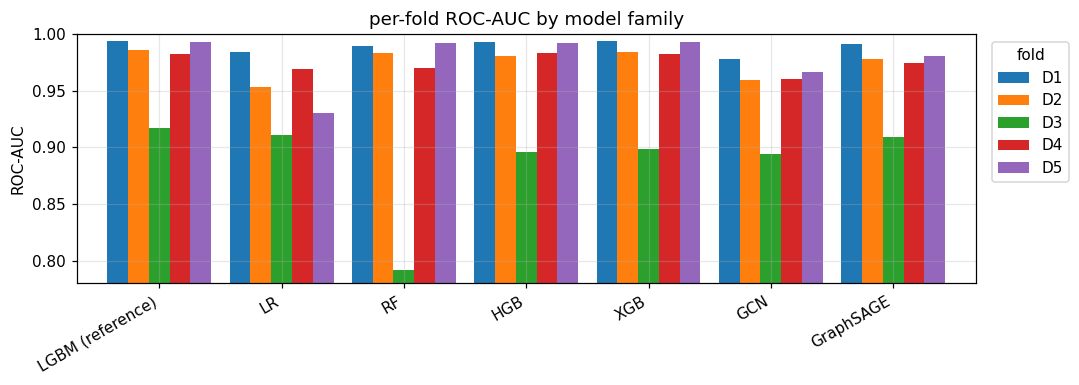

In [40]:
summ = results_summary()
cmp_ = summ[summ["experiment"].str.startswith("model:") | summ["experiment"].str.startswith("reference:")].copy()
cmp_["seconds"] = [RESULTS[n]["seconds"] for n in cmp_["experiment"]]
display(cmp_.sort_values("roc_auc", ascending=False).reset_index(drop=True))

fold_auc = pd.DataFrame({n.replace("model: ", "").replace("reference: LightGBM on X_BASE", "LGBM (reference)"): RESULTS[n]["table"]["auc"]
                         for n in RESULTS if n.startswith("model:") or n.startswith("reference")})
diag = pd.DataFrame({n.replace("diagnostic: ", ""): RESULTS[n]["table"]["auc"] for n in RESULTS if n.startswith("diagnostic:")})
display(fold_auc.round(4).T)
if len(diag): print("diagnostics (full graph, not candidates):"); display(diag.round(4).T)

ax = fold_auc.T.plot.bar(figsize=(10, 3.6), width=0.85); ax.set_ylim(0.78, 1.0)
ax.legend(title="fold", loc="upper left", bbox_to_anchor=(1.01, 1)); ax.set_ylabel("ROC-AUC"); ax.set_title("per-fold ROC-AUC by model family")
plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()

In [39]:
# Family decision. Tabular candidates only; the GNNs are reported but not switched in (see the section text).
BASE_NAME = "LGBM"
adopt = [n for n in TAB_NAMES if RESULTS[f"model: {n}"]["decision"]["verdict"] == "ADOPT"]
if adopt:
    best = max(adopt, key=lambda n: RESULTS[f"model: {n}"]["mean_auc"])
    BASE_NAME, REF = best, RESULTS[f"model: {best}"]
    # the seed noise level is measured again for the new family; it is never lowered (HGB and LR have no seed noise to measure)
    means = [REF["mean_auc"]] + [evaluate(f"seed check {best} {s}", fp_family(best, X_BASE, s), store=False, verbose=False)["mean_auc"] for s in NOISE_SETS[1:]]
    new_noise = float(np.ptp(means)); NOISE_AUC = max(NOISE_AUC, new_noise)
    print(f"ADOPTED family: {best} (ROC-AUC {REF['mean_auc']:.4f}). Seed noise measured {new_noise:.4f}; NOISE_AUC is now {NOISE_AUC:.4f}.")
else:
    print(f"No tabular model beats LightGBM under the rule. The family stays LGBM (ROC-AUC {REF['mean_auc']:.4f}, seed noise {NOISE_AUC:.4f}).")

def fp_base(X, seeds=None):
    # the model function every later section uses for 'the model'
    return fp_family(BASE_NAME, X, seeds)

if HAS_TORCH:
    for nm in ("GCN", "GraphSAGE"):
        d = RESULTS[f"model: {nm}"]["decision"]
        print(f"{nm}: {d['verdict']} vs the tabular reference ({d['gain']:+.4f} ROC-AUC). Kept as a possible ensemble member / feature source, not as the base model.")
DIAG.update(base_model=BASE_NAME, base_auc=float(REF["mean_auc"]), noise_auc_after_family=float(NOISE_AUC))

No tabular model beats LightGBM under the rule. The family stays LGBM (ROC-AUC 0.9747, seed noise 0.0020).
GCN: NOT ADOPTED vs the tabular reference (-0.0228 ROC-AUC). Kept as a possible ensemble member / feature source, not as the base model.
GraphSAGE: NOT ADOPTED vs the tabular reference (-0.0078 ROC-AUC). Kept as a possible ensemble member / feature source, not as the base model.


### Section 5 summary

| Model | ROC-AUC | PR-AUC | Change vs reference | Folds won | Verdict | Time |
|---|---|---|---|---|---|---|
| **LightGBM (reference)** | **0.9747** | **0.9289** | | | reference | 16 s |
| XGB | 0.9704 | 0.9252 | -0.0043 | 1/5 | NOT ADOPTED | 34 s |
| HGB | 0.9690 | 0.9211 | -0.0057 | 1/5 | NOT ADOPTED | 10 s |
| GraphSAGE | 0.9669 | 0.9115 | -0.0078 | 0/5 | NOT ADOPTED | 457 s |
| GCN | 0.9519 | 0.8712 | -0.0228 | 0/5 | NOT ADOPTED | 1209 s |
| LR | 0.9498 | 0.8560 | -0.0249 | 0/5 | NOT ADOPTED | 9 s |
| RF | 0.9454 | 0.9172 | -0.0292 | 0/5 | NOT ADOPTED | 17 s |

Per-fold ROC-AUC:

| Model | D1 | D2 | D3 | D4 | D5 |
|---|---|---|---|---|---|
| LightGBM (reference) | 0.9944 | 0.9862 | 0.9168 | 0.9824 | 0.9934 |
| XGB | 0.9940 | 0.9840 | 0.8985 | 0.9826 | 0.9929 |
| HGB | 0.9930 | 0.9807 | 0.8960 | 0.9831 | 0.9922 |
| GraphSAGE | 0.9916 | 0.9781 | 0.9088 | 0.9749 | 0.9810 |
| GCN | 0.9781 | 0.9598 | 0.8941 | 0.9605 | 0.9669 |
| LR | 0.9847 | 0.9534 | 0.9111 | 0.9694 | 0.9303 |
| RF | 0.9899 | 0.9837 | 0.7914 | 0.9699 | 0.9921 |

GNNs on the thinned graph (q = 0.42) against the full graph (q = 0, diagnostic only): GraphSAGE 0.9669 / 0.9646, GCN 0.9519 / 0.9495.

**Findings**
* LightGBM is best on both ROC-AUC and PR-AUC; no candidate wins more than 1 of 5 folds. XGB and HGB are lower by more than the noise level.
* D3 is where models differ most (0.79 to 0.92); RF collapses there. GraphSAGE is the best GNN, 0.0078 behind LightGBM; GCN is weaker and about 2.6 times slower.
* The GNNs gain nothing from the extra neighbours (the full graph does not score higher than the thinned one). One explanation (hypothesis, not tested) is that `X_BASE` already contains neighbour aggregates, which the offset-6 duplicate pairs from section 3 would fit. The GNNs are also untuned.

**Decisions.** Base model: **LightGBM**. GraphSAGE, XGB and HGB are kept as ensemble candidates (section 9, no further tuning); GCN, RF and LR are dropped. Seed noise level stays 0.0020.

## 6. Feature engineering by groups

Which groups of removed or added features raise ROC-AUC? LightGBM is the base model, and the reference starts as the section 4/5 reference and moves up each time a group is adopted.

**Rules.** One test per **group**, never single features, in an order fixed in advance: A, B, C (clean the base features), D, D2, G (structure only), E, E2 (neighbour feature aggregates), F, F2 (neighbour scores). The section 4 rule applies to every test (rebalanced folds, 3 seeds, q = 0.42). A group that passes joins the reference; one that fails is not adopted and stays here. Everything is built **per fold**, with anything that uses labels taken from the fold's training rows only. Test rows have no labelled neighbours (edges never cross steps), so neighbours' true labels are never used; only neighbours' features and neighbours' **predicted** scores are. No pruning by importance, sampling, class weights or tuning.

| Group | Content |
|---|---|
| A | drop the six time-index features together (feat_100, 101, 103, 136, 137, 139) |
| B | rank within the row's own time step for the remaining 14 drifting features (PSI above 0.25) |
| C | drop the second member of the 7 offset-6 near-duplicate pairs |
| D | own structure on the thinned graph: degrees, isolated flag, reciprocity, in share, neighbour degree sum and mean |
| D2 | 2-hop structure: distinct 2-hop count, 2-hop degree sum / mean / max, expansion ratio, directed 2-hop walk counts |
| G | edge-list (phantom-aware) structure: full degree, phantom count, observed share, full-graph component size, phantom degrees, rows reached through phantoms |
| E / E2 | neighbour aggregates (E) and 2-hop mean (E2) of the top-k features (k = 10, 20, 40), columns picked inside each fold on its training rows |
| F | stage-1 scores of the neighbours (mean and max over all, in and out neighbours) and of the whole component (8 columns) |
| F2 | 2-hop mean of the stage-1 scores (1 column) |

### 6.0 Machinery

Bookkeeping only: the hidden-node mask, the directed thinned graphs, the feature blocks, and the functions that build and score a fold's matrices. Each block has one row per row of `ALL` and a list of column names; structure-only blocks (B, D, D2, G) depend on `q` only, E and F also depend on the fold.

In [ ]:
from scipy.sparse.csgraph import connected_components

assert BASE_NAME == "LGBM", "section 6 builds on LightGBM"
REF0 = REF                                         # the section 4/5 reference, kept for the final comparison
CUR_REF = REF                                      # moves up each time a group is adopted
ADOPTED = dict(A=False, B=False, C=False, D=False, D2=False, G=False, E=0, E2=False, F=False, F2=False)
FEATURE_LOG = []

FEAT_IDX = {c: i for i, c in enumerate(FEAT)}
C_DROP = list(pairs_df.loc[~pairs_df["redundant"], "other"])                    # second member of each flagged pair (section 3)
assert all(int(o.split("_")[1]) - int(k.split("_")[1]) == 6 for k, o in zip(pairs_df.loc[~pairs_df["redundant"], "keep_candidate"], C_DROP)), "pairs are expected 6 feature numbers apart"
TIME_IDX = [c for c in TIME_IDX if c in FEAT_IDX]
B_COLS = [c for c in drift.index if drift.loc[c, "psi_early_late"] > 0.25 and c in FEAT_IDX and c not in TIME_IDX]
print(f"A drops {TIME_IDX}\nC drops {C_DROP}\nB ranks {len(B_COLS)} drifting features: {B_COLS}")

# a small cache with a size cap (arrays of whole-graph size are large)
def _nbytes(v):
    if isinstance(v, np.ndarray): return v.nbytes
    if sp.issparse(v): return v.data.nbytes + v.indices.nbytes + v.indptr.nbytes
    if isinstance(v, dict): return sum(_nbytes(x) for x in v.values())
    if isinstance(v, (list, tuple)): return sum(_nbytes(x) for x in v)
    return 0
class BlockCache:
    def __init__(self, cap=2.0e9): self.d, self.sz, self.cap = {}, {}, cap
    def get(self, key, fn):
        if key in self.d: self.d[key] = self.d.pop(key); self.sz[key] = self.sz.pop(key); return self.d[key]
        v = fn(); self.d[key], self.sz[key] = v, _nbytes(v)
        while sum(self.sz.values()) > self.cap and len(self.d) > 1:
            k0 = next(iter(self.d)); self.d.pop(k0); self.sz.pop(k0)
        return v
BC = BlockCache()

# hidden-node mask and the directed thinned graphs (same draw as thin_adj in section 4)
def hidden_mask(q, seed=DROP_SEED):
    h = np.random.default_rng(seed).random(N) < q
    h[IS_TEST] = False
    return h

_GQ, _GB = {}, {}
def graph_q(q):
    key = round(float(q), 4)
    if key not in _GQ:
        keep = sp.diags((~hidden_mask(q)).astype(np.float32))
        A1   = (A_und @ keep).tocsr();                A1.data[:] = 1;   A1.eliminate_zeros()
        Aout = (A_dir @ keep).tocsr();                Aout.data[:] = 1; Aout.eliminate_zeros()
        Ain  = (A_dir.T.tocsr() @ keep).tocsr();      Ain.data[:] = 1;  Ain.eliminate_zeros()
        g = dict(A1=A1, Ain=Ain, Aout=Aout, deg=np.asarray(A1.sum(1)).ravel().astype(np.float32),
                 indeg=np.asarray(Ain.sum(1)).ravel().astype(np.float32), outdeg=np.asarray(Aout.sum(1)).ravel().astype(np.float32))
        assert np.allclose(g["deg"], thin_deg(q)), "the directed thinning must match thin_adj from section 4"
        _GQ[key] = g
    return _GQ[key]

def graph_B(q):
    # distinct 2-hop nodes (not the row itself, not 1-hop), as a binary matrix
    key = round(float(q), 4)
    if key not in _GB:
        A1 = graph_q(q)["A1"]
        W = (A1 @ A1).tocsr(); W.setdiag(0); W.eliminate_zeros(); W.data[:] = 1
        W = (W - W.multiply(A1)).tocsr(); W.eliminate_zeros(); W.data[:] = 1
        _GB[key] = W
    return _GB[key]

# the full edge-list graph over every id (present or absent). Positions 0..N-1 are the rows of ALL.
_U = {}
def universe():
    if not _U:
        a, b = edges["txId1"].to_numpy(), edges["txId2"].to_numpy()
        lo, hi = np.minimum(a, b), np.maximum(a, b); m = lo != hi
        pairs = pd.DataFrame({"lo": lo[m], "hi": hi[m]}).drop_duplicates()
        ids = pd.unique(np.concatenate([pairs["lo"], pairs["hi"]]))
        absent = ids[~np.isin(ids, ALL["txId"].to_numpy())]
        uid = np.concatenate([ALL["txId"].to_numpy(), absent]); pos = pd.Series(np.arange(len(uid)), index=uid)
        i, j = pos.reindex(pairs["lo"]).to_numpy().astype(int), pos.reindex(pairs["hi"]).to_numpy().astype(int)
        n = len(uid)
        Af = sp.csr_matrix((np.ones(2 * len(i), np.float32), (np.r_[i, j], np.r_[j, i])), shape=(n, n)); Af.data[:] = 1
        _, comp = connected_components(Af, directed=False)
        _U.update(n=n, A=Af, deg=np.asarray(Af.sum(1)).ravel().astype(np.float32), comp=comp, comp_size=np.bincount(comp).astype(np.float32))
        assert np.allclose(_U["deg"][:N], deg_full), "edge-list degree must match section 2"
    return _U

# neighbour statistics helpers (A: binary csr, rows = target nodes; values: dense per-node arrays)
def row_mean(A, V, deg):
    out = (A @ V) / np.maximum(deg, 1)[:, None]; out[deg == 0] = np.nan
    return out.astype(np.float32)

def row_max(A, V):
    out = np.full((A.shape[0], V.shape[1]), np.nan, np.float32); nz = np.diff(A.indptr) > 0
    if nz.any(): out[nz] = np.maximum.reduceat(V[A.indices], A.indptr[:-1][nz], axis=0)
    return out

def ratio(a, b):
    out = np.full(len(a), np.nan, np.float32); ok = b > 0; out[ok] = a[ok] / b[ok]; return out

def pack(cols):
    return list(cols), np.column_stack([np.asarray(v, np.float32) for v in cols.values()])

A drops ['feat_101', 'feat_136', 'feat_103', 'feat_100', 'feat_139', 'feat_137']
C drops ['feat_28', 'feat_29', 'feat_31', 'feat_64', 'feat_65', 'feat_66', 'feat_67']
B ranks 14 drifting features: ['feat_142', 'feat_106', 'feat_2', 'feat_109', 'feat_107', 'feat_3', 'feat_112', 'feat_148', 'feat_115', 'feat_151', 'feat_113', 'feat_149', 'feat_145', 'feat_143']


Blocks are cached per fold and per `q`.

In [42]:
# B: rank of each remaining drifting feature within its own time step (label-free)
def blk_B(c, spec):
    def f():
        idx = [FEAT_IDX[x] for x in B_COLS]
        r = pd.DataFrame(X_BASE[:, idx]).groupby(T).rank(pct=True).to_numpy(np.float32)
        return [f"rank_step|{x}" for x in B_COLS], r
    return BC.get(("B",), f)

# D: own structure on the thinned graph
def blk_D(c, spec):
    def f():
        g = graph_q(c["q"]); deg, ind, outd = g["deg"], g["indeg"], g["outdeg"]
        recip = np.asarray(g["Ain"].multiply(g["Aout"]).sum(1)).ravel()
        nsum = g["A1"] @ deg
        cols = {"deg_t": deg, "indeg_t": ind, "outdeg_t": outd, "isolated_t": (deg == 0).astype(np.float32),
                "recip_n": recip, "recip_share": ratio(recip, deg), "in_share": ratio(ind, ind + outd),
                "nbr_deg_sum": nsum, "nbr_deg_mean": ratio(nsum, deg)}
        return pack(cols)
    return BC.get(("D", round(c["q"], 4)), f)

# D2: 2-hop structure
def blk_D2(c, spec):
    def f():
        g = graph_q(c["q"]); B = graph_B(c["q"]); deg = g["deg"]
        n2 = np.asarray(B.sum(1)).ravel(); s2 = B @ deg
        cols = {"hop2_n": n2, "hop2_deg_sum": s2, "hop2_deg_mean": ratio(s2, n2), "hop2_deg_max": row_max(B, deg[:, None])[:, 0],
                "expansion": ratio(n2, deg), "nbr_deg_max": row_max(g["A1"], deg[:, None])[:, 0],
                "walk_in_in": g["Ain"] @ g["indeg"], "walk_out_out": g["Aout"] @ g["outdeg"],
                "walk_in_out": g["Ain"] @ g["outdeg"], "walk_out_in": g["Aout"] @ g["indeg"]}
        return pack(cols)
    return BC.get(("D2", round(c["q"], 4)), f)

# G: edge-list structure. Hidden rows (training period) play the role of absent ids; in the test the absent ids are real.
def blk_G(c, spec):
    def f():
        U = universe(); q = c["q"]
        vis = np.zeros(U["n"], bool); vis[:N] = ~hidden_mask(q)
        Af = U["A"]
        Ph    = (Af[:N] @ sp.diags((~vis).astype(np.float32))).tocsr(); Ph.eliminate_zeros()      # neighbours the row cannot see
        VisN  = (Af[:N] @ sp.diags(vis.astype(np.float32))).tocsr();    VisN.eliminate_zeros()    # neighbours it can see
        assert np.allclose(np.asarray(VisN.sum(1)).ravel(), graph_q(q)["deg"]), "visible neighbours must equal the thinned degree"
        full = U["deg"][:N]; ph_n = np.asarray(Ph.sum(1)).ravel(); ph_ds = Ph @ U["deg"]
        VisAll = (Af @ sp.diags(vis.astype(np.float32))).tocsr()
        T2 = (Ph @ VisAll).tocsr(); T2.data[:] = 1                                                 # visible nodes two steps away, through a phantom
        T2 = (T2 - T2.multiply(VisN)).tocsr()
        T2 = (T2 - T2.multiply(sp.csr_matrix((np.ones(N, np.float32), (np.arange(N), np.arange(N))), shape=(N, U["n"])))).tocsr()
        T2.eliminate_zeros()
        cols = {"full_deg": full, "phantom_n": ph_n, "observed_share": ratio(np.asarray(VisN.sum(1)).ravel(), full),
                "comp_size_full": U["comp_size"][U["comp"][:N]], "phantom_deg_mean": ratio(ph_ds, ph_n),
                "phantom_deg_max": row_max(Ph, U["deg"][:, None])[:, 0], "via_phantom_2hop": np.diff(T2.indptr)}
        return pack(cols)
    return BC.get(("G", round(c["q"], 4)), f)

# spec helpers
def base_columns(spec):
    drop = (TIME_IDX if spec["A"] else []) + (C_DROP if spec["C"] else [])
    return [x for x in FEAT if x not in drop]

def spec_key(spec): return tuple(sorted(spec.items()))
def sel_spec(spec):                       # the feature set used to pick top-k columns and to train the stage-1 model
    return {**spec, "E": 0, "E2": False, "F": False, "F2": False}
def node_set(c):
    trs, gp, vas = HOLDOUT if c["fold"] == "Holdout" else FOLDS[c["fold"]]
    keep = ((T <= trs[1]) | ((T >= vas[0]) & (T <= vas[1]))) & ~IS_TEST        # training steps + validation window
    return np.where(keep)[0], trs, vas

def assemble(c, spec, rows, q=None):
    # Feature matrix for the given rows of ALL under dropout level q (default: the ctx's q).
    cq = dict(c, q=c["q"] if q is None else q); cq["adj"] = thin_adj(cq["q"])
    bc = base_columns(spec); names, parts = list(bc), [X_BASE[rows][:, [FEAT_IDX[x] for x in bc]]]
    todo = [("B", blk_B), ("D", blk_D), ("D2", blk_D2), ("G", blk_G), ("E", blk_E), ("E2", blk_E2), ("F", blk_F), ("F2", blk_F2)]
    for key, fn in todo:
        if spec[key]:
            nm, arr = fn(cq, spec); names += nm; parts.append(arr[rows])
    assert len(set(names)) == len(names), "duplicate feature names"
    return names, np.hstack(parts).astype(np.float32)

In [53]:
# E: neighbour aggregates of the top-k features (columns picked on the fold's training rows only)
def topk_cols(c, spec_s, kmax=40):
    def f():
        names, Xtr = assemble(c, spec_s, c["tr"]); ytr = Y[c["tr"]].astype(int); imp = np.zeros(len(names))
        for s in SEEDS:
            m = make_lgbm(s); m.set_params(importance_type="gain"); m.fit(Xtr, ytr)
            v = np.asarray(m.feature_importances_, float); imp += v / max(v.sum(), 1e-12)
        cand = set(base_columns(spec_s)) - set(TIME_IDX) - set(C_DROP)        # only the original features can be aggregated
        order = [i for i in np.argsort(-imp) if names[i] in cand]
        return [names[i] for i in order[:kmax]]
    return BC.get(("topk", c["fold"], round(c["q"], 4), spec_key(spec_s)), f)

def blk_Estats(c, spec_s):
    def f():
        cols = topk_cols(c, spec_s); g = graph_q(c["q"]); A1, deg = g["A1"], g["deg"]
        Xs = X_BASE[:, [FEAT_IDX[x] for x in cols]]
        mean = row_mean(A1, Xs, deg); sq = row_mean(A1, Xs.astype(np.float32) ** 2, deg)
        return dict(cols=cols, mean=mean, max=row_max(A1, Xs), std=np.sqrt(np.clip(sq - mean ** 2, 0, None)).astype(np.float32),
                    inn=row_mean(g["Ain"], Xs, g["indeg"]), out=row_mean(g["Aout"], Xs, g["outdeg"]), diff=(Xs - mean).astype(np.float32))
    return BC.get(("Estats", c["fold"], round(c["q"], 4), spec_key(spec_s)), f)

def blk_E(c, spec):
    st, k = blk_Estats(c, sel_spec(spec)), spec["E"]; cols = st["cols"][:k]; names, parts = [], []
    for stat in ("mean", "max", "std", "inn", "out", "diff"):
        names += [f"nb_{stat}|{x}" for x in cols]; parts.append(st[stat][:, :k])
    return names, np.hstack(parts)

def blk_E2(c, spec):
    assert spec["E"] > 0, "E2 uses the top-k columns of E"
    st, k = blk_Estats(c, sel_spec(spec)), spec["E"]; cols = st["cols"][:k]
    def f():
        B = graph_B(c["q"]); n2 = np.asarray(B.sum(1)).ravel(); Xs = X_BASE[:, [FEAT_IDX[x] for x in cols]]
        out = (B @ Xs) / np.maximum(n2, 1)[:, None]; out[n2 == 0] = np.nan
        return [f"nb2_mean|{x}" for x in cols], out.astype(np.float32)
    return BC.get(("E2", c["fold"], round(c["q"], 4), spec_key(sel_spec(spec)), k), f)

In [44]:
# F: stage-1 scores of the neighbours.
# Stage 1 = LightGBM on the features adopted so far (without F). Training rows get out-of-fold scores (the training STEPS are split into
# groups, so a row is never scored by a model that saw its step); validation rows are scored by the model trained on all training rows.
# Unlabelled rows of those steps are scored too, because they are neighbours.
def stage1_scores(c, spec_s):
    def f():
        nodes, trs, vas = node_set(c); names, Xn = assemble(c, spec_s, nodes)
        pos = np.full(N, -1); pos[nodes] = np.arange(len(nodes))
        tr = c["tr"]; ytr = Y[tr].astype(int); steps = T[tr]; s = np.full(N, np.nan, np.float32)
        for a, b in GroupKFold(n_splits=min(5, len(np.unique(steps)))).split(tr, groups=steps):
            tgt = nodes[np.isin(T[nodes], np.unique(steps[b])) & (T[nodes] <= trs[1])]
            s[tgt] = predict_seed_avg(Xn[pos[tr[a]]], ytr[a], Xn[pos[tgt]])
        tgt = nodes[(T[nodes] >= vas[0]) & (T[nodes] <= vas[1])]
        s[tgt] = predict_seed_avg(Xn[pos[tr]], ytr, Xn[pos[tgt]])
        return s
    return BC.get(("s1", c["fold"], round(c["q"], 4), spec_key(spec_s)), f)

def comp_scores(c, s):
    # Mean and max of the stage-1 scores of the OTHER rows in the row's component of the visible graph (the row's own score is left out).
    q = c["q"]; g = graph_q(q); A1 = g["A1"]; nodes, _, _ = node_set(c)
    hid = hidden_mask(q); in_set = np.zeros(N, bool); in_set[nodes] = True
    Dv = sp.diags((~hid).astype(np.float32)); ncomp, comp = connected_components((Dv @ A_und @ Dv).tocsr(), directed=False)
    vis_in = (~hid) & in_set; sv = np.nan_to_num(s)
    csum = np.bincount(comp[vis_in], weights=sv[vis_in], minlength=ncomp); ccnt = np.bincount(comp[vis_in], minlength=ncomp).astype(float)
    order = np.lexsort((-sv[vis_in], comp[vis_in])); vn = np.where(vis_in)[0][order]; co = comp[vn]
    first = np.r_[True, co[1:] != co[:-1]]; fp = np.where(first)[0]; sp_ = fp + 1
    ok = sp_ < len(co); ok[ok] = co[sp_[ok]] == co[fp[ok]]
    cmax = np.full(ncomp, np.nan); carg = np.full(ncomp, -1); csec = np.full(ncomp, np.nan)
    cmax[co[fp]] = sv[vn[fp]]; carg[co[fp]] = vn[fp]; csec[co[fp[ok]]] = sv[vn[sp_[ok]]]
    rows = np.repeat(np.arange(N), np.diff(A1.indptr))
    M = sp.csr_matrix((np.ones(len(rows)), (rows, comp[A1.indices])), shape=(N, ncomp)); M.sum_duplicates(); M.data[:] = 1; M.eliminate_zeros()
    has = np.diff(M.indptr) > 0; own = ((~hid) & in_set & has).astype(float)
    cnt = M @ ccnt - own; sm = M @ csum - own * sv
    mean = np.full(N, np.nan); ok2 = has & (cnt > 0); mean[ok2] = sm[ok2] / cnt[ok2]
    mx = row_max(M.astype(np.float32), cmax[:, None].astype(np.float32))[:, 0].astype(float)
    ncr = np.diff(M.indptr); single = has & (ncr == 1) & ((~hid) & in_set)
    first_comp = np.zeros(N, int); first_comp[has] = M.indices[M.indptr[:-1][has]]
    swap = single & (carg[first_comp] == np.arange(N)); mx[swap] = csec[first_comp[swap]]
    mx[~ok2] = np.nan
    return mean.astype(np.float32), mx.astype(np.float32)

def blk_Fstats(c, spec):
    def f():
        s = stage1_scores(c, sel_spec_F(spec)); nodes, _, _ = node_set(c)
        assert not np.isnan(s[nodes]).any(), "every node of the fold must have a stage-1 score"
        g = graph_q(c["q"]); sv = np.nan_to_num(s)[:, None]
        cm, cx = comp_scores(c, s); B = graph_B(c["q"]); n2 = np.asarray(B.sum(1)).ravel()
        h2 = (B @ sv)[:, 0] / np.maximum(n2, 1); h2[n2 == 0] = np.nan
        return dict(nb_mean=row_mean(g["A1"], sv, g["deg"])[:, 0], nb_max=row_max(g["A1"], sv)[:, 0],
                    in_mean=row_mean(g["Ain"], sv, g["indeg"])[:, 0], in_max=row_max(g["Ain"], sv)[:, 0],
                    out_mean=row_mean(g["Aout"], sv, g["outdeg"])[:, 0], out_max=row_max(g["Aout"], sv)[:, 0],
                    comp_mean=cm, comp_max=cx, hop2_mean=h2.astype(np.float32))
    return BC.get(("Fstats", c["fold"], round(c["q"], 4), spec_key(sel_spec_F(spec))), f)

def sel_spec_F(spec): return sel_spec(spec)      # stage 1 uses label-free blocks only (base, B, D, D2, G): E picks its columns with training labels
def blk_F(c, spec):
    st = blk_Fstats(c, spec); keys = ["nb_mean", "nb_max", "in_mean", "in_max", "out_mean", "out_max", "comp_mean", "comp_max"]
    return [f"score|{k}" for k in keys], np.column_stack([st[k] for k in keys])
def blk_F2(c, spec):
    st = blk_Fstats(c, spec); return ["score|hop2_mean"], st["hop2_mean"][:, None]

In [ ]:
# building a fold, scoring it, and running one group test
def fold_ctx(f, q=None):
    q = Q_MAIN if q is None else q
    return dict(fold=f, tr=FOLD_IDX[f]["tr"], va=FOLD_IDX[f]["va"], q=q, adj=thin_adj(q))

def build_xy(ctx, spec, q_train=None):
    # Training matrix (optionally built at another dropout level, for the mismatch diagnostic) and validation matrix.
    names, Xtr = assemble(ctx, spec, ctx["tr"], q=q_train)
    _, Xva = assemble(ctx, spec, ctx["va"])
    return names, Xtr, Xva

def fp_spec(spec, seeds=SEEDS, q_train=None):
    # Model function (for evaluate) for a feature spec. Scores are seed-averaged inside.
    def fn(ctx):
        _, Xtr, Xva = build_xy(ctx, spec, q_train)
        return predict_seed_avg(Xtr, Y[ctx["tr"]].astype(int), Xva, seeds=seeds)
    return fn

def n_features(spec): return len(assemble(fold_ctx("D5"), spec, FOLD_IDX["D5"]["tr"][:5])[0])

def log_result(label, cand, r, adopted, note=""):
    d = r["decision"]
    FEATURE_LOG.append(dict(group=label, n_features=n_features(cand), roc_auc=r["mean_auc"], pr_auc=r["mean_pr"], gain=d["gain"], wins=f"{d['wins']}/{d['folds']}",
                            best_fold_share=d["best_fold_share"], verdict=d["verdict"], adopted=adopted, seconds=r["seconds"], note=note))
    print(f"{label:34s} ROC-AUC {r['mean_auc']:.4f}  change {d['gain']:+.4f}  wins {d['wins']}/{d['folds']}  best-fold share {d['best_fold_share']:.2f}  -> {d['verdict']}"
          f"{'  (ADOPTED)' if adopted else ''}  [{n_features(cand)} features, {r['seconds']:.0f}s]")

def run_group(label, changes, adopt=True, note=""):
    # Evaluate ADOPTED + changes against the current reference. If the rule says ADOPT, the group joins the reference.
    global ADOPTED, CUR_REF
    cand = {**ADOPTED, **changes}
    r = evaluate(f"feat {label}", fp_spec(cand), ref=CUR_REF, verbose=False)
    ok = adopt and r["decision"]["verdict"] == "ADOPT"
    log_result(label, cand, r, ok, note)
    if ok: ADOPTED, CUR_REF = cand, r
    return r, cand

# sanity checks on the machinery (fast)
ctx = fold_ctx("D3")
for q in (Q_MAIN, 0.0):
    g = graph_q(q); assert g["A1"].nnz == int(g["deg"].sum())
nm, M = assemble(ctx, {**ADOPTED, "B": True, "D": True, "D2": True, "G": True}, ctx["va"])
print("all structure blocks on D3 validation rows:", M.shape, "| NaN share", round(float(np.isnan(M).mean()), 3))
chk = {n: float(np.nanmean(M[:, nm.index(n)])) for n in ("deg_t", "full_deg", "phantom_n", "comp_size_full", "hop2_n")}
print({k: round(v, 3) for k, v in chk.items()})
tc = fold_ctx("D5", 0.0); rr = FOLD_IDX["D5"]["va"][:2000]
nm0, Mq0 = assemble(tc, {**ADOPTED, "G": True}, rr)
assert np.allclose(Mq0[:, nm0.index("phantom_n")], deg_full[rr] - und_deg[rr]), "without dropout the phantom count is exactly the neighbours missing from the files"
print("checks passed")

all structure blocks on D3 validation rows: (4076, 204) | NaN share 0.011
{'deg_t': 1.661, 'full_deg': 2.75, 'phantom_n': 1.089, 'comp_size_full': 5030.807, 'hop2_n': 35.033}
checks passed


### 6.1 Cleaning the base features: A, B, C

* **A** drops the six time-index features together. Section 2 showed they are a straight line in the step index and keep going in test, where a tree cannot extrapolate. This is the single pre-defined drift-drop test.
* **B** adds each remaining drifting feature's rank within its own time step: the feature keeps its information but loses the trend.
* **C** drops the second member of each near-duplicate pair flagged in section 3.

The six time-index features are excluded from every aggregation below whether or not A is adopted.

In [46]:
print("step sizes, smallest test steps (rows):", sorted(ALL.loc[IS_TEST].groupby("time_step").size().tolist())[:5])
rA, _ = run_group("A: drop the six time-index features", dict(A=True))
rB, _ = run_group("B: per-step rank of drifting features", dict(B=True))
rC, _ = run_group("C: drop the offset-6 duplicates", dict(C=True))

step sizes, smallest test steps (rows): [471, 476, 498, 712, 756]
A: drop the six time-index features ROC-AUC 0.9771  change +0.0025  wins 4/5  best-fold share 0.71  -> NOT ADOPTED  [158 features, 14s]
B: per-step rank of drifting features ROC-AUC 0.9749  change +0.0003  wins 2/5  best-fold share 7.75  -> NOT ADOPTED  [178 features, 16s]
C: drop the offset-6 duplicates    ROC-AUC 0.9746  change -0.0001  wins 3/5  best-fold share nan  -> NOT ADOPTED  [157 features, 16s]


In [47]:
a = RESULTS["feat A: drop the six time-index features"]["table"]
steps_beyond = {f: f"{FOLDS[f][2][0] - FOLDS[f][0][1]}-{FOLDS[f][2][1] - FOLDS[f][0][1]}" for f in FOLDS}
display(pd.DataFrame({"reference": REF0["table"]["auc"], "A": a["auc"], "change": a["auc"] - REF0["table"]["auc"],
                      "PR-AUC change": a["pr_auc"] - REF0["table"]["pr_auc"], "steps beyond train end": pd.Series(steps_beyond)}).round(4))

,reference,A,change,PR-AUC change,steps beyond train end
D1,0.9944,0.9941,-0.0002,-0.0009,5-8
D2,0.9862,0.9868,0.0006,-0.0004,5-6
D3,0.9168,0.9256,0.0087,0.0110,5-7
D4,0.9824,0.9849,0.0025,0.0004,5-8
D5,0.9934,0.9943,0.0008,0.0024,5-7


### 6.2 Structure only: D, D2, G

Label-free. **D** and **D2** use the thinned graph; **G** uses the full edge list, in which the hidden training nodes play the role of the absent ids. Two reports first (not tests): the largest degrees (hubs make 2-hop sets large), and for G how the features differ between labelled training rows (thinned) and real test rows.

In [48]:
g = graph_q(Q_MAIN); d_ = g["deg"]
print(f"thinned graph: max degree {int(d_.max())}, rows with degree >= 20: {int((d_ >= 20).sum())}, sum of squared degrees {float((d_.astype(float) ** 2).sum()):,.0f}")

nmG, MG = blk_G(fold_ctx("D5"), ADOPTED)
Gdf = pd.DataFrame(MG, columns=nmG)
shift = pd.DataFrame({"labelled train (q=0.42)": Gdf.iloc[LAB].mean(), "labelled train median": Gdf.iloc[LAB].median(),
                      "test rows": Gdf.iloc[TEST_POS].mean(), "test median": Gdf.iloc[TEST_POS].median()})

thinned graph: max degree 266, rows with degree >= 20: 358, sum of squared degrees 1,308,474


In [49]:
rD,  _ = run_group("D: own structure", dict(D=True))
rD2, _ = run_group("D2: 2-hop structure", dict(D2=True))
rG,  _ = run_group("G: edge-list (phantom-aware) structure", dict(G=True))

D: own structure                   ROC-AUC 0.9760  change +0.0014  wins 4/5  best-fold share 0.84  -> NOT ADOPTED  [173 features, 15s]
D2: 2-hop structure                ROC-AUC 0.9754  change +0.0007  wins 4/5  best-fold share 0.54  -> NOT ADOPTED  [174 features, 18s]
G: edge-list (phantom-aware) structure ROC-AUC 0.9757  change +0.0010  wins 4/5  best-fold share 1.10  -> NOT ADOPTED  [171 features, 17s]


In [ ]:
# Exploratory test after seeing results of D
rS, _ = run_group("S (exploratory, added after D, D2, G): D + D2 + G together", dict(D=True, D2=True, G=True))

S (exploratory, added after D, D2, G): D + D2 + G together ROC-AUC 0.9757  change +0.0011  wins 3/5  best-fold share 1.13  -> NOT ADOPTED  [190 features, 16s]


### 6.3 Neighbour feature aggregates: E and E2

The top columns of each fold are those with the highest LightGBM gain (3 seeds) on the **training rows only**, using the feature set adopted so far (time-index and duplicate features excluded). Each of the top k gets mean, max, std over the thinned neighbours, in-neighbour mean, out-neighbour mean, and the row's value minus the neighbour mean. k is a sweep (10, 20, 40) against the same reference; the chosen k must pass the rule on its own. E2 is the 2-hop mean of the same columns.

In [56]:
BC = BlockCache()      # drop the cached top-k lists computed before the fix
FEATURE_LOG[:] = [r for r in FEATURE_LOG if not r["group"].startswith("E")]

base_spec = sel_spec(ADOPTED)
tops = {f: topk_cols(fold_ctx(f), base_spec) for f in FOLDS}
assert not (set(sum(tops.values(), [])) & set(TIME_IDX)), "a time-index feature is still being aggregated"

tops = {f: topk_cols(fold_ctx(f), base_spec) for f in FOLDS}
inter = [len(set(tops[a][:20]) & set(tops[b][:20])) for a in FOLDS for b in FOLDS if a < b]
print(f"top-20 overlap between folds: mean {np.mean(inter):.1f} of 20 (min {min(inter)}, max {max(inter)})")
print("top 10 in D5:", tops["D5"][:10])

sweep = {k: run_group(f"E: neighbour aggregates, k={k}", dict(E=k), adopt=False)[0] for k in (10, 20, 40)}
best = max(r["mean_auc"] for r in sweep.values())
chosen = min(k for k, r in sweep.items() if r["mean_auc"] >= best - NOISE_AUC)
print(f"chosen k = {chosen} (smallest within the seed noise {NOISE_AUC:.4f} of the best {best:.4f})")
if sweep[chosen]["decision"]["verdict"] == "ADOPT":
    ADOPTED, CUR_REF = {**ADOPTED, "E": chosen}, sweep[chosen]; FEATURE_LOG[-3 + list(sweep).index(chosen)]["adopted"] = True
    print(f"E ADOPTED with k={chosen}")
else:
    print(f"E not adopted: k={chosen} gives {sweep[chosen]['decision']['verdict']}")

top-20 overlap between folds: mean 17.4 of 20 (min 16, max 19)
top 10 in D5: ['feat_53', 'feat_90', 'feat_5', 'feat_2', 'feat_47', 'feat_55', 'feat_163', 'feat_132', 'feat_41', 'feat_59']
E: neighbour aggregates, k=10      ROC-AUC 0.9747  change +0.0001  wins 4/5  best-fold share 2.18  -> NOT ADOPTED  [224 features, 27s]
E: neighbour aggregates, k=20      ROC-AUC 0.9718  change -0.0029  wins 2/5  best-fold share nan  -> NOT ADOPTED  [284 features, 30s]
E: neighbour aggregates, k=40      ROC-AUC 0.9737  change -0.0009  wins 2/5  best-fold share nan  -> NOT ADOPTED  [404 features, 44s]
chosen k = 10 (smallest within the seed noise 0.0020 of the best 0.9747)
E not adopted: k=10 gives NOT ADOPTED


In [57]:
if ADOPTED["E"] > 0: rE2, _ = run_group("E2: 2-hop mean of the same columns", dict(E2=True))
else: print("E2 skipped: E was not adopted, so there are no columns to aggregate at 2 hops (not adopted)")

E2 skipped: E was not adopted, so there are no columns to aggregate at 2 hops (not adopted)


### 6.4 Neighbour score stacking: F and F2

Stage 1 is LightGBM on the **label-free** features adopted so far (base columns, B, D, D2, G; the E columns are left out because E picks its columns using training labels). Training rows get **out-of-fold** scores: the training steps are split into 5 groups of whole steps and each group is scored by a model trained on the other steps, so a row's score never comes from a model that saw its step. Validation rows are scored by the model trained on all training rows. Unlabelled rows are scored too, because they are neighbours.

F adds the mean and max of the neighbours' scores (all, in, out) and of the rest of the row's component (visible nodes only, own score left out). F2 adds the 2-hop mean score. A neighbour's true label is never used. Stage 1 needs 6 model fits per fold and seed, so this is the slowest part of the section.

In [58]:
rF,  _ = run_group("F: neighbour and component scores", dict(F=True))
rF2, _ = run_group("F2: 2-hop mean score", dict(F2=True))

F: neighbour and component scores  ROC-AUC 0.9763  change +0.0017  wins 4/5  best-fold share 0.60  -> NOT ADOPTED  [172 features, 113s]
F2: 2-hop mean score               ROC-AUC 0.9766  change +0.0019  wins 3/5  best-fold share 0.89  -> NOT ADOPTED  [165 features, 19s]


**Leakage checks for F** (on fold D3, with F and F2 on and every cache rebuilt each time; a failure stops the notebook): (1) flipping every validation label must leave all training and validation features identical; (2) flipping the labels of one training step must leave the score features of that step's rows identical, while the score features of other steps should change (which shows the test can detect a dependence).

In [59]:
def leakage_checks(fold="D3", spec=None, tol=1e-5):
    global BC, Y
    spec = {**ADOPTED, "F": True, "F2": True} if spec is None else spec
    ctx = fold_ctx(fold); tr, va = ctx["tr"], ctx["va"]; rows = np.concatenate([tr, va])
    saved_bc, y0 = BC, Y.copy()
    def feats(y_new):
        global BC, Y
        Y = y_new.copy(); BC = BlockCache()
        return assemble(ctx, spec, rows)
    try:
        names, M0 = feats(y0)
        y1 = y0.copy(); y1[va] = 1 - y1[va]; _, M1 = feats(y1)
        ok1 = np.allclose(M0, M1, atol=tol, equal_nan=True)
        s = int(np.sort(np.unique(T[tr]))[len(np.unique(T[tr])) // 2]); y2 = y0.copy(); idx = tr[T[tr] == s]; y2[idx] = 1 - y2[idx]; _, M2 = feats(y2)
    finally:
        Y = y0; BC = saved_bc
    fc = [i for i, n in enumerate(names) if n.startswith("score|")]; same = T[rows] == s
    ok2 = np.allclose(M0[same][:, fc], M2[same][:, fc], atol=tol, equal_nan=True)
    power = not np.allclose(M0[~same][:, fc], M2[~same][:, fc], atol=tol, equal_nan=True)
    print(f"1. flipping all validation labels leaves every feature unchanged: {'PASS' if ok1 else 'FAIL'}")
    print(f"2. flipping the labels of training step {s}: score features of that step unchanged: {'PASS' if ok2 else 'FAIL'}; "
          f"features of other steps changed (the test can see a dependence): {'yes' if power else 'NO, the test has no power'}")
    assert ok1 and ok2, "label leakage into the stacking features"
    return ok1, ok2, power

leak = leakage_checks()

1. flipping all validation labels leaves every feature unchanged: PASS
2. flipping the labels of training step 9: score features of that step unchanged: PASS; features of other steps changed (the test can see a dependence): yes


In [71]:
# 6.4b  Combined sets (tested after the single groups; this is a second look at the same folds).
# Choice rule, fixed before running:
#   - the default is A+F (it must pass the strict rule against the section 4/5 reference);
#   - A+F+F2 or A+F+D replaces it only if it beats A+F under the same rule (gain > NOISE_AUC, wins >= 4/5, best-fold share <= 50%).
# If both extras qualify, the one with the higher ROC-AUC is chosen.

# reset: drop the earlier override run
BASE = dict(A=False, B=False, C=False, D=False, D2=False, G=False, E=0, E2=False, F=False, F2=False)
ADOPTED, CUR_REF = dict(BASE), REF0
FEATURE_LOG[:] = [r for r in FEATURE_LOG if not r["group"].startswith("OVERRIDE") and not r["group"].startswith("COMBO")]

combos = {
    "A+F":    dict(A=True, F=True),
    "A+F+F2": dict(A=True, F=True, F2=True),
    "A+F+D":  dict(A=True, F=True, D=True),
}
res = {}
for lab, ch in combos.items():
    cand = {**BASE, **ch}
    r = evaluate(f"combo {lab}", fp_spec(cand), ref=REF0, verbose=False)
    res[lab] = (cand, r)
    d = r["decision"]
    print(f"{lab:8s} ROC-AUC {r['mean_auc']:.4f}  PR-AUC {r['mean_pr']:.4f}  change {d['gain']:+.4f}  wins {d['wins']}/{d['folds']}  "
          f"best-fold share {d['best_fold_share']:.2f}  -> {d['verdict']}  [{n_features(cand)} features]")

# extras against A+F
better = {}
for lab in ("A+F+F2", "A+F+D"):
    dd = decide(res[lab][1]["table"], res["A+F"][1]["table"])
    print(f"{lab} vs A+F: change {dd['gain']:+.4f}  wins {dd['wins']}/{dd['folds']}  best-fold share {dd['best_fold_share']:.2f}  -> {dd['verdict']}")
    if dd["verdict"] == "ADOPT": better[lab] = res[lab][1]["mean_auc"]

# choice (rule above)
base_ok = res["A+F"][1]["decision"]["verdict"] == "ADOPT"
CHOSEN = max(better, key=better.get) if better else ("A+F" if base_ok else None)
print("CHOSEN:", CHOSEN)

for lab, (cand, r) in res.items():
    log_result(f"COMBO {lab}", cand, r, lab == CHOSEN,
               note="combination tested after the singles" + ("; chosen by the rule in 6.4b" if lab == CHOSEN else ""))
if CHOSEN:
    ADOPTED, CUR_REF = res[CHOSEN]
print("ADOPTED:", {k: v for k, v in ADOPTED.items() if v})

A+F      ROC-AUC 0.9769  PR-AUC 0.9324  change +0.0023  wins 5/5  best-fold share 0.48  -> ADOPT  [166 features]
A+F+F2   ROC-AUC 0.9761  PR-AUC 0.9323  change +0.0014  wins 4/5  best-fold share 0.38  -> NOT ADOPTED  [167 features]
A+F+D    ROC-AUC 0.9767  PR-AUC 0.9328  change +0.0020  wins 5/5  best-fold share 0.50  -> NOT ADOPTED  [175 features]
A+F+F2 vs A+F: change -0.0008  wins 2/5  best-fold share nan  -> NOT ADOPTED
A+F+D vs A+F: change -0.0002  wins 2/5  best-fold share nan  -> NOT ADOPTED
CHOSEN: A+F
COMBO A+F                          ROC-AUC 0.9769  change +0.0023  wins 5/5  best-fold share 0.48  -> ADOPT  (ADOPTED)  [166 features, 14s]
COMBO A+F+F2                       ROC-AUC 0.9761  change +0.0014  wins 4/5  best-fold share 0.38  -> NOT ADOPTED  [167 features, 16s]
COMBO A+F+D                        ROC-AUC 0.9767  change +0.0020  wins 5/5  best-fold share 0.50  -> NOT ADOPTED  [175 features, 115s]
ADOPTED: {'A': True, 'F': True}


### 6.5 Checks after the groups

1. **Combined check:** the final set against the section 4/5 reference.
2. **Confirmation of A and C:** with the final set, flip each drop; a flip is accepted only if it passes the full rule against the current best. A check, not a second search.
3. **Mismatch diagnostic (not a candidate):** training features built on the full graph (q = 0), validation on the thinned graph.
4. **Sparsity sensitivity:** the final set against the reference at q = 0.35 and 0.50, and its graph part (final set vs the same set without graph groups).
5. **Importance report** (decides nothing) and 6. **seed noise level** measured again on the final features.

In [72]:
# 1. combined check
comb = decide(CUR_REF["table"], REF0["table"])
print(f"final set vs section 4/5 reference: ROC-AUC {CUR_REF['mean_auc']:.4f} vs {REF0['mean_auc']:.4f} (change {comb['gain']:+.4f}, wins {comb['wins']}/{comb['folds']}) -> {comb['verdict']}")
print("adopted:", {k: v for k, v in ADOPTED.items() if v})

# 2. confirmation of A and C on the final set
for key, label in (("A", "A (time-index drop)"), ("C", "C (offset-6 drop)")):
    flip = {**ADOPTED, key: not ADOPTED[key]}
    r = evaluate(f"confirm: flip {key}", fp_spec(flip), ref=CUR_REF, verbose=False); d = r["decision"]
    print(f"flip {label}: ROC-AUC {r['mean_auc']:.4f}, change {d['gain']:+.4f}, wins {d['wins']}/{d['folds']} -> {d['verdict']}")
    if d["verdict"] == "ADOPT": ADOPTED, CUR_REF = flip, r; print(f"  {key} flipped (now {'dropped' if ADOPTED[key] else 'kept'})")

final set vs section 4/5 reference: ROC-AUC 0.9769 vs 0.9747 (change +0.0023, wins 5/5) -> ADOPT
adopted: {'A': True, 'F': True}
flip A (time-index drop): ROC-AUC 0.9763, change -0.0006, wins 2/5 -> NOT ADOPTED
flip C (offset-6 drop): ROC-AUC 0.9778, change +0.0009, wins 2/5 -> NOT ADOPTED


In [73]:
graph_groups = ("D", "D2", "G", "E", "E2", "F", "F2")
has_graph = any(ADOPTED[k] for k in graph_groups)
if has_graph:
    # 3. mismatch diagnostic
    r_mis = evaluate("diagnostic: trained on the full graph, validated thinned", fp_spec(ADOPTED, q_train=0.0), ref=CUR_REF, verbose=False)
    print(f"mismatch (train q=0, validate q={Q_MAIN}): ROC-AUC {r_mis['mean_auc']:.4f} vs matched {CUR_REF['mean_auc']:.4f} ({r_mis['mean_auc'] - CUR_REF['mean_auc']:+.4f})")
    # 4. sparsity sensitivity
    no_graph = {**ADOPTED, **{k: (0 if k == "E" else False) for k in graph_groups}}
    rows_ = []
    for q in Q_SENS:
        r_fin = evaluate(f"final features at q={q}", fp_spec(ADOPTED), ref=REF0, q=q, verbose=False)
        r_ng  = evaluate(f"non-graph features at q={q}", fp_spec(no_graph), ref=REF0, q=q, verbose=False)
        dg = decide(r_fin["table"], r_ng["table"])
        rows_.append(dict(q=q, final_auc=r_fin["mean_auc"], final_vs_reference=r_fin["decision"]["gain"], verdict_vs_reference=r_fin["decision"]["verdict"],
                          graph_part_gain=dg["gain"], graph_part_wins=f"{dg['wins']}/{dg['folds']}", graph_part_verdict=dg["verdict"]))
    display(pd.DataFrame(rows_).round(4))
else:
    print("no graph group was adopted: the mismatch diagnostic and the sparsity sensitivity do not apply")

mismatch (train q=0, validate q=0.42): ROC-AUC 0.9798 vs matched 0.9769 (+0.0029)


,q,final_auc,final_vs_reference,verdict_vs_reference,graph_part_gain,graph_part_wins,graph_part_verdict
0,0.35,0.9774,0.0028,NOT ADOPTED,0.0003,3/5,NOT ADOPTED
1,0.50,0.9766,0.0020,ADOPT,-0.0005,4/5,NOT ADOPTED


In [74]:
# 5. importance report (nothing is decided from it)
imps, tops_f = {}, {}
for f in FOLDS:
    ctx = fold_ctx(f); names, Xtr = assemble(ctx, ADOPTED, ctx["tr"])
    m = make_lgbm(0); m.set_params(importance_type="gain"); m.fit(Xtr, Y[ctx["tr"]].astype(int))
    v = np.asarray(m.feature_importances_, float); imps[f] = pd.Series(v / v.sum(), index=names); tops_f[f] = set(imps[f].nlargest(20).index)
imp = pd.DataFrame(imps).mean(axis=1).sort_values(ascending=False)
def block_of(n):
    return ("base" if n in FEAT_IDX else "rank_step" if n.startswith("rank_step") else "E" if n.startswith("nb_") else "E2" if n.startswith("nb2_")
            else "F/F2" if n.startswith("score|") else "structure (D/D2/G)")
print("share of gain by block:"); display(imp.groupby([block_of(n) for n in imp.index]).sum().round(3).to_frame("share"))
jac = [len(tops_f[a] & tops_f[b]) / len(tops_f[a] | tops_f[b]) for a in FOLDS for b in FOLDS if a < b]
print(f"top-20 stability across folds (mean Jaccard): {np.mean(jac):.2f}")
display(imp.head(15).round(4).to_frame("mean gain share"))

share of gain by block:


,share
F/F2,0.03
base,0.97


top-20 stability across folds (mean Jaccard): 0.68


,mean gain share
feat_53,0.1431
feat_47,0.1150
feat_90,0.1096
feat_132,0.1049
feat_5,0.0695
feat_2,0.0669
feat_142,0.0493
feat_41,0.0363
feat_55,0.0341
feat_163,0.0259


In [75]:
# 6. seed noise level on the final features (never lowered)
means = [CUR_REF["mean_auc"]] + [evaluate(f"seed check final {s}", fp_spec(ADOPTED, seeds=s), store=False, verbose=False)["mean_auc"] for s in NOISE_SETS[1:]]
new_noise = float(np.ptp(means)); print(f"seed noise on the final features: {new_noise:.4f} (before: {NOISE_AUC:.4f})")
NOISE_AUC = max(NOISE_AUC, new_noise); print(f"NOISE_AUC for the next sections: {NOISE_AUC:.4f}")

def build_features(ctx, q_train=None):
    # The final feature matrices for a fold: (names, training matrix, validation matrix).
    return build_xy(ctx, ADOPTED, q_train)
def fp_final(seeds=SEEDS): return fp_spec(ADOPTED, seeds=seeds)

REF = CUR_REF
FINAL_NAMES = assemble(fold_ctx("D5"), ADOPTED, FOLD_IDX["D5"]["tr"][:5])[0]
pd.Series(FINAL_NAMES, name="feature").to_csv(f"{OUT_DIR}/final_features.csv", index=False)
DIAG.update(final_n_features=len(FINAL_NAMES), final_auc=float(REF["mean_auc"]), noise_auc_final=float(NOISE_AUC))
print(f"final feature set: {len(FINAL_NAMES)} features (base reference had {len(FEAT)}), ROC-AUC {REF['mean_auc']:.4f} (section 4/5 reference {REF0['mean_auc']:.4f})")

seed noise on the final features: 0.0010 (before: 0.0020)
NOISE_AUC for the next sections: 0.0020
final feature set: 166 features (base reference had 164), ROC-AUC 0.9769 (section 4/5 reference 0.9747)


### 6.6 Summary of the section

In [76]:
lg = pd.DataFrame(FEATURE_LOG)
display(lg.round(4))
print("ADOPTED:", {k: v for k, v in ADOPTED.items() if v})
print(f"ROC-AUC {REF0['mean_auc']:.4f} -> {REF['mean_auc']:.4f}   PR-AUC {REF0['mean_pr']:.4f} -> {REF['mean_pr']:.4f}   noise level {NOISE_AUC:.4f}")
display(pd.DataFrame({"reference (section 4/5)": REF0["table"]["auc"], "final features": REF["table"]["auc"]}).assign(change=lambda d: d.iloc[:, 1] - d.iloc[:, 0]).round(4))
lg.to_csv(f"{OUT_DIR}/feature_log.csv", index=False)

,group,n_features,roc_auc,pr_auc,gain,wins,best_fold_share,verdict,adopted,seconds,note
0,A: drop the six time-index features,158,0.9771,0.9314,0.0025,4/5,0.7056,NOT ADOPTED,False,14.3208,
1,B: per-step rank of drifting features,178,0.9749,0.9206,0.0003,2/5,7.7511,NOT ADOPTED,False,16.3464,
2,C: drop the offset-6 duplicates,157,0.9746,0.9292,-0.0001,3/5,NaN,NOT ADOPTED,False,15.9852,
3,D: own structure,173,0.9760,0.9294,0.0014,4/5,0.8400,NOT ADOPTED,False,15.0301,
4,D2: 2-hop structure,174,0.9754,0.9292,0.0007,4/5,0.5380,NOT ADOPTED,False,17.8205,
5,G: edge-list (phantom-aware) structure,171,0.9757,0.9280,0.0010,4/5,1.1039,NOT ADOPTED,False,17.0376,
6,"S (exploratory, added after D, D2, G): D + D2 ...",190,0.9757,0.9282,0.0011,3/5,1.1324,NOT ADOPTED,False,15.7699,
7,"E: neighbour aggregates, k=10",224,0.9747,0.9275,0.0001,4/5,2.1841,NOT ADOPTED,False,27.4785,
8,"E: neighbour aggregates, k=20",284,0.9718,0.9272,-0.0029,2/5,NaN,NOT ADOPTED,False,30.2258,
9,"E: neighbour aggregates, k=40",404,0.9737,0.9278,-0.0009,2/5,NaN,NOT ADOPTED,False,44.2263,


ADOPTED: {'A': True, 'F': True}
ROC-AUC 0.9747 -> 0.9769   PR-AUC 0.9289 -> 0.9324   noise level 0.0020


,reference (section 4/5),final features,change
fold,,,
D1,0.9944,0.9950,0.0006
D2,0.9862,0.9880,0.0017
D3,0.9168,0.9223,0.0054
D4,0.9824,0.9839,0.0015
D5,0.9934,0.9954,0.0020


## 6.7 Submission Juncture

In [ ]:
# Pipeline = the validated one: features ADOPTED (A+F), LightGBM; only the number of seeds is larger.
# Reusable pieces: final_features() builds the matrices (any model can use them later), final_scores() fits LightGBM,
# write_submission() writes any vector of test scores as a new numbered file in the sample_submission format.

import glob, re

FINAL_SEEDS = tuple(range(10))        # more seeds than the 3 used in validation: lowers seed noise, no selection risk

# node_set for the real fit: every row of ALL is a node (training steps + test steps). Test rows are never thinned.
if "_node_set_validation" not in globals(): _node_set_validation = node_set
def node_set(c):
    if c["fold"] == "Final":
        return np.arange(N), (int(T[TRAIN_ROWS].min()), int(T[TRAIN_ROWS].max())), (int(T[TEST_POS].min()), int(T[TEST_POS].max()))
    return _node_set_validation(c)

def final_features(spec=None, q=Q_MAIN):
    # Training = every labelled row of the training steps (holdout steps included). Scoring = every test row.
    # q thins the graph of the TRAINING rows only (validated setting = Q_MAIN); the test graph is used as it is.
    spec = ADOPTED if spec is None else spec
    ctx = dict(fold="Final", tr=LAB, va=TEST_POS, q=q, adj=thin_adj(q))
    names, Xtr = assemble(ctx, spec, ctx["tr"])
    _, Xte = assemble(ctx, spec, ctx["va"])
    return names, Xtr, Y[LAB].astype(int), Xte

def final_scores(spec=None, seeds=FINAL_SEEDS, q=Q_MAIN):
    names, Xtr, ytr, Xte = final_features(spec, q)
    return names, predict_seed_avg(Xtr, ytr, Xte, seeds=seeds)

def next_sub_number():
    # next free number after the sub<number>_*.csv files already in OUT_DIR (the old sub5, sub6 files count too)
    nums = [int(m.group(1)) for f in glob.glob(f"{OUT_DIR}/sub*.csv") if (m := re.match(r"sub(\d+)_", os.path.basename(f)))]
    return max(nums, default=0) + 1

def write_submission(score, name, note="", val_auc=None):
    # Writes outputs/sub<next number>_<name>.csv and adds one line to outputs/submission_log.csv. Never overwrites a file.
    score = np.asarray(score, float)
    assert len(score) == len(TEST_POS) == len(sample_sub), f"{len(score)} scores, {len(TEST_POS)} test rows, {len(sample_sub)} rows in sample_submission"
    assert np.isfinite(score).all(), "scores must be finite"
    id_col, tgt_col = sample_sub.columns[:2]
    sub = sample_sub.copy()
    if id_col in ALL.columns:                       # match on the id column
        sub[tgt_col] = pd.Series(score, index=ALL.loc[TEST_POS, id_col].to_numpy()).reindex(sub[id_col]).to_numpy()
        assert sub[tgt_col].notna().all(), f"some ids of sample_submission are not test rows ({id_col})"
    else:                                           # no id column in test.csv: scores follow the row order of test.csv
        sub[tgt_col] = score
        print(f"note: '{id_col}' is not a column of test.csv, so scores are written in test.csv row order")
    path = f"{OUT_DIR}/sub{next_sub_number()}_{name}.csv"
    assert not os.path.exists(path), f"{path} already exists"
    sub.to_csv(path, index=False)
    log = pd.DataFrame([dict(file=os.path.basename(path), note=note, val_roc_auc=val_auc, public_roc_auc=np.nan)])
    log_path = f"{OUT_DIR}/submission_log.csv"
    log.to_csv(log_path, mode="a", header=not os.path.exists(log_path), index=False)
    print(f"wrote {path}: {sub.shape}, scores in [{score.min():.4f}, {score.max():.4f}], mean {score.mean():.4f}  (logged in {log_path})")
    return sub

# fit and write
t0 = time.time()
sub_names, SCORE_FINAL = final_scores()
print(f"final model: {len(sub_names)} features, {len(FINAL_SEEDS)} seeds, trained on {len(LAB):,} labelled rows, {time.time() - t0:.0f}s")
assert sub_names == FINAL_NAMES, "the real fit must use the same columns, in the same order, as the validated set"
SUB = write_submission(SCORE_FINAL, "AF_lgbm10", note="features A+F, LightGBM, 10 seeds", val_auc=float(REF["mean_auc"]))
display(SUB.head())

final model: 166 features, 10 seeds, trained on 31,235 labelled rows, 15s
wrote outputs/sub1_AF_lgbm10.csv: (15329, 2), scores in [0.0000, 0.9997], mean 0.0441  (logged in outputs/submission_log.csv)


,index,target
0,0,0.000300
1,1,0.000579
2,2,0.000267
3,3,0.000234
4,4,0.000098


In [81]:
# 1. does the final model rank test rows like the plain base-feature model? (a large disagreement would point to a bug in the test-time stacking)
_, Xtr0, ytr0, Xte0 = final_features(spec=dict(BASE))
S0 = predict_seed_avg(Xtr0, ytr0, Xte0, seeds=SEEDS)
rho = spearmanr(SCORE_FINAL, S0).correlation
print(f"rank correlation of the final scores with the base-feature model on the test rows: {rho:.3f}")

# 2. are the F columns of the test rows built like those of the training rows?
nm, Xtr_f, _, Xte_f = final_features()
cmp_cols = [c for c in nm if c.startswith("score|")]
rows_ = [dict(column=c, train_mean=np.nanmean(Xtr_f[:, nm.index(c)]), test_mean=np.nanmean(Xte_f[:, nm.index(c)]),
              train_nan_share=np.isnan(Xtr_f[:, nm.index(c)]).mean(), test_nan_share=np.isnan(Xte_f[:, nm.index(c)]).mean()) for c in cmp_cols]
display(pd.DataFrame(rows_).round(3))
print(f"isolated share (no visible neighbour): training rows {(graph_q(Q_MAIN)['deg'][LAB] == 0).mean():.3f} | test rows {(graph_q(Q_MAIN)['deg'][TEST_POS] == 0).mean():.3f} (section 2: 0.254)")
print(f"mean predicted score: test {SCORE_FINAL.mean():.3f} | base-feature model {S0.mean():.3f} | illicit share in labelled training rows {Y[LAB].mean():.3f}")

rank correlation of the final scores with the base-feature model on the test rows: 0.984


,column,train_mean,test_mean,train_nan_share,test_nan_share
0,score|nb_mean,0.098,0.023,0.224,0.254
1,score|nb_max,0.136,0.036,0.224,0.254
2,score|in_mean,0.060,0.016,0.527,0.603
3,score|in_max,0.088,0.025,0.527,0.603
4,score|out_mean,0.132,0.022,0.510,0.385
5,score|out_max,0.148,0.029,0.510,0.385
6,score|comp_mean,0.101,0.034,0.224,0.254
7,score|comp_max,0.602,0.719,0.224,0.254


isolated share (no visible neighbour): training rows 0.224 | test rows 0.254 (section 2: 0.254)
mean predicted score: test 0.044 | base-feature model 0.044 | illicit share in labelled training rows 0.117


### Section 6 summary

**Single groups** (against the section 4/5 reference, ROC-AUC 0.9747 / PR-AUC 0.9289; 15 tests logged):

| Group | Features | ROC-AUC | PR-AUC | Change | Wins | Best-fold share | Verdict |
|---|---|---|---|---|---|---|---|
| A: drop six time-index | 158 | 0.9771 | 0.9314 | +0.0025 | 4/5 | 0.71 | NOT ADOPTED |
| B: per-step rank | 178 | 0.9749 | 0.9206 | +0.0003 | 2/5 | n/a | NOT ADOPTED |
| C: drop offset-6 duplicates | 157 | 0.9746 | 0.9292 | -0.0001 | 3/5 | n/a | NOT ADOPTED |
| D: own structure | 173 | 0.9760 | 0.9294 | +0.0014 | 4/5 | 0.84 | NOT ADOPTED |
| D2: 2-hop structure | 174 | 0.9754 | 0.9292 | +0.0007 | 4/5 | 0.54 | NOT ADOPTED |
| G: phantom-aware structure | 171 | 0.9757 | 0.9280 | +0.0010 | 4/5 | 1.10 | NOT ADOPTED |
| S (exploratory): D + D2 + G | 190 | 0.9757 | 0.9282 | +0.0011 | 3/5 | 1.13 | NOT ADOPTED |
| E: aggregates, k = 10 | 224 | 0.9747 | 0.9275 | +0.0001 | 4/5 | 2.18 | NOT ADOPTED |
| E: aggregates, k = 20 | 284 | 0.9718 | 0.9272 | -0.0029 | 2/5 | n/a | NOT ADOPTED |
| E: aggregates, k = 40 | 404 | 0.9737 | 0.9278 | -0.0009 | 2/5 | n/a | NOT ADOPTED |
| E2 | | | | | | | skipped (E not adopted) |
| F: neighbour and component scores | 172 | 0.9763 | 0.9303 | +0.0017 | 4/5 | 0.60 | NOT ADOPTED |
| F2: 2-hop mean score | 165 | 0.9766 | 0.9306 | +0.0019 | 3/5 | 0.89 | NOT ADOPTED |

"n/a": the gain was zero or negative, so a share is not meaningful. Every single group failed; the closest were A, F2 and F, each short of a different rule.

**Where A's gain sits (per fold):**

| Fold | Reference | A | Change |
|---|---|---|---|
| D1 | 0.9944 | 0.9941 | -0.0002 |
| D2 | 0.9862 | 0.9868 | +0.0006 |
| D3 | 0.9168 | 0.9256 | **+0.0087** |
| D4 | 0.9824 | 0.9849 | +0.0025 |
| D5 | 0.9934 | 0.9943 | +0.0008 |

**Combinations** (tried after the singles; the rule was fixed before running: A+F is the default and must pass against the reference, and extras replace it only if they beat A+F):

| Set | Features | ROC-AUC | Change vs reference | Wins | Best-fold share | Verdict | Extra vs A+F |
|---|---|---|---|---|---|---|---|
| **A+F** | 166 | **0.9769** | **+0.0023** | **5/5** | **0.48** | **ADOPT** | |
| A+F+F2 | 167 | 0.9761 | +0.0014 | 4/5 | 0.38 | NOT ADOPTED | -0.0008, 2/5 |
| A+F+D | 175 | 0.9767 | +0.0020 | 5/5 | 0.50 | NOT ADOPTED | -0.0002, 2/5 |

A+F improved every fold (D1 +0.0006, D2 +0.0017, D3 +0.0054, D4 +0.0015, D5 +0.0020; PR-AUC 0.9324). Leakage checks passed: flipping all validation labels left every feature unchanged, and flipping the labels of training step 9 left that step's score features unchanged.

**Checks after the groups (6.5):**

| Check | Result |
|---|---|
| Confirmation flip A (put the six features back) | 0.9763, -0.0006, 2/5: A stays dropped |
| Confirmation flip C (drop offset-6 duplicates) | 0.9778, +0.0009, 2/5: C stays off |
| Mismatch diagnostic (train on full graph, validate thinned) | 0.9798 vs matched 0.9769, +0.0029 (diagnostic only) |
| Sparsity q = 0.35 / q = 0.50 | final set +0.0028 / +0.0020 vs reference; graph part +0.0003 / -0.0005 |
| Importance | base columns carry 97% of the gain, the F columns 3%; top-20 stability across folds (Jaccard) 0.68 |
| Seed noise on the final features | 0.0010 (the decision level stays 0.0020) |

**Findings**
* The strict rule adopted nothing from the single groups; the final set exists only because A and F pass as a pair, tested after the singles, so the pass is slightly optimistic.
* **A produces almost all of the gain** (A alone 0.9771, A+F 0.9769). F adds nothing measurable on top of A, and the sparsity runs agree. D3 gains most (+0.0087 from A): the six features are a straight line in the step index, so a model can learn a time trend that does not carry over.
* Structure (D, D2, G), 1-hop aggregates (E) and the 2-hop score (F2) all fail; E gets worse as k grows. `X_BASE` probably already contains neighbour aggregates (hypothesis, not tested).

**Decisions.** Final feature set A+F (166 features; reference 0.9769 / 0.9324). All other groups are not adopted and stay in the log (`outputs/feature_log.csv`). Seed noise level stays 0.0020. F was kept although it adds nothing above A in validation, because the pair passed the rule and an earlier notebook's public score suggested stacking helped; A alone (0.9771) was an equally supported alternative. (Section 7 later drops F.)

**Caveats.** 15 tests on the same five folds, so expect some optimism. The A+F pair and its choice rule were defined after the single results. A+F+D had a best-fold share of 0.5012, a hair over the limit, and did not beat A+F anyway.

## 7. Class imbalance: class weights and sampling

Does changing how the model sees the two classes raise ROC-AUC? Model, features (A+F), folds, seeds and rule are the section 6 ones; the reference is the section 6 final set (ROC-AUC 0.9769). Twelve tests, nothing else changed:

| Family | What is done to the training rows of a fold | Degrees |
|---|---|---|
| class weight | illicit rows get weight `w` in the loss (`scale_pos_weight`), no rows added or removed | w = 2, 4, 8 |
| undersampling | licit rows are dropped at random, all illicit rows are kept | keep 5, 3 or 1 licit rows per illicit row |
| oversampling | illicit rows are duplicated at random | illicit count x2, x4, x8 |
| SMOTE | new illicit rows are interpolated between an illicit row and one of its 5 nearest illicit neighbours | illicit count x2, x4, x8 |

**Time-aware.** Sampling uses only the fold's training rows. Every resampling is done **inside each time step** (licit rows dropped within their step, illicit rows duplicated within their step, SMOTE neighbours from the same step), and new rows keep their parents' step. A step with a single illicit row is duplicated instead of interpolated; oversampling never goes beyond 1:1 inside a step; undersampling keeps at least 5% of a step's licit rows. The F columns come from stage-1 models trained without sampling, so sampling cannot leak into them. The neighbour search uses the base columns only (standardised). Each seed gets its own draw, and the 3 seeds are averaged before the AUC.

**Choice, fixed before running.** Inside each family the degree with the highest mean ROC-AUC is taken; a family winner is adopted only if it passes the section 4 rule, and the winner's seed noise is measured again (7.6). All 12 results stay in the log.

### 7.0 Machinery

The fold's feature matrices are built once (cached); resampling is applied to the training matrix only.

In [82]:
from sklearn.neighbors import NearestNeighbors

assert ADOPTED["A"] and ADOPTED["F"] and ADOPTED["E"] == 0 and not any(ADOPTED[k] for k in ("B", "C", "D", "D2", "G", "E2", "F2")), "section 7 builds on the A+F feature set"
REF7 = REF                                   # the section 6 final set: every variant is compared with it
SAMP_LOG, RES7, VARIANT = [], {}, {}         # log rows, stored evaluations, label -> (method, degree)
SAMPLING = None                              # set in 7.7 if a variant is adopted
print(f"reference: ROC-AUC {REF7['mean_auc']:.4f}  PR-AUC {REF7['mean_pr']:.4f}  | noise level {NOISE_AUC:.4f}")

XY = {}
def fold_xy(ctx, spec):
    key = (ctx["fold"], round(ctx["q"], 4), spec_key(spec))
    if key not in XY: XY[key] = build_xy(ctx, spec)            # (names, training matrix, validation matrix), built once per fold
    return XY[key]

def resample(X, y, steps, method, m, seed, n_knn, k=5, per_step=True, min_keep=0.05):
    # Rows are only added or removed. Returns X, y, steps of the resampled training set.
    #   rus  : m = licit rows kept per illicit row (inside each step; at least min_keep of a step's licit rows)
    #   ros  : the illicit count of each step is multiplied by m (random duplicates)
    #   smote: the same, with interpolated rows (neighbours from the same step; a single illicit row is duplicated)
    # per_step=False treats all steps as one group (only used for the cross-step check in 7.8).
    rng = np.random.RandomState(1000 * seed + {"rus": 1, "ros": 2, "smote": 3}[method])
    grp = steps if per_step else np.zeros_like(steps)
    if method == "rus":
        keep = np.zeros(len(y), bool)
        for t in np.unique(grp):
            idx = np.where(grp == t)[0]; pos, neg = idx[y[idx] == 1], idx[y[idx] == 0]
            keep[pos] = True
            n_keep = int(round(min(len(neg), max(m * len(pos), min_keep * len(neg)))))
            keep[rng.choice(neg, n_keep, replace=False) if n_keep < len(neg) else neg] = True
        return X[keep], y[keep], steps[keep]
    mu = X[:, :n_knn].mean(0); sd = X[:, :n_knn].std(0) + 1e-6
    newX, newS = [], []
    for t in np.unique(grp):
        idx = np.where(grp == t)[0]; pos = idx[y[idx] == 1]; p = len(pos); n_neg = len(idx) - p
        if p == 0: continue
        n_new = min(int(round((m - 1) * p)), max(n_neg - p, 0))              # never beyond 1:1 inside a step
        if n_new <= 0: continue
        if method == "ros" or p < 2:
            src = rng.choice(pos, n_new, replace=True); newX.append(X[src]); newS.append(steps[src])
        else:
            Z = (X[pos, :n_knn] - mu) / sd
            nbr = NearestNeighbors(n_neighbors=min(k + 1, p)).fit(Z).kneighbors(Z, return_distance=False)[:, 1:]
            base = rng.randint(0, p, n_new); pick = nbr[base, rng.randint(0, nbr.shape[1], n_new)]
            lam = rng.rand(n_new, 1); A, B = X[pos[base]].astype(np.float64), X[pos[pick]].astype(np.float64)
            newX.append((A + lam * (B - A)).astype(X.dtype)); newS.append(steps[pos[base]])
    if not newX: return X, y, steps
    nx_ = np.vstack(newX)
    return np.vstack([X, nx_]), np.concatenate([y, np.ones(len(nx_), dtype=y.dtype)]), np.concatenate([steps, np.concatenate(newS)])

def fit_predict_sampled(Xtr, ytr, steps, Xte, method, m, seeds, n_knn, per_step=True):
    # One model per seed (each with its own resampling draw); the scores are averaged. method None = no change (the reference).
    out = []
    for s in seeds:
        X2, y2, w = Xtr, ytr, None
        if method in ("rus", "ros", "smote"): X2, y2, _ = resample(Xtr, ytr, steps, method, m, s, n_knn, per_step=per_step)
        mdl = make_lgbm(s)
        if method == "cw": mdl.set_params(scale_pos_weight=float(min(m, (ytr == 0).sum() / max(ytr.sum(), 1))))   # never beyond balanced
        out.append(mdl.fit(X2, y2).predict_proba(Xte)[:, 1])
    return np.mean(out, axis=0)

def fp_sampled(method=None, m=None, seeds=SEEDS, spec=None, per_step=True):
    # Model function for evaluate(): features of the fold (cached), resampling of the training rows, LightGBM, seed average.
    spec = ADOPTED if spec is None else spec
    def fn(ctx):
        names, Xtr, Xva = fold_xy(ctx, spec)
        return fit_predict_sampled(Xtr, Y[ctx["tr"]].astype(int), T[ctx["tr"]], Xva, method, m, seeds, len(base_columns(spec)), per_step)
    return fn

def run_variant(family, method, m, label, **kw):
    r = evaluate(f"sampling {label}", fp_sampled(method, m, **kw), ref=REF7, verbose=False)
    RES7[label] = r; VARIANT[label] = (method, m); d = r["decision"]
    SAMP_LOG[:] = [x for x in SAMP_LOG if x["label"] != label]
    SAMP_LOG.append(dict(family=family, degree=m, label=label, roc_auc=r["mean_auc"], pr_auc=r["mean_pr"], gain=d["gain"], wins=f"{d['wins']}/{d['folds']}",
                         best_fold_share=d["best_fold_share"], verdict=d["verdict"], seconds=r["seconds"]))
    print(f"{label:12s} ROC-AUC {r['mean_auc']:.4f}  PR-AUC {r['mean_pr']:.4f}  change {d['gain']:+.4f}  wins {d['wins']}/{d['folds']}  "
          f"best-fold share {d['best_fold_share']:.2f}  -> {d['verdict']}  [{r['seconds']:.0f}s]")
    return r

reference: ROC-AUC 0.9769  PR-AUC 0.9324  | noise level 0.0020


In [83]:
# checks on the machinery (fast): fold D3
ctx = fold_ctx("D3"); names, Xtr, Xva = fold_xy(ctx, ADOPTED)
ytr, st = Y[ctx["tr"]].astype(int), T[ctx["tr"]]; nk = len(base_columns(ADOPTED))
assert st.max() < T[ctx["va"]].min(), "training steps must all lie before the validation steps"
assert names[:nk] == base_columns(ADOPTED) and all(n.startswith("score|") for n in names[nk:]), "base columns must come first, F columns after"

def per_step_counts(y_, s_): return pd.DataFrame({"pos": pd.Series(y_).groupby(s_).sum(), "neg": pd.Series(1 - y_).groupby(s_).sum()}).fillna(0).astype(int)
c0 = per_step_counts(ytr, st)
for method, m in (("rus", 3), ("ros", 4), ("smote", 4)):
    X2, y2, s2 = resample(Xtr, ytr, st, method, m, 0, nk)
    assert set(np.unique(s2)) <= set(np.unique(st)), "a resampled row got a step outside the training steps"
    c1 = per_step_counts(y2, s2).reindex(c0.index).fillna(0).astype(int)
    if method == "rus":
        assert (c1["pos"] == c0["pos"]).all(), "undersampling must keep every illicit row"
        assert (c1["neg"] <= np.maximum(np.round(m * c0["pos"]), np.round(0.05 * c0["neg"])) + 1).all() and (c1["neg"] <= c0["neg"]).all()
    else:
        assert np.array_equal(X2[:len(ytr)], Xtr, equal_nan=True) and np.array_equal(y2[:len(ytr)], ytr), "original rows must stay unchanged"
        syn = slice(len(ytr), None); assert (y2[syn] == 1).all() and (c1["neg"] == c0["neg"]).all()
        want = c0["pos"] + np.minimum(np.round((m - 1) * c0["pos"]).astype(int), np.maximum(c0["neg"] - c0["pos"], 0)).where(c0["pos"] > 0, 0)
        assert (c1["pos"] == want).all(), "illicit count per step is not what the degree says"
        for t_ in np.unique(s2[syn]):                                  # every synthetic row stays inside the illicit rows of its own step
            P = Xtr[(st == t_) & (ytr == 1)]; S = X2[syn][s2[syn] == t_]
            if method == "ros":
                known = {r_.tobytes() for r_ in P.astype(np.float32)}; assert all(r_.tobytes() in known for r_ in S.astype(np.float32)), "copies must be illicit rows of the same step"
            else:
                lo, hi = np.nanmin(P[:, :nk], 0), np.nanmax(P[:, :nk], 0); tol = 1e-4 * (np.abs(P[:, :nk]).max(0) + 1)
                assert np.all(S[:, :nk] >= lo - tol) and np.all(S[:, :nk] <= hi + tol), f"synthetic row outside the illicit rows of step {t_}"
    print(f"{method:5s} degree {m}: rows {len(ytr):,} -> {len(y2):,}, illicit share {ytr.mean():.3f} -> {y2.mean():.3f}   (checks passed)")
print("illicit rows per training step in D3: min", int(c0["pos"].min()), "| steps with fewer than 6:", int((c0["pos"] < 6).sum()), "of", len(c0),
      "| steps with a single illicit row:", int((c0["pos"] == 1).sum()))

# the no-sampling path must reproduce the section 6 reference
r0 = evaluate("sampling: none (check)", fp_sampled(None, None), ref=REF7, verbose=False, store=False)
assert np.allclose(r0["table"]["auc"], REF7["table"]["auc"], atol=1e-4), "the sampling code path must reproduce the reference when nothing is sampled"
print(f"no sampling: ROC-AUC {r0['mean_auc']:.4f} = reference {REF7['mean_auc']:.4f}   (path reproduces the reference)")

rus   degree 3: rows 16,855 -> 5,112, illicit share 0.082 -> 0.270   (checks passed)
ros   degree 4: rows 16,855 -> 19,657, illicit share 0.082 -> 0.213   (checks passed)
smote degree 4: rows 16,855 -> 19,657, illicit share 0.082 -> 0.213   (checks passed)
illicit rows per training step in D3: min 5 | steps with fewer than 6: 1 of 17 | steps with a single illicit row: 0
no sampling: ROC-AUC 0.9769 = reference 0.9769   (path reproduces the reference)


How much each degree changes the training set (fold D5, the largest):

In [84]:
ctx = fold_ctx("D5"); names, Xtr5, _ = fold_xy(ctx, ADOPTED); y5, s5 = Y[ctx["tr"]].astype(int), T[ctx["tr"]]; nk = len(base_columns(ADOPTED)); rows_ = []
rows_.append(dict(variant="none", rows=len(y5), illicit_share=y5.mean(), effective_illicit_share=y5.mean()))
for m in (2, 4, 8):
    w = min(m, (y5 == 0).sum() / y5.sum()); rows_.append(dict(variant=f"class weight {m}", rows=len(y5), illicit_share=y5.mean(), effective_illicit_share=w * y5.sum() / (w * y5.sum() + (y5 == 0).sum())))
for method, ms in (("rus", (5, 3, 1)), ("ros", (2, 4, 8)), ("smote", (2, 4, 8))):
    for m in ms:
        X2, y2, _ = resample(Xtr5, y5, s5, method, m, 0, nk); rows_.append(dict(variant=f"{method} {m}", rows=len(y2), illicit_share=y2.mean(), effective_illicit_share=y2.mean()))
display(pd.DataFrame(rows_).round(3))

,variant,rows,illicit_share,effective_illicit_share
0,none,23606,0.094,0.094
1,class weight 2,23606,0.094,0.172
2,class weight 4,23606,0.094,0.293
3,class weight 8,23606,0.094,0.454
4,rus 5,10498,0.211,0.211
5,rus 3,8332,0.266,0.266
6,rus 1,4803,0.462,0.462
7,ros 2,25761,0.170,0.170
8,ros 4,28528,0.250,0.250
9,ros 8,32100,0.334,0.334


### 7.1 Class weights

Illicit rows get weight 2, 4 or 8 in the loss (never more than balanced).

In [85]:
SAMP_LOG[:] = [x for x in SAMP_LOG if x["family"] != "class weight"]
for m in (2, 4, 8): run_variant("class weight", "cw", m, f"CW {m}")

CW 2         ROC-AUC 0.9744  PR-AUC 0.9315  change -0.0025  wins 1/5  best-fold share nan  -> NOT ADOPTED  [19s]
CW 4         ROC-AUC 0.9736  PR-AUC 0.9298  change -0.0034  wins 1/5  best-fold share nan  -> NOT ADOPTED  [22s]
CW 8         ROC-AUC 0.9718  PR-AUC 0.9287  change -0.0051  wins 0/5  best-fold share nan  -> NOT ADOPTED  [24s]


### 7.2 Undersampling (per step)

Licit rows are dropped at random inside each step; all illicit rows stay.

In [86]:
SAMP_LOG[:] = [x for x in SAMP_LOG if x["family"] != "undersampling"]
for m in (5, 3, 1): run_variant("undersampling", "rus", m, f"under {m}:1")

under 5:1    ROC-AUC 0.9760  PR-AUC 0.9316  change -0.0009  wins 3/5  best-fold share nan  -> NOT ADOPTED  [15s]
under 3:1    ROC-AUC 0.9747  PR-AUC 0.9307  change -0.0022  wins 2/5  best-fold share nan  -> NOT ADOPTED  [17s]
under 1:1    ROC-AUC 0.9737  PR-AUC 0.9270  change -0.0033  wins 0/5  best-fold share nan  -> NOT ADOPTED  [15s]


### 7.3 Oversampling (per step)

Each step's illicit rows are duplicated until the step has x2, x4 or x8 its illicit rows (never beyond 1:1).

In [87]:
SAMP_LOG[:] = [x for x in SAMP_LOG if x["family"] != "oversampling"]
for m in (2, 4, 8): run_variant("oversampling", "ros", m, f"over x{m}")

over x2      ROC-AUC 0.9742  PR-AUC 0.9296  change -0.0027  wins 1/5  best-fold share nan  -> NOT ADOPTED  [26s]
over x4      ROC-AUC 0.9733  PR-AUC 0.9275  change -0.0036  wins 1/5  best-fold share nan  -> NOT ADOPTED  [26s]
over x8      ROC-AUC 0.9752  PR-AUC 0.9284  change -0.0017  wins 2/5  best-fold share nan  -> NOT ADOPTED  [29s]


### 7.4 SMOTE (per step)

The same counts, with interpolated rows instead of copies; neighbours come from the same step only.

In [88]:
SAMP_LOG[:] = [x for x in SAMP_LOG if x["family"] != "smote"]
for m in (2, 4, 8): run_variant("smote", "smote", m, f"smote x{m}")

smote x2     ROC-AUC 0.9783  PR-AUC 0.9345  change +0.0014  wins 4/5  best-fold share 0.66  -> NOT ADOPTED  [29s]
smote x4     ROC-AUC 0.9784  PR-AUC 0.9345  change +0.0015  wins 4/5  best-fold share 0.77  -> NOT ADOPTED  [31s]
smote x8     ROC-AUC 0.9774  PR-AUC 0.9332  change +0.0005  wins 4/5  best-fold share 1.05  -> NOT ADOPTED  [28s]


### 7.5 Overview and choice

The degree with the highest mean ROC-AUC is taken inside each family (not the one with the best verdict). A family winner is a candidate only if the rule gives ADOPT.

In [89]:
lg7 = pd.DataFrame(SAMP_LOG)
display(lg7.round(4))
best = lg7.loc[lg7.groupby("family")["roc_auc"].idxmax()].set_index("family")
print("best degree inside each family (by mean ROC-AUC):")
display(best[["label", "roc_auc", "pr_auc", "gain", "wins", "best_fold_share", "verdict"]].round(4))
passing = best[best["verdict"] == "ADOPT"]
CAND = None if passing.empty else passing.loc[passing["roc_auc"].idxmax(), "label"]
BEST_ANY = lg7.loc[lg7["roc_auc"].idxmax(), "label"]
print("candidate under the rule:", CAND, "| best variant overall:", BEST_ANY)
print("per-fold ROC-AUC, reference vs the best variant overall:")
display(pd.DataFrame({"reference": REF7["table"]["auc"], BEST_ANY: RES7[BEST_ANY]["table"]["auc"]}).assign(change=lambda d: d.iloc[:, 1] - d.iloc[:, 0]).round(4))

,family,degree,label,roc_auc,pr_auc,gain,wins,best_fold_share,verdict,seconds
0,class weight,2,CW 2,0.9744,0.9315,-0.0025,1/5,NaN,NOT ADOPTED,19.3731
1,class weight,4,CW 4,0.9736,0.9298,-0.0034,1/5,NaN,NOT ADOPTED,22.1194
2,class weight,8,CW 8,0.9718,0.9287,-0.0051,0/5,NaN,NOT ADOPTED,24.1023
3,undersampling,5,under 5:1,0.9760,0.9316,-0.0009,3/5,NaN,NOT ADOPTED,14.7043
4,undersampling,3,under 3:1,0.9747,0.9307,-0.0022,2/5,NaN,NOT ADOPTED,17.4991
5,undersampling,1,under 1:1,0.9737,0.9270,-0.0033,0/5,NaN,NOT ADOPTED,15.2928
6,oversampling,2,over x2,0.9742,0.9296,-0.0027,1/5,NaN,NOT ADOPTED,26.0877
7,oversampling,4,over x4,0.9733,0.9275,-0.0036,1/5,NaN,NOT ADOPTED,26.3722
8,oversampling,8,over x8,0.9752,0.9284,-0.0017,2/5,NaN,NOT ADOPTED,29.0081
9,smote,2,smote x2,0.9783,0.9345,0.0014,4/5,0.6553,NOT ADOPTED,28.6503


best degree inside each family (by mean ROC-AUC):


,label,roc_auc,pr_auc,gain,wins,best_fold_share,verdict
family,,,,,,,
class weight,CW 2,0.9744,0.9315,-0.0025,1/5,NaN,NOT ADOPTED
oversampling,over x8,0.9752,0.9284,-0.0017,2/5,NaN,NOT ADOPTED
smote,smote x4,0.9784,0.9345,0.0015,4/5,0.7742,NOT ADOPTED
undersampling,under 5:1,0.9760,0.9316,-0.0009,3/5,NaN,NOT ADOPTED


candidate under the rule: None | best variant overall: smote x4
per-fold ROC-AUC, reference vs the best variant overall:


,reference,smote x4,change
fold,,,
D1,0.9950,0.9947,-0.0003
D2,0.9880,0.9888,0.0008
D3,0.9223,0.9280,0.0057
D4,0.9839,0.9847,0.0008
D5,0.9954,0.9958,0.0004


### 7.6 Seed noise of the sampled models

Resampling adds randomness, so the candidate (or the best variant) is rerun on four disjoint seed sets. The rule is applied with the larger of the two noise levels; the level is never lowered.

In [90]:
lab = CAND if CAND is not None else BEST_ANY
method, m = VARIANT[lab]
means = [RES7[lab]["mean_auc"]] + [evaluate(f"seed check {lab} {s}", fp_sampled(method, m, seeds=s), store=False, verbose=False)["mean_auc"] for s in NOISE_SETS[1:]]
ptp = float(np.ptp(means)); noise_s = max(NOISE_AUC, ptp)
print(f"{lab}: mean ROC-AUC over four seed sets {np.round(means, 4).tolist()} -> spread {ptp:.4f} (reference noise {NOISE_AUC:.4f}, used {noise_s:.4f})")
dec = decide(RES7[lab]["table"], REF7["table"], noise=noise_s)
print(f"{lab} vs reference with noise {noise_s:.4f}: change {dec['gain']:+.4f}, wins {dec['wins']}/{dec['folds']}, best-fold share {dec['best_fold_share']:.2f} -> {dec['verdict']}")
NOISE_AUC = max(NOISE_AUC, ptp)

smote x4: mean ROC-AUC over four seed sets [0.9784, 0.9797, 0.9787, 0.9779] -> spread 0.0018 (reference noise 0.0020, used 0.0020)
smote x4 vs reference with noise 0.0020: change +0.0015, wins 4/5, best-fold share 0.77 -> NOT ADOPTED


### 7.7 Decision

In [91]:
if CAND is not None and dec["verdict"] == "ADOPT":
    SAMPLING = dict(label=lab, method=method, m=m)
    REF = RES7[lab]
    for x in SAMP_LOG:
        if x["label"] == lab: x["adopted"] = True
    print(f"ADOPTED: {lab}  ROC-AUC {REF7['mean_auc']:.4f} -> {REF['mean_auc']:.4f}  PR-AUC {REF7['mean_pr']:.4f} -> {REF['mean_pr']:.4f}")
else:
    SAMPLING = None; REF = REF7
    why = "no family winner passes the rule" if CAND is None else "the winner no longer passes with its own seed noise"
    print(f"NOT ADOPTED: {why}. The model stays as it is (no class weights, no resampling). Reference ROC-AUC {REF['mean_auc']:.4f}.")
    print("(All 12 variants stay in the log above, each with its own verdict.)")

NOT ADOPTED: no family winner passes the rule. The model stays as it is (no class weights, no resampling). Reference ROC-AUC 0.9769.
(All 12 variants stay in the log above, each with its own verdict.)


### 7.8 Does time-awareness matter? (diagnostic)

The best SMOTE degree is rerun with all steps treated as one group (neighbours from any training step). Nothing is decided from it.

In [92]:
lab_s = best.loc["smote", "label"]; ms_ = VARIANT[lab_s][1]
r_cross = evaluate(f"{lab_s} cross-step", fp_sampled("smote", ms_, per_step=False), ref=REF7, store=False, verbose=False)
dc = decide(r_cross["table"], RES7[lab_s]["table"], noise=NOISE_AUC)
d_ref = decide(r_cross["table"], REF7["table"], noise=NOISE_AUC)
print(f"{lab_s}: per step {RES7[lab_s]['mean_auc']:.4f} | cross-step {r_cross['mean_auc']:.4f} (cross-step minus per-step {dc['gain']:+.4f}, per-step better on {dc['folds'] - dc['wins']}/{dc['folds']} folds)")
print(f"cross-step vs reference: change {d_ref['gain']:+.4f}, wins {d_ref['wins']}/{d_ref['folds']}")
display(pd.DataFrame({"reference": REF7["table"]["auc"], f"{lab_s} per step": RES7[lab_s]["table"]["auc"], f"{lab_s} cross-step": r_cross["table"]["auc"]}).round(4))

smote x4: per step 0.9784 | cross-step 0.9752 (cross-step minus per-step -0.0032, per-step better on 4/5 folds)
cross-step vs reference: change -0.0017, wins 2/5


,reference,smote x4 per step,smote x4 cross-step
fold,,,
D1,0.9950,0.9947,0.9948
D2,0.9880,0.9888,0.9887
D3,0.9223,0.9280,0.9163
D4,0.9839,0.9847,0.9805
D5,0.9954,0.9958,0.9956


### 7.9 Does sampling still help without group A or F? (diagnostic)

The earlier notebook scored best with SMOTE on plain features, and a blend of the stacked and the SMOTE model scored lower than SMOTE alone. To see whether F and sampling overlap, the best variant is run on other feature sets.

In [93]:
spec_A = {**BASE, "A": True}                                                  # A only, no F
key_A = "feat A: drop the six time-index features"
lab_b = BEST_ANY; mb_, dg_ = VARIANT[lab_b]
if key_A in RESULTS:
    rA = evaluate(f"{lab_b} on A only", fp_sampled(mb_, dg_, spec=spec_A), ref=RESULTS[key_A], store=False, verbose=False)
    dA = rA["decision"]
    print(f"A only:   no sampling {RESULTS[key_A]['mean_auc']:.4f} -> {lab_b} {rA['mean_auc']:.4f}  (change {dA['gain']:+.4f}, wins {dA['wins']}/{dA['folds']}, best-fold share {dA['best_fold_share']:.2f})")
    print(f"A + F:    no sampling {REF7['mean_auc']:.4f} -> {lab_b} {RES7[lab_b]['mean_auc']:.4f}  (change {RES7[lab_b]['decision']['gain']:+.4f})")
    print(f"with sampling, F adds {RES7[lab_b]['mean_auc'] - rA['mean_auc']:+.4f} on top of A (without sampling: {REF7['mean_auc'] - RESULTS[key_A]['mean_auc']:+.4f})")
else:
    print("the A-only result of section 6 is not in RESULTS; rerun 6.1 first")

A only:   no sampling 0.9771 -> smote x4 0.9800  (change +0.0029, wins 3/5, best-fold share 0.75)
A + F:    no sampling 0.9769 -> smote x4 0.9784  (change +0.0015)
with sampling, F adds -0.0016 on top of A (without sampling: -0.0002)


In [95]:
d_AS = decide(rA["table"], REF7["table"])
print(f"A + smote x4 vs reference (A+F): change {d_AS['gain']:+.4f}, wins {d_AS['wins']}/{d_AS['folds']}, best-fold share {d_AS['best_fold_share']:.2f} -> {d_AS['verdict']}")
display(pd.DataFrame({"A+F (reference)": REF7["table"]["auc"], "A + smote x4": rA["table"]["auc"]}).assign(change=lambda d: d.iloc[:, 1] - d.iloc[:, 0]).round(4))

A + smote x4 vs reference (A+F): change +0.0031, wins 3/5, best-fold share 0.91 -> NOT ADOPTED


,A+F (reference),A + smote x4,change
fold,,,
D1,0.9950,0.9938,-0.0012
D2,0.9880,0.9889,0.0009
D3,0.9223,0.9363,0.0140
D4,0.9839,0.9867,0.0028
D5,0.9954,0.9942,-0.0012


In [98]:
r_noA = evaluate("smote x4 on all 164 base columns", fp_sampled("smote", 4, spec=dict(BASE)), ref=REF7, store=False, verbose=False)
print(f"smote x4 | all base columns {r_noA['mean_auc']:.4f} | A only {rA['mean_auc']:.4f} | A+F {RES7['smote x4']['mean_auc']:.4f}")
display(pd.DataFrame({"all base": r_noA["table"]["auc"], "A only": rA["table"]["auc"]}).assign(diff=lambda d: d["A only"] - d["all base"]).round(4))

smote x4 | all base columns 0.9782 | A only 0.9800 | A+F 0.9784


,all base,A only,diff
fold,,,
D1,0.9940,0.9938,-0.0002
D2,0.9872,0.9889,0.0017
D3,0.9337,0.9363,0.0026
D4,0.9837,0.9867,0.0030
D5,0.9923,0.9942,0.0019


### 7.10 Summary of the section

In [96]:
lg7 = pd.DataFrame(SAMP_LOG)
if "adopted" not in lg7: lg7["adopted"] = False
lg7["adopted"] = lg7["adopted"].fillna(False)
display(lg7.round(4))
print("SAMPLING:", SAMPLING)
print(f"ROC-AUC {REF7['mean_auc']:.4f} -> {REF['mean_auc']:.4f}   PR-AUC {REF7['mean_pr']:.4f} -> {REF['mean_pr']:.4f}   noise level {NOISE_AUC:.4f}")
display(pd.DataFrame({"reference (section 6)": REF7["table"]["auc"], "after section 7": REF["table"]["auc"]}).assign(change=lambda d: d.iloc[:, 1] - d.iloc[:, 0]).round(4))
lg7.to_csv(f"{OUT_DIR}/sampling_log.csv", index=False)

,family,degree,label,roc_auc,pr_auc,gain,wins,best_fold_share,verdict,seconds,adopted
0,class weight,2,CW 2,0.9744,0.9315,-0.0025,1/5,NaN,NOT ADOPTED,19.3731,False
1,class weight,4,CW 4,0.9736,0.9298,-0.0034,1/5,NaN,NOT ADOPTED,22.1194,False
2,class weight,8,CW 8,0.9718,0.9287,-0.0051,0/5,NaN,NOT ADOPTED,24.1023,False
3,undersampling,5,under 5:1,0.9760,0.9316,-0.0009,3/5,NaN,NOT ADOPTED,14.7043,False
4,undersampling,3,under 3:1,0.9747,0.9307,-0.0022,2/5,NaN,NOT ADOPTED,17.4991,False
5,undersampling,1,under 1:1,0.9737,0.9270,-0.0033,0/5,NaN,NOT ADOPTED,15.2928,False
6,oversampling,2,over x2,0.9742,0.9296,-0.0027,1/5,NaN,NOT ADOPTED,26.0877,False
7,oversampling,4,over x4,0.9733,0.9275,-0.0036,1/5,NaN,NOT ADOPTED,26.3722,False
8,oversampling,8,over x8,0.9752,0.9284,-0.0017,2/5,NaN,NOT ADOPTED,29.0081,False
9,smote,2,smote x2,0.9783,0.9345,0.0014,4/5,0.6553,NOT ADOPTED,28.6503,False


SAMPLING: None
ROC-AUC 0.9769 -> 0.9769   PR-AUC 0.9324 -> 0.9324   noise level 0.0020


,reference (section 6),after section 7,change
fold,,,
D1,0.9950,0.9950,0.0
D2,0.9880,0.9880,0.0
D3,0.9223,0.9223,0.0
D4,0.9839,0.9839,0.0
D5,0.9954,0.9954,0.0


### 7.11 Submission Juncture

`final_scores_sampled` fits the final model like `final_scores` in 6.7 (all labelled rows of steps 1-35, real test graph, 10 seeds) with the resampling applied to the training rows only. Set `SUB_VARIANT` to a label from the table above to write a file for any variant; a variant that was not adopted is a judgment call, not a rule pass.

In [97]:
def final_scores_sampled(method, m, spec=None, seeds=FINAL_SEEDS, q=Q_MAIN):
    spec = ADOPTED if spec is None else spec
    names, Xtr, ytr, Xte = final_features(spec, q)
    return names, fit_predict_sampled(Xtr, ytr, T[LAB], Xte, method, m, seeds, len(base_columns(spec)))

# Judgment, not a rule pass: smote x4 was +0.0015 on A+F (below the noise level, 77% of the gain in D3);
# on A only it was +0.0029 (3/5 wins, 75% in D3). F adds -0.0016 with SMOTE, and the earlier public board agreed.
spec_A = {**BASE, "A": True}                          # no F, so no stacking pipeline is needed for the test rows
mth, dgr = VARIANT["smote x4"]
t0 = time.time(); nm_A, SCORE_A_SMOTE = final_scores_sampled(mth, dgr, spec=spec_A)
assert nm_A == base_columns(spec_A), "unexpected columns"
print(f"final model: A + smote x4, {len(nm_A)} features, {len(FINAL_SEEDS)} seeds, {time.time() - t0:.0f}s")
SUB = write_submission(SCORE_A_SMOTE, "A_smote4", note="features A only, smote x4 per step, LightGBM, 10 seeds", val_auc=float(rA["mean_auc"]))
print(f"rank correlation with the A+F unsampled scores (sub1): {spearmanr(SCORE_A_SMOTE, SCORE_FINAL).correlation:.3f}")

final model: A + smote x4, 158 features, 10 seeds, 19s
wrote outputs/sub2_A_smote4.csv: (15329, 2), scores in [0.0000, 0.9998], mean 0.0521  (logged in outputs/submission_log.csv)
rank correlation with the A+F unsampled scores (sub1): 0.985


### 7.12 Pipeline carried into section 8 (documented judgment, not a rule pass)

Features A only, per-step SMOTE x4, LightGBM. The reasons are in the section 7 summary below.

In [99]:
# A only + smote x4: ROC-AUC 0.9800 on the folds (A+F reference 0.9769). F is dropped: with SMOTE it adds -0.0016
# and the earlier public board agreed. smote x4 failed rule 1 (+0.0015 on A+F) and rule 3 (77% of the gain in D3).
# Open points, settled in later sections on the folds: tree count (section 8), A against no-A as a blend (section 9).
ADOPTED = {**BASE, "A": True}
SAMPLING = dict(label="smote x4", method="smote", m=4)
REF = rA
CUR_REF = REF
FINAL_NAMES = base_columns(ADOPTED)
print("pipeline:", {k: v for k, v in ADOPTED.items() if v}, "|", SAMPLING["label"], f"| ROC-AUC {REF['mean_auc']:.4f}  PR-AUC {REF['mean_pr']:.4f}")

pipeline: {'A': True} | smote x4 | ROC-AUC 0.9800  PR-AUC 0.9349


### Section 7 summary

**Machinery checks.** Per-step counts, unchanged original rows, and synthetic rows inside their own step's illicit rows passed for undersampling (3:1), oversampling (x4) and SMOTE (x4) on D3. The no-sampling path reproduces the section 6 reference (0.9769). Fold D3 under SMOTE x4: 16,855 -> 19,657 rows, illicit share 0.082 -> 0.213.

**Results** (reference ROC-AUC 0.9769 / PR-AUC 0.9324):

| Variant | ROC-AUC | PR-AUC | Change | Wins | Best-fold share | Verdict |
|---|---|---|---|---|---|---|
| class weight 2 | 0.9744 | 0.9315 | -0.0025 | 1/5 | n/a | NOT ADOPTED |
| class weight 4 | 0.9736 | 0.9298 | -0.0034 | 1/5 | n/a | NOT ADOPTED |
| class weight 8 | 0.9718 | 0.9287 | -0.0051 | 0/5 | n/a | NOT ADOPTED |
| undersampling 5:1 | 0.9760 | 0.9316 | -0.0009 | 3/5 | n/a | NOT ADOPTED |
| undersampling 3:1 | 0.9747 | 0.9307 | -0.0022 | 2/5 | n/a | NOT ADOPTED |
| undersampling 1:1 | 0.9737 | 0.9270 | -0.0033 | 0/5 | n/a | NOT ADOPTED |
| oversampling x2 | 0.9742 | 0.9296 | -0.0027 | 1/5 | n/a | NOT ADOPTED |
| oversampling x4 | 0.9733 | 0.9275 | -0.0036 | 1/5 | n/a | NOT ADOPTED |
| oversampling x8 | 0.9752 | 0.9284 | -0.0017 | 2/5 | n/a | NOT ADOPTED |
| SMOTE x2 | 0.9783 | 0.9345 | +0.0014 | 4/5 | 0.66 | NOT ADOPTED |
| **SMOTE x4** | **0.9784** | **0.9345** | **+0.0015** | **4/5** | **0.77** | **NOT ADOPTED** |
| SMOTE x8 | 0.9774 | 0.9332 | +0.0005 | 4/5 | 1.05 | NOT ADOPTED |

The best degree of each family is class weight 2, undersampling 5:1, oversampling x8 and SMOTE x4; no family winner passes. SMOTE x4 fails rule 1 (+0.0015 against 0.0020) and rule 3 (D3 supplies 77% of the gain). Its seed noise over four seed sets (0.9784, 0.9797, 0.9787, 0.9779) is 0.0018, so the verdict is unchanged.

SMOTE x4 per fold: D1 -0.0003, D2 +0.0008, **D3 +0.0057** (0.9223 to 0.9280), D4 +0.0008, D5 +0.0004.

**Diagnostics** (decide nothing)

Per-step against cross-step SMOTE x4 (A+F features):

| Fold | Reference | Per step | Cross-step |
|---|---|---|---|
| D1 | 0.9950 | 0.9947 | 0.9948 |
| D2 | 0.9880 | 0.9888 | 0.9887 |
| D3 | 0.9223 | 0.9280 | 0.9163 |
| D4 | 0.9839 | 0.9847 | 0.9805 |
| D5 | 0.9954 | 0.9958 | 0.9956 |
| **Mean** | **0.9769** | **0.9784** | **0.9752** |

SMOTE x4 on other feature sets:

| Feature set | No sampling | SMOTE x4 | Change |
|---|---|---|---|
| All 164 base columns | 0.9747 | 0.9782 | +0.0035 |
| A only (158 columns) | 0.9771 | **0.9800** | +0.0029 (wins 3/5, best-fold share 0.75) |
| A + F (166 columns) | 0.9769 | 0.9784 | +0.0015 |

Does A still help under SMOTE? All base columns 0.9782 against A only 0.9800: +0.0018, A wins 4 of 5 folds (D1 -0.0002, D2 +0.0017, D3 +0.0026, D4 +0.0030, D5 +0.0019), best fold supplies 33%; just under the noise level.

**Public leaderboard** (outside evidence, not used by the rule):

| File | Pipeline | Public ROC-AUC |
|---|---|---|
| earlier notebook, plain LightGBM | raw features, 300 trees | 0.94894 |
| earlier notebook, stack2 | LightGBM + neighbour-score stacking | 0.95157 |
| earlier notebook, sub5 | raw features + per-step SMOTE x4, 300 trees | **0.95591** |
| earlier notebook, sub6 | rank average of stack2 and sub5 | 0.95469 |
| `sub1_AF_lgbm10` (this notebook) | A+F, no sampling, 10 seeds | 0.95193 |
| **`sub2_A_smote4` (this notebook)** | **A only + per-step SMOTE x4, 200 trees, 10 seeds** | **0.95299** |

`sub2_A_smote4` scores 0.0029 below the old sub5. The two differ in the six time-index features (dropped here) and the tree count (200 against 300). Validation prefers dropping them under SMOTE, but the leaderboard gap points the other way. Section 8 shows 300 trees does not explain it (-0.0022 on the folds); the remaining candidates are leaderboard noise (the public board covers a subset of test rows) and a test-period benefit of the time-index features.

**Findings**
* **Only SMOTE helps.** Class weights, undersampling and plain duplication lose at every degree (-0.0009 to -0.0051); interpolated rows help where copies do not. The SMOTE gain is real in direction, small in size: x2 and x4 agree, all four seed sets are above the reference, but it is below the noise bar and mostly in D3.
* **Per-step SMOTE is what works:** across steps it loses 0.0032 (D3 0.9163 against 0.9280).
* **SMOTE and F overlap.** SMOTE gains +0.0035 on base columns but only +0.0015 on A+F. The best validation score is A + SMOTE x4 without F (0.9800); F adds -0.0016 under SMOTE.

**Decisions**
1. No sampling variant is adopted by the rule. All 12 results stay in the log (`outputs/sampling_log.csv`).
2. **Judgment, not a rule pass (cell 7.12): carry A only + per-step SMOTE x4 into section 8, with F dropped.** Reasons: best validation score, F adds -0.0016 under SMOTE and the earlier public board agreed, SMOTE is the only family that helps, and without F no stacking pipeline is needed for the test rows. `ADOPTED`, `SAMPLING` and `REF` are set accordingly (reference 0.9800).
3. SMOTE x4 is the chosen degree (highest mean in its family; x2 is almost identical). Seed noise level stays 0.0020.

**Caveats.** 12 tests plus about 6 diagnostics on the same folds, so 0.9800 is the best of several combinations seen and is somewhat optimistic. The SMOTE gain is concentrated in D3. Only q = 0.42 was used, stage 1 was never resampled, and the public leaderboard has not confirmed SMOTE on this pipeline.

## 8. Tuning

Do better settings of LightGBM and of SMOTE raise ROC-AUC? The pipeline is the one carried out of section 7.12: features A only (158 columns), per-step SMOTE x4, LightGBM; the reference is its fold result (ROC-AUC 0.9800, PR-AUC 0.9349). No graph feature is left, so the dropout level q plays no role.

Tuning is done **once**, on the finished pipeline, with a small search fixed in advance: a wide search on five folds with a seed noise of about 0.002 mostly fits the folds, and the earlier notebook rejected all five hand-picked LightGBM settings it tried. The one setting that differs from the earlier files is the number of trees (300 against 200).

**Procedure**
1. One group at a time (9 groups, 21 tests), each test against the same start reference. Nothing is adopted at this stage.
2. A **combined candidate** takes, from each group, the best value if its change is positive and it wins at least 4 of 5 folds; it is tested once against the start reference with the section 4 rule.
3. **Guards:** the candidate's own seed noise is measured with four seed sets (the rule uses the larger of that and 0.0020), and its mean gain on three **fresh** seed sets not used for the choice must be positive.
4. If the combined candidate fails, the single best value with verdict ADOPT is tried the same way. If nothing passes, the settings stay.

| Group | Values tried (start: 200 trees, learning rate 0.05, 31 leaves, `min_child_samples` 20, `reg_lambda` 0, `colsample_bytree` 0.8, `subsample` 0.8, SMOTE x4 with 5 neighbours) |
|---|---|
| capacity (trees x learning rate) | 300 trees; 400 trees; 500 trees at 0.03; 1000 trees at 0.02 |
| num_leaves | 15; 63 |
| min_child_samples | 50; 100 |
| reg_lambda (L2) | 1; 5; 20 |
| extra_trees | on |
| colsample_bytree | 0.4; 0.6; 1.0 |
| subsample | 0.6; 1.0 |
| SMOTE degree | x3; x6 |
| SMOTE neighbours | 3; 10 |

The values are a judgment: each brackets the current setting by about 2 to 3 times. SMOTE draws depend only on the seed, degree and neighbour count, so a LightGBM change is compared on the same synthetic rows. With 21 tests the best one is expected to look better than it is, which is why nothing is adopted unless it passes the full rule and the fresh-seed check.

### 8.0 Machinery

In [100]:
assert ADOPTED == {**BASE, "A": True} and SAMPLING is not None and SAMPLING["method"] == "smote", "section 8 builds on the 7.12 pipeline (A only + smote)"
REF8 = REF                                   # the start reference (A only + smote x4): every test is compared with it
SPEC8 = ADOPTED
START = dict(params={}, m=SAMPLING["m"], k=5)        # params override LGBM_PARAMS; m = SMOTE degree; k = SMOTE neighbours
CFG = START                                  # the settings carried forward (changed in 8.8 if something is adopted)
TUNE_LOG, RES8, CHANGES = [], {}, {}
print(f"start: A only + SMOTE x{START['m']} (k={START['k']}), LightGBM {LGBM_PARAMS}")
print(f"reference: ROC-AUC {REF8['mean_auc']:.4f}  PR-AUC {REF8['mean_pr']:.4f}  | noise level {NOISE_AUC:.4f}")

def with_change(cfg, change):
    p, top = dict(cfg["params"]), {k: v for k, v in cfg.items() if k != "params"}
    for key, v in change.items():
        if key in ("m", "k"): top[key] = v
        else: p[key] = v
    return dict(params=p, **top)

def lgbm_with(seed, params):
    return lgb.LGBMClassifier(**{**LGBM_PARAMS, **params}, random_state=seed)

def fit_predict_cfg(Xtr, ytr, steps, Xte, cfg, seeds, n_knn):
    # One model per seed, each with its own per-step SMOTE draw (degree cfg["m"], cfg["k"] neighbours); scores averaged.
    out = []
    for s in seeds:
        X2, y2, _ = resample(Xtr, ytr, steps, "smote", cfg["m"], s, n_knn, k=cfg["k"])
        out.append(lgbm_with(s, cfg["params"]).fit(X2, y2).predict_proba(Xte)[:, 1])
    return np.mean(out, axis=0)

def fp_cfg(cfg, seeds=SEEDS, spec=None):
    spec = SPEC8 if spec is None else spec
    def fn(ctx):
        names, Xtr, Xva = fold_xy(ctx, spec)
        return fit_predict_cfg(Xtr, Y[ctx["tr"]].astype(int), T[ctx["tr"]], Xva, cfg, seeds, len(base_columns(spec)))
    return fn

GROUPS8 = {
    "capacity":          [dict(n_estimators=300), dict(n_estimators=400), dict(n_estimators=500, learning_rate=0.03), dict(n_estimators=1000, learning_rate=0.02)],
    "num_leaves":        [dict(num_leaves=15), dict(num_leaves=63)],
    "min_child_samples": [dict(min_child_samples=50), dict(min_child_samples=100)],
    "reg_lambda":        [dict(reg_lambda=1.0), dict(reg_lambda=5.0), dict(reg_lambda=20.0)],
    "extra_trees":       [dict(extra_trees=True)],
    "colsample_bytree":  [dict(colsample_bytree=0.4), dict(colsample_bytree=0.6), dict(colsample_bytree=1.0)],
    "subsample":         [dict(subsample=0.6), dict(subsample=1.0)],
    "smote_degree":      [dict(m=3), dict(m=6)],
    "smote_neighbours":  [dict(k=3), dict(k=10)],
}
assert sum(len(v) for v in GROUPS8.values()) == 21

def run_change(group, change):
    label = ", ".join(f"{k}={v}" for k, v in change.items()); cfg = with_change(START, change)
    r = evaluate(f"tune {group}: {label}", fp_cfg(cfg), ref=REF8, verbose=False, store=False)
    RES8[(group, label)] = (cfg, r); CHANGES[(group, label)] = change; d = r["decision"]
    TUNE_LOG[:] = [x for x in TUNE_LOG if not (x["group"] == group and x["label"] == label)]
    TUNE_LOG.append(dict(group=group, label=label, roc_auc=r["mean_auc"], pr_auc=r["mean_pr"], gain=d["gain"], wins=f"{d['wins']}/{d['folds']}", wins_n=d["wins"],
                         best_fold_share=d["best_fold_share"], verdict=d["verdict"], seconds=r["seconds"]))
    print(f"{group:18s} {label:34s} ROC-AUC {r['mean_auc']:.4f}  PR-AUC {r['mean_pr']:.4f}  change {d['gain']:+.4f}  wins {d['wins']}/{d['folds']}  "
          f"best-fold share {d['best_fold_share']:.2f}  -> {d['verdict']}  [{r['seconds']:.0f}s]")
    return r

def sweep(names):
    for g in names:
        for ch in GROUPS8[g]: run_change(g, ch)

# the start configuration written in this code must reproduce the section 7 reference
r0 = evaluate("tuning: start config (check)", fp_cfg(START), ref=REF8, verbose=False, store=False)
assert np.allclose(r0["table"]["auc"], REF8["table"]["auc"], atol=1e-4), "the tuning code path must reproduce the section 7 reference"
print(f"start config: ROC-AUC {r0['mean_auc']:.4f} = reference {REF8['mean_auc']:.4f}   (path reproduces the reference)")

start: A only + SMOTE x4 (k=5), LightGBM {'n_estimators': 200, 'learning_rate': 0.05, 'num_leaves': 31, 'min_child_samples': 20, 'reg_lambda': 0.0, 'subsample': 0.8, 'subsample_freq': 1, 'colsample_bytree': 0.8, 'n_jobs': -1, 'verbose': -1}
reference: ROC-AUC 0.9800  PR-AUC 0.9349  | noise level 0.0020
start config: ROC-AUC 0.9800 = reference 0.9800   (path reproduces the reference)


### 8.1 Capacity: number of trees and learning rate

The earlier files used 300 trees; the new pipeline uses 200. The two slower settings use a smaller step with more trees (the 1000-tree run is the slowest).

In [101]:
sweep(["capacity"])

capacity           n_estimators=300                   ROC-AUC 0.9778  PR-AUC 0.9339  change -0.0022  wins 2/5  best-fold share nan  -> NOT ADOPTED  [39s]
capacity           n_estimators=400                   ROC-AUC 0.9781  PR-AUC 0.9345  change -0.0019  wins 3/5  best-fold share nan  -> NOT ADOPTED  [55s]
capacity           n_estimators=500, learning_rate=0.03 ROC-AUC 0.9784  PR-AUC 0.9346  change -0.0016  wins 3/5  best-fold share nan  -> NOT ADOPTED  [64s]
capacity           n_estimators=1000, learning_rate=0.02 ROC-AUC 0.9772  PR-AUC 0.9340  change -0.0027  wins 2/5  best-fold share nan  -> NOT ADOPTED  [116s]


### 8.2 Tree shape: leaves and minimum leaf size

SMOTE adds synthetic rows, so a larger minimum leaf size may help against overfitting to them.

In [102]:
sweep(["num_leaves", "min_child_samples"])

num_leaves         num_leaves=15                      ROC-AUC 0.9778  PR-AUC 0.9315  change -0.0022  wins 1/5  best-fold share nan  -> NOT ADOPTED  [20s]
num_leaves         num_leaves=63                      ROC-AUC 0.9795  PR-AUC 0.9345  change -0.0005  wins 1/5  best-fold share nan  -> NOT ADOPTED  [42s]
min_child_samples  min_child_samples=50               ROC-AUC 0.9780  PR-AUC 0.9336  change -0.0020  wins 0/5  best-fold share nan  -> NOT ADOPTED  [25s]
min_child_samples  min_child_samples=100              ROC-AUC 0.9774  PR-AUC 0.9336  change -0.0025  wins 1/5  best-fold share nan  -> NOT ADOPTED  [26s]


### 8.3 Regularisation: L2 penalty and random split points

In [103]:
sweep(["reg_lambda", "extra_trees"])

reg_lambda         reg_lambda=1.0                     ROC-AUC 0.9769  PR-AUC 0.9317  change -0.0031  wins 0/5  best-fold share nan  -> NOT ADOPTED  [27s]
reg_lambda         reg_lambda=5.0                     ROC-AUC 0.9734  PR-AUC 0.9289  change -0.0065  wins 0/5  best-fold share nan  -> NOT ADOPTED  [23s]
reg_lambda         reg_lambda=20.0                    ROC-AUC 0.9633  PR-AUC 0.9217  change -0.0167  wins 0/5  best-fold share nan  -> NOT ADOPTED  [22s]
extra_trees        extra_trees=True                   ROC-AUC 0.9701  PR-AUC 0.9270  change -0.0099  wins 1/5  best-fold share nan  -> NOT ADOPTED  [23s]


### 8.4 Column and row sampling inside the trees

In [104]:
sweep(["colsample_bytree", "subsample"])

colsample_bytree   colsample_bytree=0.4               ROC-AUC 0.9777  PR-AUC 0.9330  change -0.0023  wins 1/5  best-fold share nan  -> NOT ADOPTED  [21s]
colsample_bytree   colsample_bytree=0.6               ROC-AUC 0.9786  PR-AUC 0.9340  change -0.0014  wins 4/5  best-fold share nan  -> NOT ADOPTED  [24s]
colsample_bytree   colsample_bytree=1.0               ROC-AUC 0.9798  PR-AUC 0.9348  change -0.0002  wins 3/5  best-fold share nan  -> NOT ADOPTED  [30s]
subsample          subsample=0.6                      ROC-AUC 0.9767  PR-AUC 0.9319  change -0.0033  wins 1/5  best-fold share nan  -> NOT ADOPTED  [25s]
subsample          subsample=1.0                      ROC-AUC 0.9790  PR-AUC 0.9338  change -0.0009  wins 1/5  best-fold share nan  -> NOT ADOPTED  [28s]


### 8.5 SMOTE settings: degree and neighbours

Degrees x3 and x6 sit either side of the x4 chosen in section 7, which is not retested.

In [105]:
sweep(["smote_degree", "smote_neighbours"])

smote_degree       m=3                                ROC-AUC 0.9792  PR-AUC 0.9348  change -0.0008  wins 3/5  best-fold share nan  -> NOT ADOPTED  [30s]
smote_degree       m=6                                ROC-AUC 0.9781  PR-AUC 0.9329  change -0.0018  wins 0/5  best-fold share nan  -> NOT ADOPTED  [32s]
smote_neighbours   k=3                                ROC-AUC 0.9788  PR-AUC 0.9345  change -0.0012  wins 3/5  best-fold share nan  -> NOT ADOPTED  [31s]
smote_neighbours   k=10                               ROC-AUC 0.9778  PR-AUC 0.9328  change -0.0022  wins 0/5  best-fold share nan  -> NOT ADOPTED  [29s]


### 8.6 Overview and the combined candidate

From each group the value with the highest mean ROC-AUC is taken; it enters the combined candidate only if its change is positive and it wins at least 4 of 5 folds.

In [106]:
lg8 = pd.DataFrame(TUNE_LOG)
display(lg8.drop(columns="wins_n").round(4))
best_g = lg8.loc[lg8.groupby("group")["roc_auc"].idxmax()].set_index("group")
best_g = best_g.loc[[g for g in GROUPS8 if g in best_g.index]]
print("best value inside each group (by mean ROC-AUC):")
display(best_g[["label", "roc_auc", "pr_auc", "gain", "wins", "best_fold_share", "verdict"]].round(4))
qual = best_g[(best_g["gain"] > 0) & (best_g["wins_n"] >= 4)]
print("groups entering the combined candidate (change > 0 and at least 4 of 5 folds):", list(qual.index))

cfg_comb = START
for g, row in qual.iterrows(): cfg_comb = with_change(cfg_comb, CHANGES[(g, row["label"])])
r_comb = None
if len(qual) == 1:
    r_comb = RES8[(qual.index[0], qual.iloc[0]["label"])][1]
elif len(qual) >= 2:
    r_comb = evaluate("tune combined", fp_cfg(cfg_comb), ref=REF8, verbose=False, store=False)
if r_comb is not None:
    d = r_comb["decision"]
    print(f"combined candidate: {cfg_comb}")
    print(f"ROC-AUC {r_comb['mean_auc']:.4f}  PR-AUC {r_comb['mean_pr']:.4f}  change {d['gain']:+.4f}  wins {d['wins']}/{d['folds']}  best-fold share {d['best_fold_share']:.2f}  -> {d['verdict']}")
    display(pd.DataFrame({"reference": REF8["table"]["auc"], "combined": r_comb["table"]["auc"]}).assign(change=lambda t: t.iloc[:, 1] - t.iloc[:, 0]).round(4))
else:
    print("no group qualifies: the start settings stay.")

,group,label,roc_auc,pr_auc,gain,wins,best_fold_share,verdict,seconds
0,capacity,n_estimators=300,0.9778,0.9339,-0.0022,2/5,NaN,NOT ADOPTED,39.1160
1,capacity,n_estimators=400,0.9781,0.9345,-0.0019,3/5,NaN,NOT ADOPTED,55.3409
2,capacity,"n_estimators=500, learning_rate=0.03",0.9784,0.9346,-0.0016,3/5,NaN,NOT ADOPTED,63.5855
3,capacity,"n_estimators=1000, learning_rate=0.02",0.9772,0.9340,-0.0027,2/5,NaN,NOT ADOPTED,115.5997
4,num_leaves,num_leaves=15,0.9778,0.9315,-0.0022,1/5,NaN,NOT ADOPTED,19.9475
5,num_leaves,num_leaves=63,0.9795,0.9345,-0.0005,1/5,NaN,NOT ADOPTED,41.5143
6,min_child_samples,min_child_samples=50,0.9780,0.9336,-0.0020,0/5,NaN,NOT ADOPTED,25.1029
7,min_child_samples,min_child_samples=100,0.9774,0.9336,-0.0025,1/5,NaN,NOT ADOPTED,26.4448
8,reg_lambda,reg_lambda=1.0,0.9769,0.9317,-0.0031,0/5,NaN,NOT ADOPTED,27.1379
9,reg_lambda,reg_lambda=5.0,0.9734,0.9289,-0.0065,0/5,NaN,NOT ADOPTED,23.3442


best value inside each group (by mean ROC-AUC):


,label,roc_auc,pr_auc,gain,wins,best_fold_share,verdict
group,,,,,,,
capacity,"n_estimators=500, learning_rate=0.03",0.9784,0.9346,-0.0016,3/5,NaN,NOT ADOPTED
num_leaves,num_leaves=63,0.9795,0.9345,-0.0005,1/5,NaN,NOT ADOPTED
min_child_samples,min_child_samples=50,0.9780,0.9336,-0.0020,0/5,NaN,NOT ADOPTED
reg_lambda,reg_lambda=1.0,0.9769,0.9317,-0.0031,0/5,NaN,NOT ADOPTED
extra_trees,extra_trees=True,0.9701,0.9270,-0.0099,1/5,NaN,NOT ADOPTED
colsample_bytree,colsample_bytree=1.0,0.9798,0.9348,-0.0002,3/5,NaN,NOT ADOPTED
subsample,subsample=1.0,0.9790,0.9338,-0.0009,1/5,NaN,NOT ADOPTED
smote_degree,m=3,0.9792,0.9348,-0.0008,3/5,NaN,NOT ADOPTED
smote_neighbours,k=3,0.9788,0.9345,-0.0012,3/5,NaN,NOT ADOPTED


groups entering the combined candidate (change > 0 and at least 4 of 5 folds): []
no group qualifies: the start settings stay.


In [109]:
fresh_ref = {s: evaluate(f"start {s}", fp_cfg(START, seeds=s), store=False, verbose=False)["mean_auc"] for s in NOISE_SETS}
print({str(s): round(v, 4) for s, v in fresh_ref.items()}, "| mean of the 3 fresh sets:", round(np.mean([v for s, v in fresh_ref.items() if s != NOISE_SETS[0]]), 4))

{'(0, 1, 2)': np.float64(0.98), '(3, 4, 5)': np.float64(0.9783), '(6, 7, 8)': np.float64(0.9792), '(9, 10, 11)': np.float64(0.9799)} | mean of the 3 fresh sets: 0.9791


### 8.7 Guards: seed noise of the candidate and fresh seeds

The candidate and the reference are run on four seed sets (the first is the one used for the choice). Two checks: the rule with the larger of the candidate's own seed spread and 0.0020, and a positive mean gain on the three seed sets not used for the choice.

In [107]:
REF_SETS = {NOISE_SETS[0]: REF8}
def check_candidate(cfg, r):
    rows = []
    for s in NOISE_SETS:
        rc = r if s == NOISE_SETS[0] else evaluate(f"cand {s}", fp_cfg(cfg, seeds=s), store=False, verbose=False)
        if s not in REF_SETS: REF_SETS[s] = evaluate(f"ref {s}", fp_cfg(START, seeds=s), store=False, verbose=False)
        rows.append(dict(seeds=str(s), candidate=rc["mean_auc"], reference=REF_SETS[s]["mean_auc"], gain=rc["mean_auc"] - REF_SETS[s]["mean_auc"]))
    t = pd.DataFrame(rows); ptp = float(np.ptp(t["candidate"])); noise_s = max(NOISE_AUC, ptp)
    dec = decide(r["table"], REF8["table"], noise=noise_s); fresh = float(t["gain"].iloc[1:].mean())
    return t, ptp, noise_s, dec, fresh

cands = []
if r_comb is not None: cands.append(("combined", cfg_comb, r_comb))
singles = lg8[lg8["verdict"] == "ADOPT"]
if not singles.empty and len(qual) >= 2:
    s_ = singles.loc[singles["roc_auc"].idxmax()]; cands.append((f"single: {s_['group']} {s_['label']}", RES8[(s_["group"], s_["label"])][0], RES8[(s_["group"], s_["label"])][1]))
CHOSEN8 = None
for name, cfg_c, r_c in cands:
    t, ptp, noise_s, dec, fresh = check_candidate(cfg_c, r_c)
    display(t.round(4))
    ok = dec["verdict"] == "ADOPT" and fresh > 0
    print(f"{name}: seed spread {ptp:.4f} (noise used {noise_s:.4f}) | rule: change {dec['gain']:+.4f}, wins {dec['wins']}/{dec['folds']}, best-fold share {dec['best_fold_share']:.2f} -> {dec['verdict']} "
          f"| mean gain on the 3 fresh seed sets {fresh:+.4f} -> {'passes' if ok else 'fails'}")
    if ok: CHOSEN8 = (name, cfg_c, r_c, ptp); break
if not cands: print("no candidate to check")

no candidate to check


### 8.8 Decision

In [108]:
if CHOSEN8 is not None:
    name, CFG, REF, ptp = CHOSEN8
    NOISE_AUC = max(NOISE_AUC, ptp)
    print(f"ADOPTED ({name}): {CFG}")
    print(f"ROC-AUC {REF8['mean_auc']:.4f} -> {REF['mean_auc']:.4f}   PR-AUC {REF8['mean_pr']:.4f} -> {REF['mean_pr']:.4f}   noise level {NOISE_AUC:.4f}")
    display(pd.DataFrame({"reference (section 7)": REF8["table"]["auc"], "tuned": REF["table"]["auc"]}).assign(change=lambda t: t.iloc[:, 1] - t.iloc[:, 0]).round(4))
else:
    CFG, REF = START, REF8
    print(f"NOT ADOPTED: no tested setting passes the rule and the fresh-seed check. The settings stay as they are. Reference ROC-AUC {REF['mean_auc']:.4f}.")
    print("(All 21 results stay in the log above, each with its own verdict.)")
pd.DataFrame(TUNE_LOG).to_csv(f"{OUT_DIR}/tuning_log.csv", index=False)

NOT ADOPTED: no tested setting passes the rule and the fresh-seed check. The settings stay as they are. Reference ROC-AUC 0.9800.
(All 21 results stay in the log above, each with its own verdict.)


### 8.9 Final fit and submission file

`final_scores_cfg` fits the final model with the carried settings (all labelled rows of steps 1-35, 10 seeds, per-step SMOTE). If nothing was adopted the settings equal those of the section 7 file (`sub2_A_smote4`), so no new file is written.

In [110]:
def final_scores_cfg(cfg, spec=None, seeds=FINAL_SEEDS, q=Q_MAIN):
    spec = SPEC8 if spec is None else spec
    names, Xtr, ytr, Xte = final_features(spec, q)
    return names, fit_predict_cfg(Xtr, ytr, T[LAB], Xte, cfg, seeds, len(base_columns(spec)))

if CFG == START:
    print("settings unchanged: the section 7 file (sub2_A_smote4) is already the file for this pipeline. Nothing written.")
else:
    t0 = time.time(); nm_, SCORE_TUNED = final_scores_cfg(CFG)
    assert nm_ == base_columns(SPEC8), "unexpected columns"
    print(f"final model: A only + SMOTE x{CFG['m']} (k={CFG['k']}), params {CFG['params']}, {len(FINAL_SEEDS)} seeds, {time.time() - t0:.0f}s")
    SUB = write_submission(SCORE_TUNED, "A_smote_tuned", note=f"A only, SMOTE x{CFG['m']} k={CFG['k']}, {CFG['params']}, {len(FINAL_SEEDS)} seeds", val_auc=float(REF["mean_auc"]))
    if "SCORE_A_SMOTE" in globals(): print(f"rank correlation with the untuned A + smote x4 scores: {spearmanr(SCORE_TUNED, SCORE_A_SMOTE).correlation:.3f}")

settings unchanged: the section 7 file (sub2_A_smote4) is already the file for this pipeline. Nothing written.


### Section 8 summary

All 21 results against the start reference (ROC-AUC 0.9800 / PR-AUC 0.9349; the tuning code reproduces it exactly):

| Group | Value | ROC-AUC | PR-AUC | Change | Wins | Verdict |
|---|---|---|---|---|---|---|
| capacity | 300 trees | 0.9778 | 0.9339 | -0.0022 | 2/5 | NOT ADOPTED |
| capacity | 400 trees | 0.9781 | 0.9345 | -0.0019 | 3/5 | NOT ADOPTED |
| capacity | 500 trees, lr 0.03 | 0.9784 | 0.9346 | -0.0016 | 3/5 | NOT ADOPTED |
| capacity | 1000 trees, lr 0.02 | 0.9772 | 0.9340 | -0.0027 | 2/5 | NOT ADOPTED |
| num_leaves | 15 | 0.9778 | 0.9315 | -0.0022 | 1/5 | NOT ADOPTED |
| num_leaves | 63 | 0.9795 | 0.9345 | -0.0005 | 1/5 | NOT ADOPTED |
| min_child_samples | 50 | 0.9780 | 0.9336 | -0.0020 | 0/5 | NOT ADOPTED |
| min_child_samples | 100 | 0.9774 | 0.9336 | -0.0025 | 1/5 | NOT ADOPTED |
| reg_lambda | 1 | 0.9769 | 0.9317 | -0.0031 | 0/5 | NOT ADOPTED |
| reg_lambda | 5 | 0.9734 | 0.9289 | -0.0065 | 0/5 | NOT ADOPTED |
| reg_lambda | 20 | 0.9633 | 0.9217 | -0.0167 | 0/5 | NOT ADOPTED |
| extra_trees | on | 0.9701 | 0.9270 | -0.0099 | 1/5 | NOT ADOPTED |
| colsample_bytree | 0.4 | 0.9777 | 0.9330 | -0.0023 | 1/5 | NOT ADOPTED |
| colsample_bytree | 0.6 | 0.9786 | 0.9340 | -0.0014 | 4/5 | NOT ADOPTED |
| colsample_bytree | 1.0 | 0.9798 | 0.9348 | -0.0002 | 3/5 | NOT ADOPTED |
| subsample | 0.6 | 0.9767 | 0.9319 | -0.0033 | 1/5 | NOT ADOPTED |
| subsample | 1.0 | 0.9790 | 0.9338 | -0.0009 | 1/5 | NOT ADOPTED |
| SMOTE degree | x3 | 0.9792 | 0.9348 | -0.0008 | 3/5 | NOT ADOPTED |
| SMOTE degree | x6 | 0.9781 | 0.9329 | -0.0018 | 0/5 | NOT ADOPTED |
| SMOTE neighbours | 3 | 0.9788 | 0.9345 | -0.0012 | 3/5 | NOT ADOPTED |
| SMOTE neighbours | 10 | 0.9778 | 0.9328 | -0.0022 | 0/5 | NOT ADOPTED |

No group has a best value with a positive change, so there is no combined candidate and the guards have nothing to check.

**Is the start a lucky high point?** Twenty of 21 changes are negative, more than a plateau would give, so the start settings were rerun on other seed sets:

| Seed set | Mean ROC-AUC (5 folds) |
|---|---|
| (0, 1, 2), used for the choice | 0.9800 |
| (3, 4, 5) | 0.9783 |
| (6, 7, 8) | 0.9792 |
| (9, 10, 11) | 0.9799 |
| **Mean of the three fresh sets** | **0.9791** |

The reference carries about **+0.0009** of seed luck, so the honest level of A only + SMOTE x4 is about **0.979**. Against the fresh-set mean, 63 leaves (0.9795), `colsample_bytree` 1.0 (0.9798) and SMOTE x3 (0.9792) are within +0.0001 to +0.0007, far inside the noise.

**Findings**
* The defaults sit in a good region; no tested setting beats the start. L2 regularisation hurts steadily (-0.0031, -0.0065, -0.0167, 0/5 folds each; a possible reason, untested, is that shrinking leaf values blurs the ranking among the top-scored rows).
* The tree count does not explain the leaderboard gap to the old sub5: 300 trees scores -0.0022 here.
* The pipeline's seed spread is 0.0017, close to the 0.0020 bar, so differences under about 0.002 cannot be resolved on these folds.

**Decisions.** No tuning change is adopted; all 21 results stay in the log (`outputs/tuning_log.csv`). Settings stay: 200 trees, learning rate 0.05, 31 leaves, `min_child_samples` 20, `reg_lambda` 0, `subsample` 0.8, `colsample_bytree` 0.8, SMOTE x4 with 5 neighbours. Reference stays 0.9800 for paired comparisons. No random or Bayesian search is run. No new file: `sub2_A_smote4` is already this pipeline.

**Caveats.** 21 tests and the fresh-seed check on the same folds. Settings were tried one at a time, and the values are not an exhaustive grid (`max_depth`, L1, `max_bin` were not tried).

## 9. Ensembling

Does blending several models raise ROC-AUC over the single pipeline from section 8 (reference 0.9800)? The honest expectation is small: boosted models on the same features make similar errors, so a blend rarely adds more than about +0.001. The realistic gain is robustness, and one specific hedge.

Every member is scored out of fold on D1-D5 with seeds (0, 1, 2) and the same per-step SMOTE x4 draws:

| Name | Model | Features | Role |
|---|---|---|---|
| M1 | LightGBM (section 8 settings) | A only, 158 columns | the pipeline itself and the comparison point |
| M2 | LightGBM (same settings) | all 164 base columns, i.e. **with** the six time-index features | hedge: the old leaderboard files kept them (public 0.95591) and `sub2_A_smote4` (0.95299) does not |
| M3 | XGBoost (section 5 settings) | A only | different tree learner |
| M4 | Histogram gradient boosting (section 5 settings) | A only | different tree learner |
| M5 | GraphSAGE (section 5, stored scores) | 164 base columns + thinned graph | different family; read from `SCORES`, nothing refitted |

Left out: LR, RF, GCN and any member using the neighbour-score features F. The other members are not tuned separately (same capacity as LightGBM, whose own settings sat on a plateau in section 8).

**Blending.** Rank average inside each fold's validation window, equal weights; no fitted weights or meta-learner (five folds are too few) and no probability averaging (probabilities live on different scales after SMOTE). **Seven blends, fixed in advance:** M1+M2, M1+M3, M1+M4, M1+M5, M1x2+M5 (graph member at weight 1/3), M1+M2+M3, and all five.

**Decision rule.**
1. A blend is a candidate only if the section 4 rule gives ADOPT against M1.
2. **Fresh-seed check:** each candidate is recomputed on three other seed sets (M5 stays fixed, it cannot be re-seeded cheaply); its mean gain over M1 must be positive.
3. The best candidate by mean ROC-AUC is chosen. If none qualifies, the hedge M1+M2 may still be adopted as a **judgment, not a rule pass**, if its mean change is at least -0.0005, it is below M1 in at most 3 of 5 folds, and the same holds on the fresh seeds.
4. If nothing qualifies, M1 alone stays and no new file is written. A test-time GraphSAGE pipeline would be built only if a blend containing M5 were chosen.

In [111]:
assert ADOPTED == {**BASE, "A": True} and SAMPLING is not None and SAMPLING["method"] == "smote", "section 9 builds on the 7.12 pipeline (A only + smote)"
assert CFG == START, "section 9 builds on the unchanged section 8 settings"
from scipy.stats import rankdata

SPEC_A, SPEC_ALL = dict(ADOPTED), dict(BASE)            # M1, M3, M4 use A only (158 columns); M2 keeps all 164 base columns
assert len(base_columns(SPEC_A)) == 158 and len(base_columns(SPEC_ALL)) == 164, "unexpected column counts"
print(f"reference: ROC-AUC {REF['mean_auc']:.4f}  PR-AUC {REF['mean_pr']:.4f}  | noise level {NOISE_AUC:.4f}")

# member constructors (seed -> model); LightGBM uses the carried settings, XGB and HGB the section 5 settings
MAKE = {"lgbm": lambda s: lgbm_with(s, CFG["params"]),
        "hgb":  TABULAR["HGB"]["make"]}
if HAS_XGB: MAKE["xgb"] = TABULAR["XGB"]["make"]

MEMBERS = {"M1": dict(kind="lgbm", spec=SPEC_A,   text="LightGBM, A only"),
           "M2": dict(kind="lgbm", spec=SPEC_ALL, text="LightGBM, all 164 base columns"),
           "M3": dict(kind="xgb",  spec=SPEC_A,   text="XGBoost, A only"),
           "M4": dict(kind="hgb",  spec=SPEC_A,   text="HistGradientBoosting, A only")}
if not HAS_XGB:
    del MEMBERS["M3"]; print("xgboost is not installed: M3 is skipped (pip install xgboost)")

def fit_predict_member(kind, Xtr, ytr, steps, Xte, seeds, n_knn):
    # One model per seed, each with its own per-step SMOTE draw (same degree, neighbours and draws for every kind); scores averaged.
    out = []
    for s in seeds:
        X2, y2, _ = resample(Xtr, ytr, steps, "smote", CFG["m"], s, n_knn, k=CFG["k"])
        out.append(MAKE[kind](s).fit(X2, y2).predict_proba(Xte)[:, 1])
    return np.mean(out, axis=0)

MEM_SC, MEM_RES = {}, {}              # (member, seed set) -> {fold: validation scores} / evaluate() result
def run_member(name, seeds=SEEDS):
    key = (name, tuple(seeds))
    if key in MEM_SC: return MEM_RES[key]
    mb, store = MEMBERS[name], {}
    def fn(ctx):
        _, Xtr, Xva = fold_xy(ctx, mb["spec"])
        s = fit_predict_member(mb["kind"], Xtr, Y[ctx["tr"]].astype(int), T[ctx["tr"]], Xva, seeds, len(base_columns(mb["spec"])))
        store[ctx["fold"]] = s; return s
    r = evaluate(f"ensemble member {name} {tuple(seeds)}", fn, ref=None, store=False, verbose=False)
    MEM_SC[key], MEM_RES[key] = store, r
    return r

YV = {f: Y[FOLD_IDX[f]["va"]].astype(int) for f in FOLD_IDX}
ENS_LOG = []

reference: ROC-AUC 0.9800  PR-AUC 0.9349  | noise level 0.0020


### 9.1 Member scores

Each member is scored out of fold once and the scores are kept. M1 must reproduce the section 8 reference (0.9800), which checks that this code path is the same pipeline. M2 to M4 are compared with M1 as single models (information only); M5 is read from `SCORES`.

In [112]:
r1 = run_member("M1")
assert np.allclose(r1["table"]["auc"], REF["table"]["auc"], atol=1e-4), "M1 must reproduce the section 8 reference"
print(f"M1  {MEMBERS['M1']['text']:34s} ROC-AUC {r1['mean_auc']:.4f}  PR-AUC {r1['mean_pr']:.4f}  (= reference {REF['mean_auc']:.4f})  [{r1['seconds']:.0f}s]")

for nm in MEMBERS:
    if nm == "M1": continue
    r = run_member(nm); d = decide(r["table"], r1["table"])
    print(f"{nm}  {MEMBERS[nm]['text']:34s} ROC-AUC {r['mean_auc']:.4f}  PR-AUC {r['mean_pr']:.4f}  change vs M1 {d['gain']:+.4f}  wins {d['wins']}/{d['folds']}  [{r['seconds']:.0f}s]")

# M5: GraphSAGE out-of-fold scores from section 5 (thinned graph, no SMOTE, 164 base columns); cannot be re-seeded here
HAS_M5 = "GraphSAGE" in SCORES and set(SCORES["GraphSAGE"]) == set(FOLD_IDX) and all(len(SCORES["GraphSAGE"][f]) == len(FOLD_IDX[f]["va"]) for f in FOLD_IDX)
if HAS_M5:
    M5_SC = {f: np.asarray(SCORES["GraphSAGE"][f]) for f in FOLD_IDX}
    m5 = pd.DataFrame([metrics(YV[f], M5_SC[f]) for f in FOLD_IDX], index=list(FOLD_IDX))
    print(f"M5  GraphSAGE (stored, section 5)           ROC-AUC {m5['auc'].mean():.4f}  PR-AUC {m5['pr_auc'].mean():.4f}")
else:
    print("M5 is not available: SCORES['GraphSAGE'] is missing or does not match the folds (run section 5.2). Blends with M5 are skipped.")

def member_scores(name, seeds=SEEDS):
    if name == "M5": return M5_SC                      # fixed: the same scores whatever the seed set
    run_member(name, seeds); return MEM_SC[(name, tuple(seeds))]
AVAILABLE = [n for n in ("M1", "M2", "M3", "M4") if n in MEMBERS] + (["M5"] if HAS_M5 else [])

M1  LightGBM, A only                   ROC-AUC 0.9800  PR-AUC 0.9349  (= reference 0.9800)  [21s]
M2  LightGBM, all 164 base columns     ROC-AUC 0.9782  PR-AUC 0.9319  change vs M1 -0.0018  wins 1/5  [24s]
M3  XGBoost, A only                    ROC-AUC 0.9721  PR-AUC 0.9275  change vs M1 -0.0078  wins 0/5  [43s]
M4  HistGradientBoosting, A only       ROC-AUC 0.9809  PR-AUC 0.9351  change vs M1 +0.0009  wins 1/5  [34s]
M5  GraphSAGE (stored, section 5)           ROC-AUC 0.9669  PR-AUC 0.9115


### 9.2 Diagnostics: how different are the members?

ROC-AUC per fold for each member, and the Spearman rank correlation between members on the validation rows (mean over the five folds). Correlations close to 1 mean a blend behaves like one model.

In [113]:
auc_t = pd.DataFrame({n: [roc_auc_score(YV[f], member_scores(n)[f]) for f in FOLD_IDX] for n in AVAILABLE}, index=list(FOLD_IDX))
auc_t.loc["mean"] = auc_t.mean()
display(auc_t.round(4))

cor = pd.DataFrame(index=AVAILABLE, columns=AVAILABLE, dtype=float)
for a in AVAILABLE:
    for b in AVAILABLE:
        cor.loc[a, b] = np.mean([spearmanr(member_scores(a)[f], member_scores(b)[f]).correlation for f in FOLD_IDX])
print("mean Spearman correlation between members on validation rows:")
display(cor.round(3))

,M1,M2,M3,M4,M5
D1,0.9938,0.9940,0.9926,0.9930,0.9916
D2,0.9889,0.9872,0.9863,0.9882,0.9781
D3,0.9363,0.9337,0.9060,0.9435,0.9088
D4,0.9867,0.9837,0.9829,0.9863,0.9749
D5,0.9942,0.9923,0.9928,0.9933,0.9810
mean,0.9800,0.9782,0.9721,0.9809,0.9669


mean Spearman correlation between members on validation rows:


,M1,M2,M3,M4,M5
M1,1.000,0.986,0.966,0.982,0.825
M2,0.986,1.000,0.960,0.976,0.825
M3,0.966,0.960,1.000,0.949,0.833
M4,0.982,0.976,0.949,1.000,0.816
M5,0.825,0.825,0.833,0.816,1.000


### 9.3 The seven blends

Each blend is compared with M1 by `decide` (noise level 0.0020). A blend with an unavailable member is skipped.

In [114]:
def rank01(s): return rankdata(s) / len(s)

def blend_fold_scores(parts, seeds=SEEDS):
    # parts: [(member, weight)]. Returns {fold: rank-averaged validation scores}.
    sc = {n: member_scores(n, seeds) for n, _ in parts}
    wsum = float(sum(w for _, w in parts))
    return {f: sum(w * rank01(sc[n][f]) for n, w in parts) / wsum for f in FOLD_IDX}

def blend_table(parts, seeds=SEEDS):
    b = blend_fold_scores(parts, seeds)
    return pd.DataFrame([metrics(YV[f], b[f]) for f in FOLD_IDX], index=list(FOLD_IDX)).rename_axis("fold")

BLENDS = {"M1+M2":      [("M1", 1), ("M2", 1)],
          "M1+M3":      [("M1", 1), ("M3", 1)],
          "M1+M4":      [("M1", 1), ("M4", 1)],
          "M1+M5":      [("M1", 1), ("M5", 1)],
          "M1x2+M5":    [("M1", 2), ("M5", 1)],
          "M1+M2+M3":   [("M1", 1), ("M2", 1), ("M3", 1)],
          "all five":   [("M1", 1), ("M2", 1), ("M3", 1), ("M4", 1), ("M5", 1)]}
BL_TABLE = {}
M1_TABLE = MEM_RES[("M1", tuple(SEEDS))]["table"]

for bn, parts in BLENDS.items():
    if any(n not in AVAILABLE for n, _ in parts):
        print(f"{bn:10s} skipped (member not available)"); continue
    t = blend_table(parts); BL_TABLE[bn] = t; d = decide(t, M1_TABLE)
    worse = int((t["auc"] < M1_TABLE["auc"]).sum())
    ENS_LOG.append(dict(blend=bn, members=" + ".join(f"{n}" if w == 1 else f"{n}x{w}" for n, w in parts), roc_auc=t["auc"].mean(), pr_auc=t["pr_auc"].mean(),
                        gain=d["gain"], wins=f"{d['wins']}/{d['folds']}", folds_worse=worse, best_fold_share=d["best_fold_share"], verdict=d["verdict"],
                        fresh_gain=np.nan, fresh_wins="", fresh_pass=None, note=""))
    print(f"{bn:10s} ROC-AUC {t['auc'].mean():.4f}  PR-AUC {t['pr_auc'].mean():.4f}  change vs M1 {d['gain']:+.4f}  wins {d['wins']}/{d['folds']}  "
          f"worse in {worse}  best-fold share {d['best_fold_share']:.2f}  -> {d['verdict']}")

if BL_TABLE:
    per_fold = pd.DataFrame({bn: t["auc"] - M1_TABLE["auc"] for bn, t in BL_TABLE.items()})
    print("\nchange in ROC-AUC vs M1, per fold:")
    display(per_fold.round(4))

M1+M2      ROC-AUC 0.9793  PR-AUC 0.9338  change vs M1 -0.0007  wins 1/5  worse in 4  best-fold share nan  -> NOT ADOPTED
M1+M3      ROC-AUC 0.9765  PR-AUC 0.9314  change vs M1 -0.0035  wins 0/5  worse in 5  best-fold share nan  -> NOT ADOPTED
M1+M4      ROC-AUC 0.9807  PR-AUC 0.9354  change vs M1 +0.0007  wins 2/5  worse in 3  best-fold share 1.19  -> NOT ADOPTED
M1+M5      ROC-AUC 0.9773  PR-AUC 0.9314  change vs M1 -0.0027  wins 1/5  worse in 4  best-fold share nan  -> NOT ADOPTED
M1x2+M5    ROC-AUC 0.9790  PR-AUC 0.9344  change vs M1 -0.0010  wins 2/5  worse in 3  best-fold share nan  -> NOT ADOPTED
M1+M2+M3   ROC-AUC 0.9774  PR-AUC 0.9321  change vs M1 -0.0026  wins 0/5  worse in 5  best-fold share nan  -> NOT ADOPTED
all five   ROC-AUC 0.9785  PR-AUC 0.9344  change vs M1 -0.0015  wins 2/5  worse in 3  best-fold share nan  -> NOT ADOPTED

change in ROC-AUC vs M1, per fold:


,M1+M2,M1+M3,M1+M4,M1+M5,M1x2+M5,M1+M2+M3,all five
fold,,,,,,,
D1,0.0001,-0.0005,-0.0003,0.0001,0.0003,-0.0002,0.0002
D2,-0.0006,-0.0010,0.0000,-0.0009,0.0004,-0.0010,0.0004
D3,-0.0011,-0.0137,0.0043,-0.0067,-0.0028,-0.0094,-0.0052
D4,-0.0012,-0.0016,-0.0001,-0.0043,-0.0023,-0.0020,-0.0025
D5,-0.0006,-0.0005,-0.0003,-0.0019,-0.0004,-0.0006,-0.0003


### 9.4 Fresh-seed check

Blends that pass the rule, plus the hedge M1+M2 (judged separately), are recomputed on the three other seed sets with M1 recomputed on the same set. Members are cached, so each is fitted once per seed set.

In [115]:
HEDGE, HEDGE_MARGIN, HEDGE_MAX_WORSE = "M1+M2", -0.0005, 3

def fresh_check(bn):
    parts = BLENDS[bn]; gains, wins = [], 0
    for s in NOISE_SETS[1:]:
        m1 = MEM_RES.get(("M1", tuple(s))) or run_member("M1", s)
        t = blend_table(parts, s)
        g = float((t["auc"] - m1["table"]["auc"]).mean()); gains.append(g); wins += int(g > 0)
        print(f"   {bn:10s} seeds {s}: M1 {m1['mean_auc']:.4f}, blend {t['auc'].mean():.4f}, change {g:+.4f}")
    return float(np.mean(gains)), wins

by_name = {e["blend"]: e for e in ENS_LOG}
todo = [e["blend"] for e in ENS_LOG if e["verdict"] == "ADOPT"]
if HEDGE in by_name and HEDGE not in todo: todo.append(HEDGE)
if not todo: print("no blend passes the rule and the hedge is not available: nothing to check")
for bn in todo:
    e = by_name[bn]; print(f"{bn}: rule verdict {e['verdict']}")
    g, w = fresh_check(bn); e["fresh_gain"], e["fresh_wins"] = g, f"{w}/{len(NOISE_SETS) - 1}"
    e["fresh_pass"] = bool(g > 0) if e["verdict"] == "ADOPT" else bool(g >= HEDGE_MARGIN)
    print(f"   -> mean change on the 3 fresh sets {g:+.4f} (positive in {w}/{len(NOISE_SETS) - 1})")

M1+M2: rule verdict NOT ADOPTED
   M1+M2      seeds (3, 4, 5): M1 0.9783, blend 0.9782, change -0.0001
   M1+M2      seeds (6, 7, 8): M1 0.9792, blend 0.9784, change -0.0007
   M1+M2      seeds (9, 10, 11): M1 0.9799, blend 0.9794, change -0.0005
   -> mean change on the 3 fresh sets -0.0005 (positive in 0/3)


### 9.5 Decision

Order: (1) the best blend with verdict ADOPT and a positive fresh-seed gain; (2) otherwise the hedge M1+M2 as a judgment, if its mean change is at least -0.0005, it is below M1 in at most 3 of 5 folds and its fresh-seed mean change is at least -0.0005; (3) otherwise M1 alone. Everything is written to `outputs/ensemble_log.csv`.

In [116]:
FINAL_BLEND, BASIS = None, ""
passed = [e for e in ENS_LOG if e["verdict"] == "ADOPT" and e["fresh_pass"]]
if passed:
    best = max(passed, key=lambda e: e["roc_auc"]); FINAL_BLEND, BASIS = best["blend"], "rule pass (ADOPT and positive on fresh seeds)"
elif HEDGE in by_name:
    h = by_name[HEDGE]
    if h["gain"] >= HEDGE_MARGIN and h["folds_worse"] <= HEDGE_MAX_WORSE and h["fresh_pass"]:
        FINAL_BLEND, BASIS = HEDGE, "JUDGMENT, not a rule pass (non-inferiority hedge for the six time-index features)"
        h["note"] = "adopted as a judgment: change " + f"{h['gain']:+.4f}, worse in {h['folds_worse']}/5 folds, fresh {h['fresh_gain']:+.4f}"

lg9 = pd.DataFrame(ENS_LOG)
display(lg9.round(4))
os.makedirs(OUT_DIR, exist_ok=True); lg9.to_csv(f"{OUT_DIR}/ensemble_log.csv", index=False)

if FINAL_BLEND is None:
    print("\nNOT ADOPTED: no blend qualifies. M1 alone stays (sub2_A_smote4 is the file for this pipeline). No new file will be written.")
else:
    e = by_name[FINAL_BLEND]
    print(f"\nCHOSEN: {FINAL_BLEND} ({e['members']}) | validation ROC-AUC {e['roc_auc']:.4f} vs M1 {r1['mean_auc']:.4f} ({e['gain']:+.4f}) | basis: {BASIS}")
    if any(n == "M5" for n, _ in BLENDS[FINAL_BLEND]):
        print("This blend contains GraphSAGE (M5). Section 5 only stored out-of-fold scores, so a test-time GraphSAGE pipeline "
              "(fit on all labelled rows, score the test graph) is needed before a file can be written. 9.6 stops here for this blend.")

,blend,members,roc_auc,pr_auc,gain,wins,folds_worse,best_fold_share,verdict,fresh_gain,fresh_wins,fresh_pass,note
0,M1+M2,M1 + M2,0.9793,0.9338,-0.0007,1/5,4,NaN,NOT ADOPTED,-0.0005,0/3,True,
1,M1+M3,M1 + M3,0.9765,0.9314,-0.0035,0/5,5,NaN,NOT ADOPTED,NaN,,None,
2,M1+M4,M1 + M4,0.9807,0.9354,0.0007,2/5,3,1.1874,NOT ADOPTED,NaN,,None,
3,M1+M5,M1 + M5,0.9773,0.9314,-0.0027,1/5,4,NaN,NOT ADOPTED,NaN,,None,
4,M1x2+M5,M1x2 + M5,0.9790,0.9344,-0.0010,2/5,3,NaN,NOT ADOPTED,NaN,,None,
5,M1+M2+M3,M1 + M2 + M3,0.9774,0.9321,-0.0026,0/5,5,NaN,NOT ADOPTED,NaN,,None,
6,all five,M1 + M2 + M3 + M4 + M5,0.9785,0.9344,-0.0015,2/5,3,NaN,NOT ADOPTED,NaN,,None,



NOT ADOPTED: no blend qualifies. M1 alone stays (sub2_A_smote4 is the file for this pipeline). No new file will be written.


### 9.6 Submission Juncture

Only for a chosen blend: each member is trained on all labelled rows with 10 seeds and per-step SMOTE x4, and test scores are rank-averaged over the whole test set with the validation weights. M1 reuses `SCORE_A_SMOTE` from 7.12.

In [117]:
def final_member_scores(name, seeds=FINAL_SEEDS):
    mb = MEMBERS[name]
    if name == "M1" and "SCORE_A_SMOTE" in globals() and CFG == START and tuple(seeds) == tuple(FINAL_SEEDS):
        print("   M1: reusing SCORE_A_SMOTE from 7.12"); return SCORE_A_SMOTE
    names, Xtr, ytr, Xte = final_features(mb["spec"], Q_MAIN)
    assert names == base_columns(mb["spec"]), "unexpected columns"
    return fit_predict_member(mb["kind"], Xtr, ytr, T[LAB], Xte, seeds, len(names))

if FINAL_BLEND is None:
    print("nothing to write: no blend adopted.")
elif any(n == "M5" for n, _ in BLENDS[FINAL_BLEND]):
    print(f"{FINAL_BLEND} needs the test-time GraphSAGE pipeline, which is not built yet: nothing written.")
else:
    parts, FINAL_PARTS, t0 = BLENDS[FINAL_BLEND], {}, time.time()
    for n, _ in parts:
        if n not in FINAL_PARTS:
            t1 = time.time(); FINAL_PARTS[n] = np.asarray(final_member_scores(n)); print(f"   {n} done ({time.time() - t1:.0f}s)")
    wsum = float(sum(w for _, w in parts))
    SCORE_ENS = sum(w * rank01(FINAL_PARTS[n]) for n, w in parts) / wsum
    print(f"final blend {FINAL_BLEND}: {len(FINAL_SEEDS)} seeds per member, {len(LAB):,} labelled rows, {time.time() - t0:.0f}s")
    for n, _ in parts:
        if n != "M1": print(f"   rank correlation of {n} with M1 on the test rows: {spearmanr(FINAL_PARTS[n], FINAL_PARTS['M1']).correlation:.3f}")
    if "SCORE_A_SMOTE" in globals(): print(f"rank correlation of the blend with sub2_A_smote4: {spearmanr(SCORE_ENS, SCORE_A_SMOTE).correlation:.3f}")
    slug = FINAL_BLEND.replace("+", "_").replace(" ", "")
    SUB = write_submission(SCORE_ENS, f"ens_{slug}", note=f"rank average of {by_name[FINAL_BLEND]['members']}, A/SMOTE x{CFG['m']}, {len(FINAL_SEEDS)} seeds; basis: {BASIS}",
                           val_auc=float(by_name[FINAL_BLEND]["roc_auc"]))

nothing to write: no blend adopted.


### Section 9 summary

**Members** (single models, against M1):

| Member | ROC-AUC | PR-AUC | Change vs M1 | Wins vs M1 |
|---|---|---|---|---|
| M1 LightGBM, A only | 0.9800 | 0.9349 | reference | - |
| M2 LightGBM, all 164 columns | 0.9782 | 0.9319 | -0.0018 | 1/5 |
| M3 XGBoost, A only | 0.9721 | 0.9275 | -0.0078 | 0/5 |
| M4 HistGradientBoosting, A only | 0.9809 | 0.9351 | +0.0009 | 1/5 |
| M5 GraphSAGE (stored) | 0.9669 | 0.9115 | -0.0131 | 0/5 |

Per-fold ROC-AUC (D1 to D5): M1 0.9938 / 0.9889 / 0.9363 / 0.9867 / 0.9942; M2 0.9940 / 0.9872 / 0.9337 / 0.9837 / 0.9923; M3 0.9926 / 0.9863 / 0.9060 / 0.9829 / 0.9928; M4 0.9930 / 0.9882 / 0.9435 / 0.9863 / 0.9933; M5 0.9916 / 0.9781 / 0.9088 / 0.9749 / 0.9810.

Mean Spearman correlation between members:

| | M1 | M2 | M3 | M4 | M5 |
|---|---|---|---|---|---|
| M1 | 1.000 | 0.986 | 0.966 | 0.982 | 0.825 |
| M2 | 0.986 | 1.000 | 0.960 | 0.976 | 0.825 |
| M3 | 0.966 | 0.960 | 1.000 | 0.949 | 0.833 |
| M4 | 0.982 | 0.976 | 0.949 | 1.000 | 0.816 |
| M5 | 0.825 | 0.825 | 0.833 | 0.816 | 1.000 |

**Blends** (against M1):

| Blend | ROC-AUC | PR-AUC | Change | Wins | Folds worse | Best-fold share | Verdict |
|---|---|---|---|---|---|---|---|
| M1 + M2 | 0.9793 | 0.9338 | -0.0007 | 1/5 | 4 | - | NOT ADOPTED |
| M1 + M3 | 0.9765 | 0.9314 | -0.0035 | 0/5 | 5 | - | NOT ADOPTED |
| M1 + M4 | 0.9807 | 0.9354 | +0.0007 | 2/5 | 3 | 1.19 | NOT ADOPTED |
| M1 + M5 | 0.9773 | 0.9314 | -0.0027 | 1/5 | 4 | - | NOT ADOPTED |
| M1 x2 + M5 | 0.9790 | 0.9344 | -0.0010 | 2/5 | 3 | - | NOT ADOPTED |
| M1 + M2 + M3 | 0.9774 | 0.9321 | -0.0026 | 0/5 | 5 | - | NOT ADOPTED |
| all five | 0.9785 | 0.9344 | -0.0015 | 2/5 | 3 | - | NOT ADOPTED |

Change in ROC-AUC against M1, per fold (D1 to D5): M1+M2 +0.0001 / -0.0006 / -0.0011 / -0.0012 / -0.0006; M1+M3 -0.0005 / -0.0010 / -0.0137 / -0.0016 / -0.0005; M1+M4 -0.0003 / 0.0000 / **+0.0043** / -0.0001 / -0.0003; M1+M5 +0.0001 / -0.0009 / -0.0067 / -0.0043 / -0.0019.

The best-fold share is the best fold's gain divided by the total gain, shown only when the total is positive. For M1+M4 it is 1.19: D3 contributes more than the whole net gain, and the other four folds are slightly negative.

**Hedge M1+M2, fresh seeds:**

| Seed set | M1 | M1 + M2 | Change |
|---|---|---|---|
| (3, 4, 5) | 0.9783 | 0.9782 | -0.0001 |
| (6, 7, 8) | 0.9792 | 0.9784 | -0.0007 |
| (9, 10, 11) | 0.9799 | 0.9794 | -0.0005 |
| Mean | | | **-0.0005** (positive in 0/3) |

**Findings**
* **No ensemble gain.** Six of seven blends are below M1. M1+M4 is the only positive one and is inside the noise, with its gain in one fold.
* **The boosted members are nearly copies of M1** (Spearman 0.95 to 0.99), so averaging has little to remove.
* **GraphSAGE is different but too weak:** correlation about 0.82, but 0.0131 behind M1, so equal weights pull the blend down (most in D3, -0.0067). Double weight for M1 cuts the loss to -0.0010 without removing it.
* **XGB is worse here**, mostly in D3 (0.9060 against 0.9363). **HGB is a tie**: +0.0009, winning only D3 (+0.0072) and slightly below M1 in the other four folds.
* **Keeping the six time-index features does not help in validation:** M2 is 0.0018 below M1 and the hedge blend is -0.0007, below M1 in 4 folds. Validation gives no support for the hedge; only the leaderboard question points the other way.

**Decisions.** No blend is adopted. The hedge fails its own conditions (-0.0007 against -0.0005; below M1 in 4 folds against at most 3), so it is not adopted by judgment either. M1 alone stays; `sub2_A_smote4` is the file for this pipeline. No test-time GraphSAGE pipeline, no new file, and no separate tuning of XGB or HGB. All results are in `outputs/ensemble_log.csv`.

**Caveats.** Seven blend tests plus the fresh-seed check on the same folds. XGB, HGB and GraphSAGE were not tuned, and GraphSAGE was scored without SMOTE on the thinned graph. Only equal rank weights were tried.

## 10. Holdout

The holdout is the only clean check of the choices made on the development folds: steps 32-35 were never used to pick features, sampling or settings. It is scored **once**, with the finished pipeline (section 9 adopted no blend, so there is a single model), and nothing is changed afterwards because of it.

`holdout_once` trains on steps 1-27, leaves the gap 28-31 (the same 4-step gap as the folds) and scores steps 32-35. The model is features A only (158 columns), per-step SMOTE x4 (5 neighbours), LightGBM with the default settings, 10 seeds. ROC-AUC is the only number that counts, the rest are FYI only.

**Expectation, written before running:** near the development level (0.9800, honest level about 0.979, fold values between 0.936 and 0.994). The holdout covers only four steps, so a value a few thousandths away from 0.979 is not evidence of a problem; a much lower value would be reported as it is, without a new search on the holdout.

In [118]:
assert ADOPTED == {**BASE, "A": True} and CFG == START and FINAL_BLEND is None, "section 10 scores the section 8/9 pipeline (A only + SMOTE x4, no blend)"
assert not HOLDOUT_STATE["used"], "the holdout has already been used in this session; restart the notebook to score it once"

CAPTURE = {}
def holdout_model(ctx):
    s = np.asarray(fp_cfg(CFG, seeds=FINAL_SEEDS, spec=SPEC8)(ctx)); CAPTURE["score"] = s; return s

t0 = time.time()
HOLD = holdout_once(holdout_model, "A only + SMOTE x4 + LightGBM, 10 seeds")
print(f"({time.time() - t0:.0f}s)")

HOLDOUT [A only + SMOTE x4 + LightGBM, 10 seeds]  ROC-AUC 0.9985   PR-AUC 0.9932   (steps 32-35, scored once)
(20s)


### 10.1 The holdout beside the development folds (information only)

In [119]:
hv = HOLD_IDX["va"]; yh = Y[hv].astype(int); sh = CAPTURE["score"]; th = T[hv]
print(f"holdout rows {len(hv):,}, illicit {int(yh.sum())} ({yh.mean():.3f}); training rows {len(HOLD_IDX['tr']):,}")

dev = REF["table"]["auc"]
cmp_ = pd.DataFrame({"ROC-AUC": list(dev.round(4)) + [round(dev.mean(), 4), round(HOLD["auc"], 4)],
                     "PR-AUC":  list(REF["table"]["pr_auc"].round(4)) + [round(REF["table"]["pr_auc"].mean(), 4), round(HOLD["pr_auc"], 4)]},
                    index=[f"dev {f}" for f in dev.index] + ["dev mean (reference)", "HOLDOUT"])
display(cmp_)
print(f"holdout ROC-AUC {HOLD['auc']:.4f} vs dev mean {dev.mean():.4f} ({HOLD['auc'] - dev.mean():+.4f}); vs honest level 0.979 ({HOLD['auc'] - 0.979:+.4f}); dev folds range {dev.min():.4f}-{dev.max():.4f}")

# bootstrap interval over rows (information only)
rng = np.random.RandomState(0); bs = []
for _ in range(1000):
    i = rng.randint(0, len(yh), len(yh))
    if 0 < yh[i].sum() < len(i): bs.append(roc_auc_score(yh[i], sh[i]))
print(f"bootstrap 95% interval for the holdout ROC-AUC (rows resampled, 1000 draws): {np.percentile(bs, 2.5):.4f} - {np.percentile(bs, 97.5):.4f}")

per_step = pd.DataFrame([dict(step=int(t), rows=int((th == t).sum()), illicit=int(yh[th == t].sum()), roc_auc=auc_or_nan(yh[th == t], sh[th == t], min_each=5)) for t in np.unique(th)]).set_index("step")
display(per_step.round(4))

os.makedirs(OUT_DIR, exist_ok=True)
pd.DataFrame([dict(model="A only + SMOTE x4 + LightGBM, 10 seeds", holdout_roc_auc=HOLD["auc"], holdout_pr_auc=HOLD["pr_auc"], dev_mean_roc_auc=dev.mean(),
                   boot_lo=np.percentile(bs, 2.5), boot_hi=np.percentile(bs, 97.5))]).to_csv(f"{OUT_DIR}/holdout_result.csv", index=False)

holdout rows 3,620, illicit 584 (0.161); training rows 24,923


,ROC-AUC,PR-AUC
dev D1,0.9938,0.9822
dev D2,0.9889,0.9740
dev D3,0.9363,0.7641
dev D4,0.9867,0.9719
dev D5,0.9942,0.9823
dev mean (reference),0.9800,0.9349
HOLDOUT,0.9985,0.9932


holdout ROC-AUC 0.9985 vs dev mean 0.9800 (+0.0185); vs honest level 0.979 (+0.0195); dev folds range 0.9363-0.9942
bootstrap 95% interval for the holdout ROC-AUC (rows resampled, 1000 draws): 0.9977 - 0.9992


,rows,illicit,roc_auc
step,,,
32,1323,342,0.9987
33,441,23,0.9955
34,515,37,0.9992
35,1341,182,0.9976


**Result.** Holdout ROC-AUC **0.9985** (PR-AUC 0.9932), above the development mean (0.9800) and above every development fold (0.9363 to 0.9942). The holdout is not evidence that the test score will be this high: the public leaderboard score is 0.95299 (see 11.2). Nothing was changed because of this result.

## 11. Final fit and submission

**Final model.** The pipeline from sections 7-9, unchanged: features A only (158 columns), per-step SMOTE x4 (5 neighbours), LightGBM with the default settings, no graph features, no blend. It is trained on **all labelled rows of steps 1-35** (the holdout steps now join the training data), 10 seeds averaged.

This is the model of the file `sub2_A_smote4` written in 7.12 (unchanged by sections 8 and 9). The next cell reuses those scores if they are still in memory and refits (same code, same seeds) if not, then checks the file against `sample_submission.csv`.

In [120]:
assert ADOPTED == {**BASE, "A": True} and CFG == START and FINAL_BLEND is None, "section 11 fits the section 8/9 pipeline"
from glob import glob

if "SCORE_A_SMOTE" in globals():
    FINAL_SCORE = np.asarray(SCORE_A_SMOTE); print("final scores: reusing SCORE_A_SMOTE from 7.12 (same pipeline, same settings, same 10 seeds)")
else:
    t0 = time.time(); nm_, FINAL_SCORE = final_scores_cfg(CFG); assert nm_ == base_columns(SPEC8), "unexpected columns"
    print(f"final model refitted: {len(nm_)} features, {len(FINAL_SEEDS)} seeds, {len(LAB):,} labelled rows, {time.time() - t0:.0f}s")

files = sorted(glob(f"{OUT_DIR}/sub*_A_smote4.csv"))
if files:
    FINAL_FILE = files[-1]; print(f"submission file: {FINAL_FILE}")
else:
    write_submission(FINAL_SCORE, "A_smote4", note="features A only, smote x4 per step, LightGBM, 10 seeds (final model)", val_auc=float(REF["mean_auc"]))
    FINAL_FILE = sorted(glob(f"{OUT_DIR}/sub*_A_smote4.csv"))[-1]

final scores: reusing SCORE_A_SMOTE from 7.12 (same pipeline, same settings, same 10 seeds)
submission file: outputs\sub2_A_smote4.csv


### 11.1 Checks on the file

Format and content are compared with `sample_submission.csv`; the scores in the file must equal the final scores row by row (matched on the id column), with no missing or infinite value.

In [121]:
sub = pd.read_csv(FINAL_FILE); id_col, tgt_col = sample_sub.columns[:2]
checks = {
    "same columns as sample_submission":        list(sub.columns) == list(sample_sub.columns),
    "same number of rows":                      len(sub) == len(sample_sub),
    "same ids, same order":                     sub[id_col].tolist() == sample_sub[id_col].tolist(),
    "no duplicate ids":                         sub[id_col].is_unique,
    "no missing values":                        not sub[tgt_col].isna().any(),
    "all scores finite":                        bool(np.isfinite(sub[tgt_col]).all()),
}
if id_col in ALL.columns:
    expect = pd.Series(FINAL_SCORE, index=ALL.loc[TEST_POS, id_col].to_numpy()).reindex(sub[id_col]).to_numpy()
    checks["scores equal the final scores (by id)"] = bool(np.allclose(sub[tgt_col].to_numpy(), expect, atol=1e-9))
else:
    checks["scores equal the final scores (row order)"] = bool(np.allclose(sub[tgt_col].to_numpy(), FINAL_SCORE, atol=1e-9))
checks["one score per test row"] = len(sub) == len(TEST_POS)
for k, v in checks.items(): print(f"{'ok  ' if v else 'FAIL'} {k}")
assert all(checks.values()), "the submission file failed a check"
print(f"\n{os.path.basename(FINAL_FILE)}: {sub.shape}, scores in [{sub[tgt_col].min():.4f}, {sub[tgt_col].max():.4f}], mean {sub[tgt_col].mean():.4f}, "
      f"share above 0.5: {(sub[tgt_col] > 0.5).mean():.3f}")
display(sub.head())

ok   same columns as sample_submission
ok   same number of rows
ok   same ids, same order
ok   no duplicate ids
ok   no missing values
ok   all scores finite
ok   scores equal the final scores (by id)
ok   one score per test row

sub2_A_smote4.csv: (15329, 2), scores in [0.0000, 0.9998], mean 0.0521, share above 0.5: 0.043


,index,target
0,0,0.000695
1,1,0.002457
2,2,0.001477
3,3,0.000786
4,4,0.000461


### 11.2 Submission log and public leaderboard

Each file stays in `outputs/` with a line in `outputs/submission_log.csv` (fill in `public_roc_auc` after each leaderboard result).

| File | Model | Validation (dev mean) | Public ROC-AUC | Final entry |
|---|---|---|---|---|
| `sub1_AF_lgbm10` | LightGBM, A+F, no sampling, 10 seeds | 0.9769 | 0.95193 | yes |
| **`sub2_A_smote4`** | **LightGBM, A only, per-step SMOTE x4, 10 seeds** | **0.9800** | **0.95299** | **yes** |

Validation is about 0.98 for both files but the public scores are about 0.952-0.953: the test period is sparser (25% isolated rows), drifts, and the public board covers only a subset of the rows. The older notebook's best file (SMOTE x4 on all 164 raw features, 300 trees) scored 0.95591; validation does not explain why it is higher (see sections 7 and 8).

In [122]:
log_path = f"{OUT_DIR}/submission_log.csv"
if os.path.exists(log_path):
    display(pd.read_csv(log_path))
    print("Fill in public_roc_auc in this file after each leaderboard result, so the record of what was tried stays complete.")
print("\nFINAL FILE TO SUBMIT:", FINAL_FILE)

,file,note,val_roc_auc,public_roc_auc
0,sub1_AF_lgbm10.csv,"features A+F, LightGBM, 10 seeds",0.976920,NaN
1,sub2_A_smote4.csv,"features A only, smote x4 per step, LightGBM, ...",0.979982,NaN


Fill in public_roc_auc in this file after each leaderboard result, so the record of what was tried stays complete.

FINAL FILE TO SUBMIT: outputs\sub2_A_smote4.csv


### Final pipeline, in one place

| Step | Choice | Where decided |
|---|---|---|
| Validation | Rolling-origin folds D1-D5 (4-step gap), frozen holdout (steps 32-35), ROC-AUC only, seed noise 0.0020 | 2-4 |
| Model | LightGBM | 5 |
| Features | Base columns minus the six time-index features (A, 158 columns); no graph features | 6, 7.12 |
| Imbalance | Per-step SMOTE x4, 5 neighbours; no class weights | 7 |
| Settings | Defaults (200 trees, learning rate 0.05, 31 leaves, ...); 21 tuning tests, none adopted | 8 |
| Ensembling | Seven blends tested, none adopted | 9 |
| Holdout | ROC-AUC 0.9985, scored once | 10 |
| Final fit | All labelled rows of steps 1-35, 10 seeds | 11 |
| Public leaderboard | 0.95299 (`sub2_A_smote4`) | 11.2 |

**Caveats that carry over.** The development folds and seeds were reused for well over 50 decisions, so their numbers are somewhat optimistic (honest level of the pipeline about 0.979). Gains of dropping the time-index features and of SMOTE sit mostly in fold D3, and the public score of this pipeline (0.95299) is below an older file whose gap validation does not explain.